# Example 7.3 — Scaffold landscape and chemical space: PDE2A inhibitors

A reproducible record of an AI-assisted BindingDB analysis: each prompt, the BindingDB tool calls that answered it with their recorded results, the answer, and its figures. Run all cells to show the recorded results, or rerun every call on your own copy of the database and check each result against the recorded one.

- **Date:** 2026-11-23
- **Model:** claude-sonnet-5-5
- **Data:** BindingDB release **202611** (`BDB-mySQL_All_202611_dmp.zip`, SHA-256 `daea9260d404919a183ce02d91bf4b9c49b410bea7eaaeba105c8e0280510381`)
- **Database build:** 2026-11-21T01:08:15+00:00, DuckDB 1.5.6
- **Derived data:** standard InChIKeys computed from SMILES by RDKit 2026.03.6; compound_property computed from SMILES (largest fragment) by RDKit 2026.03.6
- **Server:** mcp-bindingdb v0.1.17, commit [`79dae5d22c0f`](https://github.com/sbl-sdsc/mcp-bindingdb/commit/79dae5d22c0f15b8ded9b49adc8b105f0463703a)
- **Software:** python 3.12.7, duckdb 1.5.6, rdkit 2026.03.6, mcp 2.3.0, gemmi 0.7.5
- **Notebook generated:** 2026-11-24T04:56:16Z
- **Contents:** 2 exchanges · 9 tool calls · 2 figures · 1 code cell

### How to run

Keep the notebook in its folder, which holds everything it needs: `requirements.txt` (mcp-bindingdb at its commit and the versions of the packages it needs), the recorded results in `data/`, the figures in `figures/` and the analysis code the notebook imports (`plot_pde2a_tsne.py`). With [uv](https://docs.astral.sh/uv/), from that folder (replace the path with yours):

```bash
cd /path/to/7.3-scaffold-landscape-notebook
uv run --no-project --with-requirements requirements.txt --with jupyterlab jupyter lab 7.3-scaffold-landscape-notebook.ipynb
```

then choose Run → Run All Cells. The first start installs the packages, which takes a minute or two; the cells show the recorded results, so no database is needed. Without uv: `pip install -r requirements.txt jupyterlab`, then `jupyter lab 7.3-scaffold-landscape-notebook.ipynb` in the folder.

### How to rerun the calls

To rerun every BindingDB call on your own copy of release 202611 and check each result against the recorded one, set `RERUN = True` in the setup cell and run all cells, or rerun the notebook without opening Jupyter, writing a copy with the new results:

```bash
cd /path/to/7.3-scaffold-landscape-notebook
BINDINGDB_RERUN=1 uv run --no-project --with-requirements requirements.txt --with nbconvert jupyter nbconvert --to notebook --execute --output 7.3-scaffold-landscape-notebook-rerun.ipynb 7.3-scaffold-landscape-notebook.ipynb
```

A rerun needs the database: the one `BINDINGDB_DUCKDB=/path/to/bindingdb_202611.duckdb` names (put it before `uv run`), else the newest one mcp-bindingdb built on this computer, for example for Claude Desktop. With neither, the first rerun builds one, which takes about half an hour and 2.4 GB. To build exactly release 202611, with a clone of mcp-bindingdb:

```bash
git clone https://github.com/sbl-sdsc/mcp-bindingdb.git
cd mcp-bindingdb
git checkout 79dae5d22c0f15b8ded9b49adc8b105f0463703a
scripts/build_duckdb.sh --release 202611
```

The setup cell checks the database's release and source checksum against the recorded ones.

Run as it is, each call cell shows its recorded result, read from `data/` and checked against the SHA-256 digest recorded in the cell. Rerun, it shows the new result with ✅ when it matches the recorded one (floats to 10 significant digits, ids of viewers and files left out). Calls to PubChem, RCSB or PDBe depend on those services and may differ. The prose answers are the model's and are not recomputed. Code cells hold the analysis code the model wrote; they run as written (reading the results with `replay.result(n)`, the result of Call n) and draw their figures again, which are not compared.

In [ ]:
# Shows the results recorded during the session (data/), so the notebook runs without a database. Set
# RERUN = True (or start Jupyter with BINDINGDB_RERUN=1) to rerun every BindingDB call on a local copy of
# the database instead and check it against its recorded result: see 'How to rerun the calls' above.
from mcp_bindingdb.notebook import Replay

RERUN = False
replay = Replay(release='202611', source_zip_sha256='daea9260d404919a183ce02d91bf4b9c49b410bea7eaaeba105c8e0280510381', rerun=RERUN)

Recorded with BindingDB release 202611, mcp-bindingdb v0.1.17 (commit 79dae5d22c0f)
python 3.12.7, duckdb 1.5.6, rdkit 2026.03.6, mcp 2.3.0, gemmi 0.7.5


## Exchange 1

**👤 User**

Which chemical series bind PDE2A at 10 nM or better? Group them by scaffold, and map the chemical space with a t-SNE plot.

In [ ]:
# Call 1 · search_targets · ran 2026-11-24 04:56:15 UTC
await replay.call(1, 'search_targets', {'query': 'PDE2A', 'limit': 6},
                  sha256='4dca7e2752c7de661349cb57a9d792fba14a4e42061ec576e02c379e9c1a7505')

**Call 1** · `search_targets` · recorded result · sha256 `4dca7e2752c7…`

_6 rows, truncated at the limit_

| target_kind | target_id | name | uniprot | uniprot_raw | organism | type | n_activities | n_compounds | matched_name |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| polymer | 788 | cGMP-dependent 3',5'-cyclic phosphodiesterase | O00408 | O00408 | Homo sapiens | Enzyme Catalytic Domain | 3883 | 3047 | PDE2A |
| polymer | 542 | Phosphodiesterase |  |  | Macaca mulatta | Enzyme Catalytic Domain | 286 | 184 | PDE2A |
| polymer | 50000779 | cGMP-dependent 3',5'-cyclic phosphodiesterase | Q01062 | Q01062 | Rattus norvegicus | PROTEIN | 41 | 40 | Pde2a |
| polymer | 50000777 | cGMP-dependent 3',5'-cyclic phosphodiesterase | P14099 | P14099 | Bos taurus | PROTEIN | 29 | 26 | PDE2A |
| polymer | 1573 | cGMP-dependent 3',5'-cyclic phosphodiesterase \[574-941\] | O00408 | O00408\[574-941\] | Homo sapiens | Enzyme | 10 | 10 | PDE2A |
| polymer | 7936 | Isoform PDE2A2 of cGMP-dependent 3',5'-cyclic phosphodiesterase (PDE2A2) | O00408 | O00408-3 | Homo sapiens | Protein | 8 | 8 | PDE2A |


In [ ]:
# Call 2 · find_ligands_for_target · ran 2026-11-24 04:56:15 UTC
await replay.call(2, 'find_ligands_for_target', {'target_id': 788, 'max_value_nm': 10, 'group_by_scaffold': True, 'limit': 15},
                  sha256='797bfc70580b621feb2a129416191ffad32c7736d63f788b4b23a42326bcdd51')

**Call 2** · `find_ligands_for_target` · recorded result · sha256 `797bfc70580b…`

```json
{
  "grouped_by": "scaffold",
  "n_scaffolds": 170,
  "n_compounds": 950,
  "note": "scaffold_smiles is null for compounds without a ring"
}
```

_15 rows, truncated at the limit_

| scaffold_smiles | n_compounds | n_measurements | best_p_affinity | median_p_affinity | best_monomerid | best_compound_name |
| --- | --- | --- | --- | --- | --- | --- |
| O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | 115 | 179 | 10.8 | 9.38 | 320811 | (R)- or (S)-1-(1-(4-(1,1-Difluoroethyl)-3- fluorophenyl)propyl)-6-(dimethylamino)-3- (fluoromethyl)-1H-pyrazolo\[3,4- d\]pyrimidin-4(5H)-one |
| O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | 111 | 116 | 10.14 | 8.66 | 384991 | 2-(dimethylamino)-N-{(1S)-2- hydroxy-2-methyl-1-\[4- (pentafluoro-lambda6- sulfanyl)phenyl\]propyl}-6-oxo- 1,6-dihydropyrimidine-4- carboxamide |
| O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(-c2ccccc2)n1 | 41 | 44 | 9.3 | 8.54 | 355552 | N-{(1S)-1-\[2-chloro-4- (trifluoromethyl)phenyl\]-2-hydroxy- 1-methylethyl}-6-oxo-2-phenyl-1,6- dihydropyrimidine-4-carboxamide |
| O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(Cc2ccccc2)n1 | 39 | 39 | 9.31 | 8.82 | 355376 | N-{(1R)-2,2-dimethyl-1-\[4- (trifluoromethoxy)phenyl\]propyl}- 2-(4-methoxybenzyl)-6-oxo-1,6- dihydropyrimidine-4-carboxamide |
| c1ccc(-c2nnc3cnc4ccccc4n23)cc1 | 37 | 39 | 9.55 | 8.3 | 50425140 | CHEMBL2313250 |
| c1ccc(-c2\[nH\]ncc2-c2ncn3ncnc(N4CCC4)c23)cc1 | 32 | 33 | 9.52 | 8.9 | 107776 | US8598155, 13 |
| O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(-c2ncccn2)n1 | 26 | 26 | 8.89 | 8.3 | 355154 | N-\[(1R)-1-{3-fluoro-4- \[(trifluoromethyl)sulfanyl\]phenyl}-2- methylpropyl\]-6-oxo-1,6-dihydro-2,2'- bipyrimidine-4-carboxamide |
| O=C(N\[C@@H\](c1ccccc1)C1CC1)c1cc(=O)\[nH\]cn1 | 25 | 25 | 9.51 | 8.72 | 384841 | 2-(dimethylamino)-N-{(R)-(1- methylcyclopropyl)\[4-(pentafluoro-lambda6- sulfanyl)phenyl\]methyl}-6-oxo-1,6- dihydropyrimidine-4-carboxamide |
| O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(C2CC2)n1 | 25 | 25 | 9.1 | 8.51 | 355171 | 2-cyclopropyl-N-{(1R)-2,2-dimethyl- 1-\[4-(trifluoromethyl)phenyl\]propyl}- 6-oxo-1,6-dihydropyrimidine-4- carboxamide |
| c1ccc(-c2\[nH\]ncc2-c2n\[nH\]c3ncnc(N4CCC4)c23)cc1 | 24 | 34 | 8.83 | 8.18 | 9049 | US8829010, 35 |
| O=c1\[nH\]cnc2c1cnn2C(c1ccccc1)C1CC1 | 23 | 43 | 10.7 | 9.85 | 320946 | (R)- or (S)-1- (Cyclopropyl(4-(1,1- difluoroethyl)-3- fluorophenyl)methyl)- 6-(dimethylamino)-3- (hydroxymethyl)-1H- pyrazolo\[3,4- d\]pyrimidin-4(5H)-one |
| O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(N2CCCC2)n1 | 15 | 16 | 9.96 | 9.35 | 384950 | N-{(1R)-2,2-dimethyl-1-\[4- (trifluoromethyl)phenyl\]propyl}-2- \[(3S)-3- methoxypyrrolidin-1-yl\]-6-oxo-1,6- dihydropyrimidine-4-carboxamide |
| O=C(NC1(c2ccccc2)CC1)c1cc(=O)\[nH\]cn1 | 15 | 17 | 9.05 | 8.31 | 50204595 | CHEMBL3889667 |
| c1ccc(-c2nnc3cnc4cccnc4n23)cc1 | 15 | 18 | 8.7 | 8.15 | 171838 | US9085584, 8 |
| O=c1\[nH\]cnn2c(-c3cn\[nH\]c3-c3ccccc3)ncc12 | 14 | 16 | 10.22 | 9.02 | 50263751 | CHEMBL4071033 |


In [ ]:
# Call 3 · run_sql · ran 2026-11-24 04:56:15 UTC
sql = """
    WITH potent AS (
      SELECT a.monomerid, cp.scaffold, a.source_id, a.year
      FROM activity a JOIN compound_property cp USING (monomerid)
      WHERE a.polymerid = 788 AND a.affinity_type IN ('Ki','Kd','IC50','EC50') AND a.unit = 'nM'
        AND a.relation <> '>' AND a.value <= 10),
    top AS (SELECT scaffold, count(DISTINCT monomerid) AS n FROM potent WHERE scaffold IS NOT NULL GROUP BY 1 ORDER BY n DESC LIMIT 8)
    SELECT t.scaffold, t.n, min(p.year) AS first_year, string_agg(DISTINCT p.source_id, ', ' ORDER BY p.source_id) FILTER (WHERE p.year = (SELECT min(year) FROM potent q WHERE q.scaffold = t.scaffold)) AS earliest_sources
    FROM top t JOIN potent p USING (scaffold) GROUP BY t.scaffold, t.n ORDER BY t.n DESC
    
"""
await replay.call(3, 'run_sql', {'sql': sql, 'limit': 2000},
                  sha256='d6eb7cf0db3f4ba86aed1b6b479191b441e2a00cae9407e9155884da57078964')

**Call 3** · `run_sql` · recorded result · sha256 `d6eb7cf0db3f…`

_8 rows_

| scaffold | n | first_year | earliest_sources |
| --- | --- | --- | --- |
| O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | 115 | 2019 | US10174037-B2 |
| O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | 111 | 2017 | US9815796-B2 |
| O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(-c2ccccc2)n1 | 41 | 2017 | US9815796-B2 |
| O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(Cc2ccccc2)n1 | 39 | 2017 | US9815796-B2 |
| c1ccc(-c2nnc3cnc4ccccc4n23)cc1 | 37 | 2013 | 23260348 |
| c1ccc(-c2\[nH\]ncc2-c2ncn3ncnc(N4CCC4)c23)cc1 | 32 | 2013 | US8598155-B2 |
| O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(-c2ncccn2)n1 | 26 | 2017 | US9815796-B2 |
| O=C(N\[C@@H\](c1ccccc1)C1CC1)c1cc(=O)\[nH\]cn1 | 25 | 2017 | US9815796-B2 |


In [ ]:
# Call 4 · run_sql · ran 2026-11-24 04:56:15 UTC
sql = """
    SELECT cp.scaffold, any_value(cp.generic_scaffold) AS generic_scaffold, count(DISTINCT a.monomerid) AS n
    FROM activity a JOIN compound_property cp USING (monomerid)
    WHERE a.polymerid = 788 AND a.affinity_type IN ('Ki','Kd','IC50','EC50') AND a.unit = 'nM'
      AND a.relation <> '>' AND a.value <= 10 AND cp.scaffold LIKE 'O=C(NCc1ccccc1)c1cc(=O)[nH]%'
    GROUP BY cp.scaffold ORDER BY n DESC
    
"""
await replay.call(4, 'run_sql', {'sql': sql, 'limit': 2000},
                  sha256='10e3a0e3c48472d2606aeef6e502430dcc48509485bd2cbade2e0506e74687f2')

**Call 4** · `run_sql` · recorded result · sha256 `10e3a0e3c484…`

```json
{
  "order_warning": "Rows 8 and 9 tie on every ORDER BY column (n), so rows like them can swap places from run to run. End the ORDER BY with a unique column (e.g. monomerid; ki_result_id, affinity_type for measurements) so the result is the same on every run and a notebook's rerun check passes."
}
```

_10 rows_

| scaffold | generic_scaffold | n |
| --- | --- | --- |
| O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 111 |
| O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(-c2ccccc2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CCCCC2)C1 | 41 |
| O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(Cc2ccccc2)n1 | CC1CC(CC2CCCCC2)CC(C(C)CCC2CCCCC2)C1 | 39 |
| O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(-c2ncccn2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CCCCC2)C1 | 26 |
| O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(C2CC2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CC2)C1 | 25 |
| O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(N2CCCC2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CCCC2)C1 | 15 |
| O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(N2CCC2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CCC2)C1 | 3 |
| O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(N2Cc3cncnc3C2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CC3CCCCC3C2)C1 | 1 |
| O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(OCCCOc2ccccc2)n1 | CC1CC(CCCCCC2CCCCC2)CC(C(C)CCC2CCCCC2)C1 | 1 |
| O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(N2Cc3ccncc3C2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CC3CCCCC3C2)C1 | 1 |


In [ ]:
# Call 5 · run_sql · ran 2026-11-24 04:56:15 UTC
sql = """
    WITH potent AS (
      SELECT a.polymerid, a.monomerid, any_value(cp.scaffold) AS scaffold
      FROM activity a JOIN compound_property cp USING (monomerid)
      WHERE a.polymerid IN (788, 1846, 520, 5066, 5866) AND a.affinity_type IN ('Ki','Kd','IC50','EC50') AND a.unit = 'nM'
        AND a.relation <> '>' AND a.value <= 10 AND cp.scaffold IS NOT NULL
      GROUP BY a.polymerid, a.monomerid),
    per AS (SELECT polymerid, scaffold, count(*) AS n FROM potent GROUP BY 1,2)
    SELECT p.polymerid, any_value(t.target_name) AS target, any_value(t.uniprot_raw) AS uniprot, sum(p.n) AS compounds, count(*) AS scaffolds,
           count(*) FILTER (WHERE p.n = 1) AS singleton_scaffolds,
           round(100.0 * sum(p.n) FILTER (WHERE p.n >= 5) / sum(p.n), 0) AS pct_in_series_of_5plus
    FROM per p JOIN (SELECT DISTINCT polymerid, target_name, uniprot_raw FROM activity WHERE polymerid IN (788, 1846, 520, 5066, 5866)) t USING (polymerid)
    GROUP BY p.polymerid ORDER BY compounds
    
"""
await replay.call(5, 'run_sql', {'sql': sql, 'limit': 2000},
                  sha256='226d9dfa97db09dccb3e1bf3bf9835fc156bdc0a793a325829a00b30d59f5f84')

**Call 5** · `run_sql` · recorded result · sha256 `226d9dfa97db…`

_5 rows_

| polymerid | target | uniprot | compounds | scaffolds | singleton_scaffolds | pct_in_series_of_5plus |
| --- | --- | --- | --- | --- | --- | --- |
| 5066 | cGMP-specific 3',5'-cyclic phosphodiesterase | O76074 | 770 | 352 | 255 | 46 |
| 788 | cGMP-dependent 3',5'-cyclic phosphodiesterase | O00408 | 950 | 170 | 94 | 80 |
| 5866 | D(2) dopamine receptor | P14416 | 1433 | 811 | 609 | 31 |
| 520 | Epidermal growth factor receptor | P00533 | 3151 | 1262 | 809 | 47 |
| 1846 | Tyrosine-protein kinase BTK | Q06187 | 6326 | 2478 | 1629 | 50 |


In [ ]:
# Call 6 · find_ligands_for_target · ran 2026-11-24 04:56:15 UTC
arguments = {
    'target_id': 788,
    'max_value_nm': 10,
    'group_by_scaffold': True,
    'generic_scaffold': True,
    'limit': 5,
}
await replay.call(6, 'find_ligands_for_target', arguments,
                  sha256='b54f4e69a54b69996b732310924ccfecbcb9e5f0b01ba810236a3609ec464a8d')

**Call 6** · `find_ligands_for_target` · recorded result · sha256 `b54f4e69a54b…`

```json
{
  "grouped_by": "generic_scaffold",
  "n_scaffolds": 107,
  "n_compounds": 950,
  "note": "Generic scaffolds: all atoms carbon, all bonds single; null for compounds without a ring"
}
```

_5 rows, truncated at the limit_

| scaffold_smiles | n_compounds | n_measurements | best_p_affinity | median_p_affinity | best_monomerid | best_compound_name |
| --- | --- | --- | --- | --- | --- | --- |
| CC1CCCC2C(CC3CCCCC3)CCC12 | 135 | 201 | 10.8 | 9.07 | 320811 | (R)- or (S)-1-(1-(4-(1,1-Difluoroethyl)-3- fluorophenyl)propyl)-6-(dimethylamino)-3- (fluoromethyl)-1H-pyrazolo\[3,4- d\]pyrimidin-4(5H)-one |
| CC1CCCC(C(C)CCC2CCCCC2)C1 | 111 | 116 | 10.14 | 8.66 | 384991 | 2-(dimethylamino)-N-{(1S)-2- hydroxy-2-methyl-1-\[4- (pentafluoro-lambda6- sulfanyl)phenyl\]propyl}-6-oxo- 1,6-dihydropyrimidine-4- carboxamide |
| C1CCC(C2CCCC2C2CCC3CCCC(C4CCC4)C32)CC1 | 69 | 91 | 9.52 | 8.5 | 107776 | US8598155, 13 |
| C1CCC(C2CCC3CCC4CCCCC4C32)CC1 | 67 | 75 | 9.55 | 8.3 | 50425140 | CHEMBL2313250 |
| CC1CC(C(C)CCC2CCCCC2)CC(C2CCCCC2)C1 | 67 | 70 | 9.3 | 8.42 | 355552 | N-{(1S)-1-\[2-chloro-4- (trifluoromethyl)phenyl\]-2-hydroxy- 1-methylethyl}-6-oxo-2-phenyl-1,6- dihydropyrimidine-4-carboxamide |


In [ ]:
# Call 7 · run_sql · ran 2026-11-24 04:56:15 UTC
sql = """
    SELECT a.monomerid, any_value(c.smiles) AS smiles, any_value(cp.scaffold) AS scaffold,
           any_value(cp.generic_scaffold) AS generic_scaffold, max(a.p_affinity) AS p_affinity
    FROM activity a JOIN compound c USING (monomerid) JOIN compound_property cp USING (monomerid)
    WHERE a.polymerid = 788 AND a.affinity_type IN ('Ki', 'Kd', 'IC50', 'EC50') AND a.unit = 'nM'
      AND a.relation <> '>' AND a.value <= 10
    GROUP BY a.monomerid ORDER BY a.monomerid
    
"""
await replay.call(7, 'run_sql', {'sql': sql, 'limit': 2000},
                  sha256='31923d488a212d39e766d6ab399c398e21ec5d6a19a71d9f24621255b75204f0')

**Call 7** · `run_sql` · recorded result · sha256 `31923d488a21…`

_950 rows_

| monomerid | smiles | scaffold | generic_scaffold | p_affinity |
| --- | --- | --- | --- | --- |
| 9049 | Cn1ncc(-c2nn(C)c3ncnc(N4CCC4)c23)c1-c1ccc(cc1)C(F)(F)F | c1ccc(-c2\[nH\]ncc2-c2n\[nH\]c3ncnc(N4CCC4)c23)cc1 | C1CCC(C2CCCC2C2CCC3CCCC(C4CCC4)C32)CC1 | 8.83 |
| 47122 | CNc1ncnn2c(C)nc(-c3cnn(C)c3-c3ccc(cc3)C(F)(F)F)c12 | c1ccc(-c2\[nH\]ncc2-c2ncn3ncncc23)cc1 | C1CCC(C2CCCC2C2CCC3CCCCC32)CC1 | 8.9 |
| 107766 | Cc1nc(-c2cnn(C)c2-c2ccc(C)cc2)c2c(ncnn12)N1CCC1 | c1ccc(-c2\[nH\]ncc2-c2ncn3ncnc(N4CCC4)c23)cc1 | C1CCC(C2CCCC2C2CCC3CCCC(C4CCC4)C32)CC1 | 8.88 |
| 107767 | Cc1nc(-c2cnn(C)c2-c2ccc(cn2)C(F)(F)F)c2c(ncnn12)N1CCC1 | c1ccc(-c2\[nH\]ncc2-c2ncn3ncnc(N4CCC4)c23)nc1 | C1CCC(C2CCCC2C2CCC3CCCC(C4CCC4)C32)CC1 | 9 |
| 107769 | Cc1nc(-c2cnn(C)c2-c2ccc(Cl)cc2)c2c(ncnn12)N1CCC1 | c1ccc(-c2\[nH\]ncc2-c2ncn3ncnc(N4CCC4)c23)cc1 | C1CCC(C2CCCC2C2CCC3CCCC(C4CCC4)C32)CC1 | 8.9 |
| 107770 | Cc1nc(-c2cnn(C)c2-c2ccc(Cl)cn2)c2c(ncnn12)N1CCC1 | c1ccc(-c2\[nH\]ncc2-c2ncn3ncnc(N4CCC4)c23)nc1 | C1CCC(C2CCCC2C2CCC3CCCC(C4CCC4)C32)CC1 | 8.09 |
| 107771 | CNc1ncnn2c(C)nc(-c3cnn(C)c3-c3ccc(cc3)C(F)F)c12 | c1ccc(-c2\[nH\]ncc2-c2ncn3ncncc23)cc1 | C1CCC(C2CCCC2C2CCC3CCCCC32)CC1 | 8.21 |
| 107773 | CNc1ncnn2c(CO)nc(-c3cnn(C)c3-c3ccc(cc3)C(F)(F)F)c12 | c1ccc(-c2\[nH\]ncc2-c2ncn3ncncc23)cc1 | C1CCC(C2CCCC2C2CCC3CCCCC32)CC1 | 9.12 |
| 107774 | Cc1nc(-c2cnn(C)c2-c2ncc(Cl)cc2F)c2c(N3CCC3)ncnn12 | c1ccc(-c2\[nH\]ncc2-c2ncn3ncnc(N4CCC4)c23)nc1 | C1CCC(C2CCCC2C2CCC3CCCC(C4CCC4)C32)CC1 | 8.04 |
| 107775 | Cn1ncc(-c2ncn3ncnc(N4CCC4)c23)c1-c1ccc(cc1)C(F)(F)F | c1ccc(-c2\[nH\]ncc2-c2ncn3ncnc(N4CCC4)c23)cc1 | C1CCC(C2CCCC2C2CCC3CCCC(C4CCC4)C32)CC1 | 8.57 |
| 107776 | Cc1nc(-c2cnn(C)c2-c2ccc(cc2)C(F)(F)F)c2c(ncnn12)N1CCC1 | c1ccc(-c2\[nH\]ncc2-c2ncn3ncnc(N4CCC4)c23)cc1 | C1CCC(C2CCCC2C2CCC3CCCC(C4CCC4)C32)CC1 | 9.52 |
| 107777 | Cc1nc(-c2cnn(C)c2-c2ccc(cc2)C(F)(F)F)c2c(ncnn12)N1CC(F)(F)C1 | c1ccc(-c2\[nH\]ncc2-c2ncn3ncnc(N4CCC4)c23)cc1 | C1CCC(C2CCCC2C2CCC3CCCC(C4CCC4)C32)CC1 | 8.9 |
| 107778 | CCc1ccc(cc1)-c1c(cnn1C)-c1nc(C)n2ncnc(N3CCC3)c12 | c1ccc(-c2\[nH\]ncc2-c2ncn3ncnc(N4CCC4)c23)cc1 | C1CCC(C2CCCC2C2CCC3CCCC(C4CCC4)C32)CC1 | 9.29 |
| 107780 | COc1ccc(cc1)-c1c(cnn1C)-c1nc(C)n2ncnc(N3CCC3)c12 | c1ccc(-c2\[nH\]ncc2-c2ncn3ncnc(N4CCC4)c23)cc1 | C1CCC(C2CCCC2C2CCC3CCCC(C4CCC4)C32)CC1 | 8.63 |
| 107782 | COc1ccc(nc1)-c1c(cnn1C)-c1nc(C)n2ncnc(N3CCC3)c12 | c1ccc(-c2\[nH\]ncc2-c2ncn3ncnc(N4CCC4)c23)nc1 | C1CCC(C2CCCC2C2CCC3CCCC(C4CCC4)C32)CC1 | 8.83 |
| 107787 | Cc1nc(-c2cnn(C)c2-c2ccc(Cl)cc2)c2c(ncnn12)N1CC(F)(F)C1 | c1ccc(-c2\[nH\]ncc2-c2ncn3ncnc(N4CCC4)c23)cc1 | C1CCC(C2CCCC2C2CCC3CCCC(C4CCC4)C32)CC1 | 8.04 |
| 107789 | Cc1nc(-c2cnn(C)c2-c2ccc(C)cc2)c2c(ncnn12)N1CC(F)(F)C1 | c1ccc(-c2\[nH\]ncc2-c2ncn3ncnc(N4CCC4)c23)cc1 | C1CCC(C2CCCC2C2CCC3CCCC(C4CCC4)C32)CC1 | 8.23 |
| 107795 | COC1CN(C1)c1ncnn2c(C)nc(-c3cnn(C)c3-c3ccc(cc3)C(F)(F)F)c12 | c1ccc(-c2\[nH\]ncc2-c2ncn3ncnc(N4CCC4)c23)cc1 | C1CCC(C2CCCC2C2CCC3CCCC(C4CCC4)C32)CC1 | 8.1 |
| 107797 | Cc1nc(-c2cnn(C)c2-c2ccc(Cl)cc2F)c2c(N3CCC3)ncnn12 | c1ccc(-c2\[nH\]ncc2-c2ncn3ncnc(N4CCC4)c23)cc1 | C1CCC(C2CCCC2C2CCC3CCCC(C4CCC4)C32)CC1 | 9 |
| 107799 | COc1ccc(-c2c(-c3nc(C)n4ncnc(N5CCC5)c34)cnn2C)c(F)c1 | c1ccc(-c2\[nH\]ncc2-c2ncn3ncnc(N4CCC4)c23)cc1 | C1CCC(C2CCCC2C2CCC3CCCC(C4CCC4)C32)CC1 | 9.08 |
| 107805 | Cc1nc(-c2cnn(C)c2-c2ncc(C(F)(F)F)cc2Cl)c2c(N3CCC3)ncnn12 | c1ccc(-c2\[nH\]ncc2-c2ncn3ncnc(N4CCC4)c23)nc1 | C1CCC(C2CCCC2C2CCC3CCCC(C4CCC4)C32)CC1 | 8.1 |
| 107806 | Cc1nc(-c2cnn(C)c2-c2ncc(C(F)(F)F)cc2F)c2c(N3CCC3)ncnn12 | c1ccc(-c2\[nH\]ncc2-c2ncn3ncnc(N4CCC4)c23)nc1 | C1CCC(C2CCCC2C2CCC3CCCC(C4CCC4)C32)CC1 | 8.88 |
| 107807 | CNc1ncnn2c(C)nc(-c3cnn(C)c3-c3ccc(OC)cc3C)c12 | c1ccc(-c2\[nH\]ncc2-c2ncn3ncncc23)cc1 | C1CCC(C2CCCC2C2CCC3CCCCC32)CC1 | 8.46 |
| 107810 | CNc1ncnn2c(C)nc(-c3cnn(C)c3-c3ccc(OC(F)(F)F)cc3)c12 | c1ccc(-c2\[nH\]ncc2-c2ncn3ncncc23)cc1 | C1CCC(C2CCCC2C2CCC3CCCCC32)CC1 | 8.48 |
| 107812 | Cc1nc(-c2cnn(C)c2-c2ccc(cc2)C(F)F)c2c(ncnn12)N1CCC1 | c1ccc(-c2\[nH\]ncc2-c2ncn3ncnc(N4CCC4)c23)cc1 | C1CCC(C2CCCC2C2CCC3CCCC(C4CCC4)C32)CC1 | 9 |
| 107813 | Cc1nc(-c2cnn(C)c2-c2ccc(C)c(Cl)c2)c2c(ncnn12)N1CCC1 | c1ccc(-c2\[nH\]ncc2-c2ncn3ncnc(N4CCC4)c23)cc1 | C1CCC(C2CCCC2C2CCC3CCCC(C4CCC4)C32)CC1 | 8.8 |
| 107814 | Cc1nc(-c2cnn(C)c2-c2ccc(C(F)(F)F)cc2C#N)c2c(N3CCC3)ncnn12 | c1ccc(-c2\[nH\]ncc2-c2ncn3ncnc(N4CCC4)c23)cc1 | C1CCC(C2CCCC2C2CCC3CCCC(C4CCC4)C32)CC1 | 9.02 |
| 107815 | COc1cc(C(F)(F)F)ccc1-c1c(-c2nc(C)n3ncnc(N4CC(F)C4)c23)cnn1C | c1ccc(-c2\[nH\]ncc2-c2ncn3ncnc(N4CCC4)c23)cc1 | C1CCC(C2CCCC2C2CCC3CCCC(C4CCC4)C32)CC1 | 8.7 |
| 107816 | COc1ccc(-c2c(-c3nc(C)n4ncnc(N5CC(F)C5)c34)cnn2C)c(Cl)c1 | c1ccc(-c2\[nH\]ncc2-c2ncn3ncnc(N4CCC4)c23)cc1 | C1CCC(C2CCCC2C2CCC3CCCC(C4CCC4)C32)CC1 | 8.77 |
| 107817 | COc1ccc(-c2c(-c3nc(C)n4ncnc(N5CCC5)c34)cnn2C)c(F)c1F | c1ccc(-c2\[nH\]ncc2-c2ncn3ncnc(N4CCC4)c23)cc1 | C1CCC(C2CCCC2C2CCC3CCCC(C4CCC4)C32)CC1 | 8.97 |
| 107818 | Cc1nc(-c2cnn(C)c2-c2ccc(F)cc2F)c2c(N3CCC3)ncnn12 | c1ccc(-c2\[nH\]ncc2-c2ncn3ncnc(N4CCC4)c23)cc1 | C1CCC(C2CCCC2C2CCC3CCCC(C4CCC4)C32)CC1 | 8.12 |
| 107819 | COc1ccc(-c2c(-c3nc(C)n4ncnc(N5CCC5)c34)cnn2C)c(Cl)c1 | c1ccc(-c2\[nH\]ncc2-c2ncn3ncnc(N4CCC4)c23)cc1 | C1CCC(C2CCCC2C2CCC3CCCC(C4CCC4)C32)CC1 | 9.12 |
| 107820 | COc1cc(C(F)(F)F)ccc1-c1c(-c2nc(C)n3ncnc(N4CCC4)c23)cnn1C | c1ccc(-c2\[nH\]ncc2-c2ncn3ncnc(N4CCC4)c23)cc1 | C1CCC(C2CCCC2C2CCC3CCCC(C4CCC4)C32)CC1 | 8.89 |
| 107821 | Cc1nc(-c2cnn(C)c2-c2ccc(Cl)cc2C#N)c2c(N3CCC3)ncnn12 | c1ccc(-c2\[nH\]ncc2-c2ncn3ncnc(N4CCC4)c23)cc1 | C1CCC(C2CCCC2C2CCC3CCCC(C4CCC4)C32)CC1 | 8.42 |
| 107822 | CNc1ncnn2c(C)nc(-c3cnn(C)c3-c3ccc(C(F)(F)F)cc3C#N)c12 | c1ccc(-c2\[nH\]ncc2-c2ncn3ncncc23)cc1 | C1CCC(C2CCCC2C2CCC3CCCCC32)CC1 | 8.37 |
| 107824 | Cc1ccc(-c2c(-c3nc(C)n4ncnc(N5CCC5)c34)cnn2C)c(C#N)c1 | c1ccc(-c2\[nH\]ncc2-c2ncn3ncnc(N4CCC4)c23)cc1 | C1CCC(C2CCCC2C2CCC3CCCC(C4CCC4)C32)CC1 | 8.65 |
| 107825 | Cc1nc(-c2cnn(C)c2-c2ccc(cn2)C(F)F)c2c(ncnn12)N1CCC1 | c1ccc(-c2\[nH\]ncc2-c2ncn3ncnc(N4CCC4)c23)nc1 | C1CCC(C2CCCC2C2CCC3CCCC(C4CCC4)C32)CC1 | 8.3 |
| 107829 | Cc1nc(-c2cnn(C)c2-c2ccc(Br)cc2)c2c(ncnn12)N1CCC1 | c1ccc(-c2\[nH\]ncc2-c2ncn3ncnc(N4CCC4)c23)cc1 | C1CCC(C2CCCC2C2CCC3CCCC(C4CCC4)C32)CC1 | 8.99 |
| 107830 | Cc1nc(-c2cnn(C)c2-c2ccc(OC(F)F)cc2)c2c(ncnn12)N1CCC1 | c1ccc(-c2\[nH\]ncc2-c2ncn3ncnc(N4CCC4)c23)cc1 | C1CCC(C2CCCC2C2CCC3CCCC(C4CCC4)C32)CC1 | 8.93 |
| 107831 | Cc1nc(-c2cnn(C)c2-c2cnc(cn2)C(F)(F)F)c2c(ncnn12)N1CCC1 | c1cnc(-c2\[nH\]ncc2-c2ncn3ncnc(N4CCC4)c23)cn1 | C1CCC(C2CCCC2C2CCC3CCCC(C4CCC4)C32)CC1 | 8.15 |
| 107835 | CNc1ncnn2c(C)nc(-c3cnn(C)c3-c3ccc(Br)cc3)c12 | c1ccc(-c2\[nH\]ncc2-c2ncn3ncncc23)cc1 | C1CCC(C2CCCC2C2CCC3CCCCC32)CC1 | 8.31 |
| 107837 | Cc1nc(-c2cnn(C)c2-c2ccc(cn2)C(C)(F)F)c2c(ncnn12)N1CCC1 | c1ccc(-c2\[nH\]ncc2-c2ncn3ncnc(N4CCC4)c23)nc1 | C1CCC(C2CCCC2C2CCC3CCCC(C4CCC4)C32)CC1 | 8.81 |
| 107839 | Cc1nc(-c2cnn(C)c2-c2ccc(Br)cn2)c2c(ncnn12)N1CCC1 | c1ccc(-c2\[nH\]ncc2-c2ncn3ncnc(N4CCC4)c23)nc1 | C1CCC(C2CCCC2C2CCC3CCCC(C4CCC4)C32)CC1 | 8.2 |
| 107841 | CN(C)c1ncnn2c(C)nc(-c3cnn(C)c3-c3ccc(cc3)C(F)(F)F)c12 | c1ccc(-c2\[nH\]ncc2-c2ncn3ncncc23)cc1 | C1CCC(C2CCCC2C2CCC3CCCCC32)CC1 | 8.64 |
| 107842 | Cc1cc(C(F)(F)F)ccc1-c1c(-c2nc(C)n3ncnc(N4CC(F)C4)c23)cnn1C | c1ccc(-c2\[nH\]ncc2-c2ncn3ncnc(N4CCC4)c23)cc1 | C1CCC(C2CCCC2C2CCC3CCCC(C4CCC4)C32)CC1 | 8.56 |
| 107843 | Cc1nc(-c2cnn(C)c2-c2ccc(C(F)(F)F)cc2F)c2c(N3CC(F)C3)ncnn12 | c1ccc(-c2\[nH\]ncc2-c2ncn3ncnc(N4CCC4)c23)cc1 | C1CCC(C2CCCC2C2CCC3CCCC(C4CCC4)C32)CC1 | 8.97 |
| 107844 | COC(=O)NC1CN(C1)c1ncnn2c(C)nc(-c3cnn(C)c3-c3ccc(cn3)C(F)(F)F)c12 | c1ccc(-c2\[nH\]ncc2-c2ncn3ncnc(N4CCC4)c23)nc1 | C1CCC(C2CCCC2C2CCC3CCCC(C4CCC4)C32)CC1 | 8.26 |
| 107845 | COC(=O)NC1CN(C1)c1ncnn2c(C)nc(-c3cnn(C)c3-c3ccc(cc3)C(F)(F)F)c12 | c1ccc(-c2\[nH\]ncc2-c2ncn3ncnc(N4CCC4)c23)cc1 | C1CCC(C2CCCC2C2CCC3CCCC(C4CCC4)C32)CC1 | 9.01 |
| 107846 | COC(=O)NC1CN(C1)c1ncnn2c(C)nc(-c3cnn(C)c3-c3ccc(C)cc3)c12 | c1ccc(-c2\[nH\]ncc2-c2ncn3ncnc(N4CCC4)c23)cc1 | C1CCC(C2CCCC2C2CCC3CCCC(C4CCC4)C32)CC1 | 8.34 |
| 107847 | COC(=O)NC1CN(C1)c1ncnn2c(C)nc(-c3cnn(C)c3-c3ccc(Cl)cc3)c12 | c1ccc(-c2\[nH\]ncc2-c2ncn3ncnc(N4CCC4)c23)cc1 | C1CCC(C2CCCC2C2CCC3CCCC(C4CCC4)C32)CC1 | 8.54 |
| 107849 | COc1ccc(-c2c(-c3nc(C)n4ncnc(N5CCC5)c34)cnn2C)c(C)c1 | c1ccc(-c2\[nH\]ncc2-c2ncn3ncnc(N4CCC4)c23)cc1 | C1CCC(C2CCCC2C2CCC3CCCC(C4CCC4)C32)CC1 | 9.24 |
| 119685 | CC(C)(O)C#Cc1ccc2\[nH\]c(=O)c(-c3cccs3)c(OCC3CCOCC3)c2c1 | O=c1\[nH\]c2ccccc2c(OCC2CCOCC2)c1-c1cccs1 | CC1CC2CCCCC2C(CCC2CCCCC2)C1C1CCCC1 | 8.74 |
| 130951 | Cc1ccc(cc1)-c1c(cnn1C)-c1nn(C)c2ncnc(N3CCC3)c12 | c1ccc(-c2\[nH\]ncc2-c2n\[nH\]c3ncnc(N4CCC4)c23)cc1 | C1CCC(C2CCCC2C2CCC3CCCC(C4CCC4)C32)CC1 | 8.17 |
| 130952 | Cn1ncc(-c2nn(C)c3ncnc(N4CC(F)C4)c23)c1-c1ccc(cc1)C1CC1 | c1nc(N2CCC2)c2c(-c3cn\[nH\]c3-c3ccc(C4CC4)cc3)n\[nH\]c2n1 | C1CC(C2CCCC3CCC(C4CCCC4C4CCC(C5CC5)CC4)C32)C1 | 8.88 |
| 130953 | Cn1ncc(-c2nn(C)c3ncnc(N4CCC4)c23)c1-c1ccc(cn1)C(F)(F)F | c1ccc(-c2\[nH\]ncc2-c2n\[nH\]c3ncnc(N4CCC4)c23)nc1 | C1CCC(C2CCCC2C2CCC3CCCC(C4CCC4)C32)CC1 | 8.05 |
| 130955 | Cn1ncc(-c2nn(C)c3ncnc(N4CCC4)c23)c1-c1ccc(cc1)C(F)F | c1ccc(-c2\[nH\]ncc2-c2n\[nH\]c3ncnc(N4CCC4)c23)cc1 | C1CCC(C2CCCC2C2CCC3CCCC(C4CCC4)C32)CC1 | 8.28 |
| 130956 | CCc1ccc(cc1)-c1c(cnn1C)-c1nn(C)c2ncnc(N3CC\[C@H\](C3)N(C)C)c12 \|r\| | c1ccc(-c2\[nH\]ncc2-c2n\[nH\]c3ncnc(N4CCCC4)c23)cc1 | C1CCC(C2CCCC2C2CCC3CCCC(C4CCCC4)C32)CC1 | 8.31 |
| 130957 | CCc1ccc(cc1)-c1c(cnn1C)-c1nn(C)c2ncnc(N3CC(F)C3)c12 | c1ccc(-c2\[nH\]ncc2-c2n\[nH\]c3ncnc(N4CCC4)c23)cc1 | C1CCC(C2CCCC2C2CCC3CCCC(C4CCC4)C32)CC1 | 8.5 |
| 130958 | CCc1ccc(cc1)-c1c(cnn1C)-c1nn(C)c2ncnc(N3CCC3)c12 | c1ccc(-c2\[nH\]ncc2-c2n\[nH\]c3ncnc(N4CCC4)c23)cc1 | C1CCC(C2CCCC2C2CCC3CCCC(C4CCC4)C32)CC1 | 8.79 |
| 130959 | Cc1ccc(cc1)-c1c(cnn1C)-c1nn(C)c2ncnc(N3CC(C3)c3ccn(C)n3)c12 | c1ccc(-c2\[nH\]ncc2-c2n\[nH\]c3ncnc(N4CC(c5cc\[nH\]n5)C4)c23)cc1 | C1CCC(C2CCCC2C2CCC3CCCC(C4CC(C5CCCC5)C4)C32)CC1 | 8.2 |
| 130960 | Cc1ccc(cc1)-c1c(cnn1C)-c1nn(C)c2ncnc(N3CCC(C3)S(=O)(=O)C3CC3)c12 | O=S(=O)(C1CC1)C1CCN(c2ncnc3\[nH\]nc(-c4cn\[nH\]c4-c4ccccc4)c23)C1 | CC(C)(C1CC1)C1CCC(C2CCCC3CCC(C4CCCC4C4CCCCC4)C32)C1 | 8.37 |
| 130961 | CCc1ccc(cc1)-c1c(cnn1C)-c1nn(C)c2ncnc(N3CCC(C3)S(C)(=O)=O)c12 | c1ccc(-c2\[nH\]ncc2-c2n\[nH\]c3ncnc(N4CCCC4)c23)cc1 | C1CCC(C2CCCC2C2CCC3CCCC(C4CCCC4)C32)CC1 | 8.15 |
| 130962 | CCc1ccc(cc1)-c1c(cnn1C)-c1nn(C)c2ncnc(N3CCC(C3)S(=O)(=O)N(C)C)c12 | c1ccc(-c2\[nH\]ncc2-c2n\[nH\]c3ncnc(N4CCCC4)c23)cc1 | C1CCC(C2CCCC2C2CCC3CCCC(C4CCCC4)C32)CC1 | 8.51 |
| 130963 | CCc1ccc(cc1)-c1c(cnn1C)-c1nn(C)c2ncnc(N3CC(C3)c3ccn(C)n3)c12 | c1ccc(-c2\[nH\]ncc2-c2n\[nH\]c3ncnc(N4CC(c5cc\[nH\]n5)C4)c23)cc1 | C1CCC(C2CCCC2C2CCC3CCCC(C4CC(C5CCCC5)C4)C32)CC1 | 8.35 |
| 130964 | COC(=O)NC1CN(C1)c1ncnc2n(C)nc(-c3cnn(C)c3-c3ccc(C)cc3)c12 | c1ccc(-c2\[nH\]ncc2-c2n\[nH\]c3ncnc(N4CCC4)c23)cc1 | C1CCC(C2CCCC2C2CCC3CCCC(C4CCC4)C32)CC1 | 8 |
| 130965 | CCc1ccc(cc1)-c1c(cnn1C)-c1nn(C)c2ncnc(N3CC\[C@@H\](C3)NC(C)=O)c12 \|r\| | c1ccc(-c2\[nH\]ncc2-c2n\[nH\]c3ncnc(N4CCCC4)c23)cc1 | C1CCC(C2CCCC2C2CCC3CCCC(C4CCCC4)C32)CC1 | 8.01 |
| 130966 | CCc1ccc(cc1)-c1c(cnn1C)-c1nn(C)c2ncnc(N3CC(C3)NC(=O)OC)c12 | c1ccc(-c2\[nH\]ncc2-c2n\[nH\]c3ncnc(N4CCC4)c23)cc1 | C1CCC(C2CCCC2C2CCC3CCCC(C4CCC4)C32)CC1 | 8.44 |
| 130967 | COc1ccc(cc1)-c1c(cnn1C)-c1nn(C)c2ncnc(N3CC(C3)NC(=O)OC(C)(C)C)c12 | c1ccc(-c2\[nH\]ncc2-c2n\[nH\]c3ncnc(N4CCC4)c23)cc1 | C1CCC(C2CCCC2C2CCC3CCCC(C4CCC4)C32)CC1 | 8.03 |
| 130968 | Cn1ccc(n1)C1CN(C1)c1ncnc2n(C)nc(-c3cnn(C)c3-c3ccc(Cl)c(F)c3)c12 | c1ccc(-c2\[nH\]ncc2-c2n\[nH\]c3ncnc(N4CC(c5cc\[nH\]n5)C4)c23)cc1 | C1CCC(C2CCCC2C2CCC3CCCC(C4CC(C5CCCC5)C4)C32)CC1 | 8.54 |
| 130969 | CN(C)S(=O)(=O)C1CCN(C1)c1ncnc2n(C)nc(-c3cnn(C)c3-c3ccc(Cl)c(F)c3)c12 | c1ccc(-c2\[nH\]ncc2-c2n\[nH\]c3ncnc(N4CCCC4)c23)cc1 | C1CCC(C2CCCC2C2CCC3CCCC(C4CCCC4)C32)CC1 | 8.44 |
| 130970 | COc1ccc(cc1F)-c1c(cnn1C)-c1nn(C)c2ncnc(-c3ccn(N)n3)c12 | c1ccc(-c2\[nH\]ncc2-c2n\[nH\]c3ncnc(-c4cc\[nH\]n4)c23)cc1 | C1CCC(C2CCCC2C2CCC3CCCC(C4CCCC4)C32)CC1 | 8.02 |
| 130971 | Cn1ncc(-c2nn(C)c3ncnc(N4CCC(C4)S(=O)(=O)CC4CC4)c23)c1-c1ccc(Cl)c(F)c1 | O=S(=O)(CC1CC1)C1CCN(c2ncnc3\[nH\]nc(-c4cn\[nH\]c4-c4ccccc4)c23)C1 | CC(C)(CC1CC1)C1CCC(C2CCCC3CCC(C4CCCC4C4CCCCC4)C32)C1 | 8 |
| 130972 | COC(=O)NC1CN(C1)c1ncnc2n(C)nc(-c3cnn(C)c3-c3ccc(cc3)C3CC3)c12 | c1nc(N2CCC2)c2c(-c3cn\[nH\]c3-c3ccc(C4CC4)cc3)n\[nH\]c2n1 | C1CC(C2CCCC3CCC(C4CCCC4C4CCC(C5CC5)CC4)C32)C1 | 8.68 |
| 130973 | CN(C)\[C@@H\]1CCN(C1)c1ncnc2n(C)nc(-c3cnn(C)c3-c3ccc(cc3)C3CC3)c12 \|r\| | c1nc(N2CCCC2)c2c(-c3cn\[nH\]c3-c3ccc(C4CC4)cc3)n\[nH\]c2n1 | C1CCC(C2CCCC3CCC(C4CCCC4C4CCC(C5CC5)CC4)C32)C1 | 8.27 |
| 130974 | CN(C)S(=O)(=O)C1CCN(C1)c1ncnc2n(C)nc(-c3cnn(C)c3-c3ccc(cc3)C3CC3)c12 | c1nc(N2CCCC2)c2c(-c3cn\[nH\]c3-c3ccc(C4CC4)cc3)n\[nH\]c2n1 | C1CCC(C2CCCC3CCC(C4CCCC4C4CCC(C5CC5)CC4)C32)C1 | 8.57 |
| 130975 | CN(C1CCN(C1)c1ncnc2n(C)nc(-c3cnn(C)c3-c3ccc(cc3)C3CC3)c12)C(C)=O | c1nc(N2CCCC2)c2c(-c3cn\[nH\]c3-c3ccc(C4CC4)cc3)n\[nH\]c2n1 | C1CCC(C2CCCC3CCC(C4CCCC4C4CCC(C5CC5)CC4)C32)C1 | 8.29 |
| 130976 | Cn1ncc(-c2nn(C)c3ncnc(N4CCC(C4)S(C)(=O)=O)c23)c1-c1ccc(cc1)C1CC1 | c1nc(N2CCCC2)c2c(-c3cn\[nH\]c3-c3ccc(C4CC4)cc3)n\[nH\]c2n1 | C1CCC(C2CCCC3CCC(C4CCCC4C4CCC(C5CC5)CC4)C32)C1 | 8.53 |
| 130977 | Cn1ncc(-c2nn(C)c3ncnc(N4CC(C4)c4ccno4)c23)c1-c1ccc(cc1)C1CC1 | c1cc(C2CN(c3ncnc4\[nH\]nc(-c5cn\[nH\]c5-c5ccc(C6CC6)cc5)c34)C2)on1 | C1CCC(C2CC(C3CCCC4CCC(C5CCCC5C5CCC(C6CC6)CC5)C43)C2)C1 | 8.37 |
| 130978 | Cn1ncc(-c2nn(C)c3ncnc(N4CCC(C4)S(=O)(=O)CC4CC4)c23)c1-c1ccc(cc1)C1CC1 | O=S(=O)(CC1CC1)C1CCN(c2ncnc3\[nH\]nc(-c4cn\[nH\]c4-c4ccc(C5CC5)cc4)c23)C1 | CC(C)(CC1CC1)C1CCC(C2CCCC3CCC(C4CCCC4C4CCC(C5CC5)CC4)C32)C1 | 8.61 |
| 130979 | Cn1ncc(-c2nn(C)c3ncnc(N4CCCC4)c23)c1-c1ccc(cc1)C1CC1 | c1nc(N2CCCC2)c2c(-c3cn\[nH\]c3-c3ccc(C4CC4)cc3)n\[nH\]c2n1 | C1CCC(C2CCCC3CCC(C4CCCC4C4CCC(C5CC5)CC4)C32)C1 | 8.25 |
| 130980 | CC(=O)N\[C@@H\]1CCN(C1)c1ncnc2n(C)nc(-c3cnn(C)c3-c3ccc(cc3)C3CC3)c12 \|r\| | c1nc(N2CCCC2)c2c(-c3cn\[nH\]c3-c3ccc(C4CC4)cc3)n\[nH\]c2n1 | C1CCC(C2CCCC3CCC(C4CCCC4C4CCC(C5CC5)CC4)C32)C1 | 8.82 |
| 130981 | Cn1ccc(n1)C1CN(C1)c1ncnc2n(C)nc(-c3cnn(C)c3-c3ccc(cc3)C3CC3)c12 | c1nc(N2CC(c3cc\[nH\]n3)C2)c2c(-c3cn\[nH\]c3-c3ccc(C4CC4)cc3)n\[nH\]c2n1 | C1CCC(C2CC(C3CCCC4CCC(C5CCCC5C5CCC(C6CC6)CC5)C43)C2)C1 | 8.59 |
| 130982 | Cn1ncc(-c2nn(C)c3ncnc(N4CCC4)c23)c1-c1ccc(cc1)C1CC1 | c1nc(N2CCC2)c2c(-c3cn\[nH\]c3-c3ccc(C4CC4)cc3)n\[nH\]c2n1 | C1CC(C2CCCC3CCC(C4CCCC4C4CCC(C5CC5)CC4)C32)C1 | 8.47 |
| 130983 | COc1ccc(cc1F)-c1c(cnn1C)-c1nn(C)c2ncnc(N3CCC3)c12 | c1ccc(-c2\[nH\]ncc2-c2n\[nH\]c3ncnc(N4CCC4)c23)cc1 | C1CCC(C2CCCC2C2CCC3CCCC(C4CCC4)C32)CC1 | 8.07 |
| 130985 | Cn1ncc(-c2nn(C)c3ncnc(N4CC\[C@@H\](C4)S(C)(=O)=O)c23)c1-c1ccc(cc1)C1CC1 \|r\| | c1nc(N2CCCC2)c2c(-c3cn\[nH\]c3-c3ccc(C4CC4)cc3)n\[nH\]c2n1 | C1CCC(C2CCCC3CCC(C4CCCC4C4CCC(C5CC5)CC4)C32)C1 | 8.84 |
| 130986 | Cn1ncc(-c2nn(C)c3ncnc(N4CCC4)c23)c1-c1ccc(cn1)C1CC1 | c1nc(N2CCC2)c2c(-c3cn\[nH\]c3-c3ccc(C4CC4)cn3)n\[nH\]c2n1 | C1CC(C2CCCC3CCC(C4CCCC4C4CCC(C5CC5)CC4)C32)C1 | 8.05 |
| 130987 | Cn1ncc(-c2nn(C)c3ncnc(N4CC(F)(F)C4)c23)c1-c1ccc(cc1)C(F)(F)F | c1ccc(-c2\[nH\]ncc2-c2n\[nH\]c3ncnc(N4CCC4)c23)cc1 | C1CCC(C2CCCC2C2CCC3CCCC(C4CCC4)C32)CC1 | 8.26 |
| 130988 | Cn1ncc(-c2nn(C)c3ncnc(N4CC(F)C4)c23)c1-c1ccc(cc1)C(F)(F)F | c1ccc(-c2\[nH\]ncc2-c2n\[nH\]c3ncnc(N4CCC4)c23)cc1 | C1CCC(C2CCCC2C2CCC3CCCC(C4CCC4)C32)CC1 | 8.19 |
| 130989 | CCc1ccc(cc1)-c1c(cnn1C)-c1nn(C)c2ncnc(N3CC(C3)OC)c12 | c1ccc(-c2\[nH\]ncc2-c2n\[nH\]c3ncnc(N4CCC4)c23)cc1 | C1CCC(C2CCCC2C2CCC3CCCC(C4CCC4)C32)CC1 | 8.46 |
| 130990 | Cn1ncc(-c2nn(C)c3ncnc(N4CCC4)c23)c1-c1ccc(CBr)cc1 | c1ccc(-c2\[nH\]ncc2-c2n\[nH\]c3ncnc(N4CCC4)c23)cc1 | C1CCC(C2CCCC2C2CCC3CCCC(C4CCC4)C32)CC1 | 8.38 |
| 130991 | COC1CN(C1)c1ncnc2n(C)nc(-c3cnn(C)c3-c3ccc(cc3)C(F)(F)F)c12 | c1ccc(-c2\[nH\]ncc2-c2n\[nH\]c3ncnc(N4CCC4)c23)cc1 | C1CCC(C2CCCC2C2CCC3CCCC(C4CCC4)C32)CC1 | 8.07 |
| 130992 | CCc1ccc(cc1)-c1c(cnn1C)-c1nn(C)c2ncnc(N3CC(F)(F)C3)c12 | c1ccc(-c2\[nH\]ncc2-c2n\[nH\]c3ncnc(N4CCC4)c23)cc1 | C1CCC(C2CCCC2C2CCC3CCCC(C4CCC4)C32)CC1 | 8.13 |
| 130993 | CC1CN(C1)c1ncnc2n(C)nc(-c3cnn(C)c3-c3ccc(cc3)C(F)(F)F)c12 | c1ccc(-c2\[nH\]ncc2-c2n\[nH\]c3ncnc(N4CCC4)c23)cc1 | C1CCC(C2CCCC2C2CCC3CCCC(C4CCC4)C32)CC1 | 8.17 |
| 130994 | Cn1ncc(-c2nn(C)c3ncnc(N4CC(F)(F)C4)c23)c1-c1ccc(cc1)C1CC1 | c1nc(N2CCC2)c2c(-c3cn\[nH\]c3-c3ccc(C4CC4)cc3)n\[nH\]c2n1 | C1CC(C2CCCC3CCC(C4CCCC4C4CCC(C5CC5)CC4)C32)C1 | 8.23 |
| 130995 | Cc1ccc(-c2c(-c3nn(C)c4ncnc(N5CCC5)c34)cnn2C)c(Cl)c1 | c1ccc(-c2\[nH\]ncc2-c2n\[nH\]c3ncnc(N4CCC4)c23)cc1 | C1CCC(C2CCCC2C2CCC3CCCC(C4CCC4)C32)CC1 | 8.2 |
| 130996 | CC(C)c1ccc(cc1)-c1c(cnn1C)-c1nn(C)c2ncnc(N3CCC3)c12 | c1ccc(-c2\[nH\]ncc2-c2n\[nH\]c3ncnc(N4CCC4)c23)cc1 | C1CCC(C2CCCC2C2CCC3CCCC(C4CCC4)C32)CC1 | 8.67 |
| 130997 | COc1ccc(-c2c(-c3nn(C)c4ncnc(N5CCC5)c34)cnn2C)c(Cl)c1 | c1ccc(-c2\[nH\]ncc2-c2n\[nH\]c3ncnc(N4CCC4)c23)cc1 | C1CCC(C2CCCC2C2CCC3CCCC(C4CCC4)C32)CC1 | 8.27 |
| 130998 | COc1ccc(-c2c(-c3nn(C)c4ncnc(N5CCC5)c34)cnn2C)c(F)c1F | c1ccc(-c2\[nH\]ncc2-c2n\[nH\]c3ncnc(N4CCC4)c23)cc1 | C1CCC(C2CCCC2C2CCC3CCCC(C4CCC4)C32)CC1 | 8.05 |
| 130999 | Cn1ncc(-c2nn(C)c3ncnc(N4CCC4)c23)c1-c1ccc(Cl)cc1Cl | c1ccc(-c2\[nH\]ncc2-c2n\[nH\]c3ncnc(N4CCC4)c23)cc1 | C1CCC(C2CCCC2C2CCC3CCCC(C4CCC4)C32)CC1 | 8.01 |
| 131000 | Cc1ccc(-c2c(-c3nn(C)c4ncnc(N5CCC5)c34)cnn2C)c(C)c1 | c1ccc(-c2\[nH\]ncc2-c2n\[nH\]c3ncnc(N4CCC4)c23)cc1 | C1CCC(C2CCCC2C2CCC3CCCC(C4CCC4)C32)CC1 | 8.14 |
| 131001 | Cc1cc(C2CC2)ccc1-c1c(-c2nn(C)c3ncnc(N(C)C)c23)cnn1C | c1ncc2c(-c3cn\[nH\]c3-c3ccc(C4CC4)cc3)n\[nH\]c2n1 | C1CCC2C(C1)CCC2C1CCCC1C1CCC(C2CC2)CC1 | 8.36 |
| 131002 | Cc1cc(C(F)(F)F)ccc1-c1c(-c2nn(C)c3ncnc(N(C)C)c23)cnn1C | c1ccc(-c2\[nH\]ncc2-c2n\[nH\]c3ncncc23)cc1 | C1CCC(C2CCCC2C2CCC3CCCCC32)CC1 | 8.97 |
| 131003 | Cn1ncc(-c2nn(C)c3ncnc(N4CC(F)C4)c23)c1-c1ccc(cc1)C(F)F | c1ccc(-c2\[nH\]ncc2-c2n\[nH\]c3ncnc(N4CCC4)c23)cc1 | C1CCC(C2CCCC2C2CCC3CCCC(C4CCC4)C32)CC1 | 8.1 |
| 171832 | Cc1ccc2nc(C)c3nnc(-c4cc(O)ccc4Cl)n3c2n1 | c1ccc(-c2nnc3cnc4cccnc4n23)cc1 | C1CCC(C2CCC3CCC4CCCCC4C32)CC1 | 8.52 |
| 171835 | Cc1nc2ccc(nc2n2c(nnc12)-c1cc(O)ccc1F)C1CC1 | c1ccc(-c2nnc3cnc4ccc(C5CC5)nc4n23)cc1 | C1CCC(C2CCC3CCC4CCC(C5CC5)CC4C32)CC1 | 8.52 |
| 171836 | Cc1ccc(O)cc1-c1nnc2c(C)nc3ccc(nc3n12)C1CC1 | c1ccc(-c2nnc3cnc4ccc(C5CC5)nc4n23)cc1 | C1CCC(C2CCC3CCC4CCC(C5CC5)CC4C32)CC1 | 8.52 |
| 171837 | CC(C)c1ccc2nc(C)c3nnc(-c4cc(O)ccc4C)n3c2n1 | c1ccc(-c2nnc3cnc4cccnc4n23)cc1 | C1CCC(C2CCC3CCC4CCCCC4C32)CC1 | 8.52 |
| 171838 | CC(C)c1ccc2nc(C)c3nnc(-c4cc(O)ccc4F)n3c2n1 | c1ccc(-c2nnc3cnc4cccnc4n23)cc1 | C1CCC(C2CCC3CCC4CCCCC4C32)CC1 | 8.7 |
| 171839 | Cc1nc2ccc(nc2n2c(nnc12)-c1cc(O)ccc1Cl)C1CC1 | c1ccc(-c2nnc3cnc4ccc(C5CC5)nc4n23)cc1 | C1CCC(C2CCC3CCC4CCC(C5CC5)CC4C32)CC1 | 9 |
| 171842 | Cc1nc2ccc(nc2n2c(nnc12)-c1cc(O)ccc1Cl)C(F)(F)F | c1ccc(-c2nnc3cnc4cccnc4n23)cc1 | C1CCC(C2CCC3CCC4CCCCC4C32)CC1 | 8.05 |
| 171858 | Cc1ccc2nc(C)c3nnc(-c4cc(OCCCO)ccc4Cl)n3c2n1 | c1ccc(-c2nnc3cnc4cccnc4n23)cc1 | C1CCC(C2CCC3CCC4CCCCC4C32)CC1 | 8.4 |
| 171859 | Cc1ccc2nc(C)c3nnc(-c4cc(OCCO)ccc4Cl)n3c2n1 | c1ccc(-c2nnc3cnc4cccnc4n23)cc1 | C1CCC(C2CCC3CCC4CCCCC4C32)CC1 | 8.05 |
| 171862 | COCCCOc1ccc(Cl)c(c1)-c1nnc2c(C)nc3ccc(C)nc3n12 | c1ccc(-c2nnc3cnc4cccnc4n23)cc1 | C1CCC(C2CCC3CCC4CCCCC4C32)CC1 | 8.15 |
| 171863 | Cc1ccc2nc(C)c3nnc(-c4cc(OC5CCOCC5)ccc4Cl)n3c2n1 | c1cc(OC2CCOCC2)cc(-c2nnc3cnc4cccnc4n23)c1 | C1CCC(CC2CCCC(C3CCC4CCC5CCCCC5C43)C2)CC1 | 8.52 |
| 171864 | Cc1nc2ccc(nc2n2c(nnc12)-c1cc(OC2CCOCC2)ccc1Cl)C1CC1 | c1cc(OC2CCOCC2)cc(-c2nnc3cnc4ccc(C5CC5)nc4n23)c1 | C1CCC(CC2CCCC(C3CCC4CCC5CCC(C6CC6)CC5C43)C2)CC1 | 8.22 |
| 171865 | Cc1ccc2nc(C)c3nnc(-c4cc(OCCCOC(F)(F)F)ccc4Cl)n3c2n1 | c1ccc(-c2nnc3cnc4cccnc4n23)cc1 | C1CCC(C2CCC3CCC4CCCCC4C32)CC1 | 8.4 |
| 171866 | C\[C@H\](O)COc1ccc(Cl)c(c1)-c1nnc2c(C)nc3ccc(C)nc3n12 \|r\| | c1ccc(-c2nnc3cnc4cccnc4n23)cc1 | C1CCC(C2CCC3CCC4CCCCC4C32)CC1 | 8.05 |
| 171867 | C\[C@@H\](O)COc1ccc(Cl)c(c1)-c1nnc2c(C)nc3ccc(C)nc3n12 \|r\| | c1ccc(-c2nnc3cnc4cccnc4n23)cc1 | C1CCC(C2CCC3CCC4CCCCC4C32)CC1 | 8.05 |
| 171868 | C\[C@H\](O)COc1ccc(Cl)c(c1)-c1nnc2c(C)nc3ccc(nc3n12)C1CC1 \|r\| | c1ccc(-c2nnc3cnc4ccc(C5CC5)nc4n23)cc1 | C1CCC(C2CCC3CCC4CCC(C5CC5)CC4C32)CC1 | 8.52 |
| 171879 | Cc1nc2ccc(nc2n2c(nnc12)-c1cc(OCC(C)(C)O)ccc1Cl)C1CC1 | c1ccc(-c2nnc3cnc4ccc(C5CC5)nc4n23)cc1 | C1CCC(C2CCC3CCC4CCC(C5CC5)CC4C32)CC1 | 8.3 |
| 171881 | Cc1nc2ccc(nc2n2c(nnc12)-c1cc(OCC(C)(C)O)ccc1F)C1CC1 | c1ccc(-c2nnc3cnc4ccc(C5CC5)nc4n23)cc1 | C1CCC(C2CCC3CCC4CCC(C5CC5)CC4C32)CC1 | 8.1 |
| 171882 | Cc1ccc(OCC(C)(C)O)cc1-c1nnc2c(C)nc3ccc(nc3n12)C1CC1 | c1ccc(-c2nnc3cnc4ccc(C5CC5)nc4n23)cc1 | C1CCC(C2CCC3CCC4CCC(C5CC5)CC4C32)CC1 | 8.1 |
| 171885 | CC(C)c1ccc2nc(C)c3nnc(-c4cc(OCC(C)(C)O)ccc4C)n3c2n1 | c1ccc(-c2nnc3cnc4cccnc4n23)cc1 | C1CCC(C2CCC3CCC4CCCCC4C32)CC1 | 8.05 |
| 171890 | Cc1nc2ccc(nc2n2c(nnc12)-c1cc(OC2COCC2O)ccc1Cl)C1CC1 | c1cc(OC2CCOC2)cc(-c2nnc3cnc4ccc(C5CC5)nc4n23)c1 | C1CCC(CC2CCCC(C3CCC4CCC5CCC(C6CC6)CC5C43)C2)C1 | 9 |
| 171891 | Cc1ccc(OC2COCC2O)cc1-c1nnc2c(C)nc3ccc(nc3n12)C1CC1 | c1cc(OC2CCOC2)cc(-c2nnc3cnc4ccc(C5CC5)nc4n23)c1 | C1CCC(CC2CCCC(C3CCC4CCC5CCC(C6CC6)CC5C43)C2)C1 | 8.52 |
| 171902 | CCCC(O)c1ccc(Cl)c(c1)-c1nnc2c(C)nc3ccc(C)nc3n12 | c1ccc(-c2nnc3cnc4cccnc4n23)cc1 | C1CCC(C2CCC3CCC4CCCCC4C32)CC1 | 8.4 |
| 171907 | Cc1nc2ccc(nc2n2c(nnc12)-c1cc(CCC(C)(C)O)ccc1F)C1CC1 | c1ccc(-c2nnc3cnc4ccc(C5CC5)nc4n23)cc1 | C1CCC(C2CCC3CCC4CCC(C5CC5)CC4C32)CC1 | 8.52 |
| 171909 | Cc1ccc(CCC(C)(C)O)cc1-c1nnc2c(C)nc3ccc(nc3n12)C1CC1 | c1ccc(-c2nnc3cnc4ccc(C5CC5)nc4n23)cc1 | C1CCC(C2CCC3CCC4CCC(C5CC5)CC4C32)CC1 | 8.7 |
| 171910 | Cc1nc2ccc(nc2n2c(nnc12)-c1cc(CCC(C)(C)O)ccc1Cl)C1CC1 | c1ccc(-c2nnc3cnc4ccc(C5CC5)nc4n23)cc1 | C1CCC(C2CCC3CCC4CCC(C5CC5)CC4C32)CC1 | 9 |
| 171918 | CC(C)c1ccc2nc(C)c3nnc(-c4cc(ccc4Cl)C(C)(C)O)n3c2n1 | c1ccc(-c2nnc3cnc4cccnc4n23)cc1 | C1CCC(C2CCC3CCC4CCCCC4C32)CC1 | 8.4 |
| 171919 | CC(C)c1ccc2nc(C)c3nnc(-c4cc(ccc4C)C(C)(C)O)n3c2n1 | c1ccc(-c2nnc3cnc4cccnc4n23)cc1 | C1CCC(C2CCC3CCC4CCCCC4C32)CC1 | 8 |
| 171921 | Cc1nc2ccc(nc2n2c(nnc12)-c1cc(CC(C)(C)O)ccc1F)C1CC1 | c1ccc(-c2nnc3cnc4ccc(C5CC5)nc4n23)cc1 | C1CCC(C2CCC3CCC4CCC(C5CC5)CC4C32)CC1 | 8 |
| 171922 | Cc1ccc(CC(C)(C)O)cc1-c1nnc2c(C)nc3ccc(nc3n12)C1CC1 | c1ccc(-c2nnc3cnc4ccc(C5CC5)nc4n23)cc1 | C1CCC(C2CCC3CCC4CCC(C5CC5)CC4C32)CC1 | 8.15 |
| 171924 | Cc1nc2ccc(nc2n2c(nnc12)-c1cc(CC(C)(C)O)ccc1Cl)C1CC1 | c1ccc(-c2nnc3cnc4ccc(C5CC5)nc4n23)cc1 | C1CCC(C2CCC3CCC4CCC(C5CC5)CC4C32)CC1 | 8.4 |
| 171925 | Cc1nc2ccc(nc2n2c(nnc12)-c1cc(ccc1F)C1(O)CCC1)C1CC1 | c1cc(-c2nnc3cnc4ccc(C5CC5)nc4n23)cc(C2CCC2)c1 | C1CC(C2CCCC(C3CCC4CCC5CCC(C6CC6)CC5C43)C2)C1 | 8.22 |
| 171926 | Cc1nc2ccc(nc2n2c(nnc12)-c1cc(ccc1Cl)C(C)(C)O)C1CC1 | c1ccc(-c2nnc3cnc4ccc(C5CC5)nc4n23)cc1 | C1CCC(C2CCC3CCC4CCC(C5CC5)CC4C32)CC1 | 8.22 |
| 171929 | Cc1nc2ccc(nc2n2c(nnc12)-c1cc(ccc1Cl)C1(O)CCC1)C1CC1 | c1cc(-c2nnc3cnc4ccc(C5CC5)nc4n23)cc(C2CCC2)c1 | C1CC(C2CCCC(C3CCC4CCC5CCC(C6CC6)CC5C43)C2)C1 | 9 |
| 171932 | CC(C)c1ccc2nc(C)c3nnc(-c4cc(ccc4Cl)C4(O)CCC4)n3c2n1 | c1cc(-c2nnc3cnc4cccnc4n23)cc(C2CCC2)c1 | C1CC(C2CCCC(C3CCC4CCC5CCCCC5C43)C2)C1 | 9 |
| 171933 | CC(C)c1ccc2nc(C)c3nnc(-c4cc(ccc4F)C4(O)CCC4)n3c2n1 | c1cc(-c2nnc3cnc4cccnc4n23)cc(C2CCC2)c1 | C1CC(C2CCCC(C3CCC4CCC5CCCCC5C43)C2)C1 | 8.7 |
| 171935 | Cc1nc2ccc(nc2n2c(nnc12)-c1cc(ccc1Cl)C1(O)CCOCC1)C1CC1 | c1cc(-c2nnc3cnc4ccc(C5CC5)nc4n23)cc(C2CCOCC2)c1 | C1CCC(C2CCCC(C3CCC4CCC5CCC(C6CC6)CC5C43)C2)CC1 | 9 |
| 171936 | Cc1nc2ccc(nc2n2c(nnc12)-c1cc(ccc1F)C1(O)CCOCC1)C1CC1 | c1cc(-c2nnc3cnc4ccc(C5CC5)nc4n23)cc(C2CCOCC2)c1 | C1CCC(C2CCCC(C3CCC4CCC5CCC(C6CC6)CC5C43)C2)CC1 | 8.3 |
| 171941 | Cc1nc2ccc(nc2n2c(nnc12)-c1cc(ccc1Cl)C1(O)CCOC1)C1CC1 | c1cc(-c2nnc3cnc4ccc(C5CC5)nc4n23)cc(C2CCOC2)c1 | C1CCC(C2CCCC(C3CCC4CCC5CCC(C6CC6)CC5C43)C2)C1 | 8.4 |
| 171943 | Cc1nc2ccc(nc2n2c(nnc12)-c1cc(ccc1Cl)C1(O)CCCOC1)C1CC1 | c1cc(-c2nnc3cnc4ccc(C5CC5)nc4n23)cc(C2CCCOC2)c1 | C1CCC(C2CCCC(C3CCC4CCC5CCC(C6CC6)CC5C43)C2)CC1 | 9.7 |
| 171944 | Cc1nc2ccc(nc2n2c(nnc12)-c1cc(ccc1Cl)C1(O)CCCOC1)C(F)(F)F | c1cc(-c2nnc3cnc4cccnc4n23)cc(C2CCCOC2)c1 | C1CCC(C2CCCC(C3CCC4CCC5CCCCC5C43)C2)CC1 | 8.05 |
| 171959 | Cc1ccc(cc1-c1nnc2c(C)nc3ccc(nc3n12)C1CC1)C1(O)CCOCC1 | c1cc(-c2nnc3cnc4ccc(C5CC5)nc4n23)cc(C2CCOCC2)c1 | C1CCC(C2CCCC(C3CCC4CCC5CCC(C6CC6)CC5C43)C2)CC1 | 8.52 |
| 171969 | Cc1nc2ccc(nc2n2c(nnc12)-c1cc(OC2COCC2O)ccc1F)C1CC1 | c1cc(OC2CCOC2)cc(-c2nnc3cnc4ccc(C5CC5)nc4n23)c1 | C1CCC(CC2CCCC(C3CCC4CCC5CCC(C6CC6)CC5C43)C2)C1 | 8.15 |
| 171979 | Cc1nc2ccc(nc2n2c(nnc12)-c1cc(OC2COCCC2O)ccc1Cl)C1CC1 | c1cc(OC2CCCOC2)cc(-c2nnc3cnc4ccc(C5CC5)nc4n23)c1 | C1CCC(CC2CCCC(C3CCC4CCC5CCC(C6CC6)CC5C43)C2)CC1 | 8.4 |
| 171980 | Cc1nc2ccc(nc2n2c(nnc12)-c1cc(OC2CCOCC2O)ccc1Cl)C1CC1 | c1cc(OC2CCOCC2)cc(-c2nnc3cnc4ccc(C5CC5)nc4n23)c1 | C1CCC(CC2CCCC(C3CCC4CCC5CCC(C6CC6)CC5C43)C2)CC1 | 8.05 |
| 171985 | CC(C)C(O)c1ccc(Cl)c(c1)-c1nnc2c(C)nc3ccc(C)nc3n12 | c1ccc(-c2nnc3cnc4cccnc4n23)cc1 | C1CCC(C2CCC3CCC4CCCCC4C32)CC1 | 8.1 |
| 179970 | Cc1nc2ccc(CN3CCOCC3)cc2n2c(nnc12)-c1cc(F)ccc1Cl | c1ccc(-c2nnc3cnc4ccc(CN5CCOCC5)cc4n23)cc1 | C1CCC(CC2CCC3CCC4CCC(C5CCCCC5)C4C3C2)CC1 | 8.02 |
| 204136 | Cc1nc2ccc(Cl)cc2n2c(nnc12)-c1ccccc1Cl | c1ccc(-c2nnc3cnc4ccccc4n23)cc1 | C1CCC(C2CCC3CCC4CCCCC4C32)CC1 | 8.52 |
| 204137 | Cc1nc2ccc(Cl)cc2n2c(nnc12)-c1ccccc1F | c1ccc(-c2nnc3cnc4ccccc4n23)cc1 | C1CCC(C2CCC3CCC4CCCCC4C32)CC1 | 8.05 |
| 204141 | Cc1nc2ccc(Cl)cc2n2c(nnc12)-c1cc(Cl)ccc1Cl | c1ccc(-c2nnc3cnc4ccccc4n23)cc1 | C1CCC(C2CCC3CCC4CCCCC4C32)CC1 | 8.3 |
| 204142 | COc1ccc(Cl)c(c1)-c1nnc2c(C)nc3ccc(Cl)cc3n12 | c1ccc(-c2nnc3cnc4ccccc4n23)cc1 | C1CCC(C2CCC3CCC4CCCCC4C32)CC1 | 8.3 |
| 204146 | CCCCOc1ccc(F)c(c1)-c1nnc2c(C)nc3ccc(Cl)cc3n12 | c1ccc(-c2nnc3cnc4ccccc4n23)cc1 | C1CCC(C2CCC3CCC4CCCCC4C32)CC1 | 8.4 |
| 204147 | CCCCOc1ccc(Cl)c(c1)-c1nnc2c(C)nc3ccc(Cl)cc3n12 | c1ccc(-c2nnc3cnc4ccccc4n23)cc1 | C1CCC(C2CCC3CCC4CCCCC4C32)CC1 | 8.7 |
| 204149 | CCCCOc1ccc(C)c(c1)-c1nnc2c(C)nc3ccc(Cl)cc3n12 | c1ccc(-c2nnc3cnc4ccccc4n23)cc1 | C1CCC(C2CCC3CCC4CCCCC4C32)CC1 | 8.4 |
| 204151 | Cc1nc2ccc(Cl)cc2n2c(nnc12)-c1cc(OCCCC(F)(F)F)ccc1Cl | c1ccc(-c2nnc3cnc4ccccc4n23)cc1 | C1CCC(C2CCC3CCC4CCCCC4C32)CC1 | 8.15 |
| 204621 | Cc1nc2ccccc2n2c(-c3c(F)cccc3Cl)nnc12 | c1ccc(-c2nnc3cnc4ccccc4n23)cc1 | C1CCC(C2CCC3CCC4CCCCC4C32)CC1 | 8.3 |
| 204626 | CCCCOc1ccc(F)c(c1)-c1nnc2c(C)nc3ccccc3n12 | c1ccc(-c2nnc3cnc4ccccc4n23)cc1 | C1CCC(C2CCC3CCC4CCCCC4C32)CC1 | 8.15 |
| 204627 | CCCCOc1ccc(Cl)c(c1)-c1nnc2c(C)nc3ccccc3n12 | c1ccc(-c2nnc3cnc4ccccc4n23)cc1 | C1CCC(C2CCC3CCC4CCCCC4C32)CC1 | 8.52 |
| 204632 | Cc1nc2ccccc2n2c(nnc12)-c1cc(OCCCC(F)(F)F)ccc1Cl | c1ccc(-c2nnc3cnc4ccccc4n23)cc1 | C1CCC(C2CCC3CCC4CCCCC4C32)CC1 | 8.22 |
| 204637 | Cc1nc2ccccc2n2c(nnc12)-c1cc(OCC2CCC2)ccc1Cl | c1cc(OCC2CCC2)cc(-c2nnc3cnc4ccccc4n23)c1 | C1CC(CCC2CCCC(C3CCC4CCC5CCCCC5C43)C2)C1 | 8.22 |
| 204638 | Cc1nc2ccccc2n2c(nnc12)-c1cc(OCC2CC2)ccc1Cl | c1cc(OCC2CC2)cc(-c2nnc3cnc4ccccc4n23)c1 | C1CCC2C(C1)CCC1CCC(C3CCCC(CCC4CC4)C3)C12 | 8.22 |
| 204640 | Cc1nc2ccccc2n2c(nnc12)-c1cc(O)ccc1Cl | c1ccc(-c2nnc3cnc4ccccc4n23)cc1 | C1CCC(C2CCC3CCC4CCCCC4C32)CC1 | 8.4 |
| 204645 | Cc1nc2ccc(F)cc2n2c(nnc12)-c1ccccc1Cl | c1ccc(-c2nnc3cnc4ccccc4n23)cc1 | C1CCC(C2CCC3CCC4CCCCC4C32)CC1 | 8 |
| 204649 | CCCCOc1ccc(F)c(c1)-c1nnc2c(C)nc3ccc(F)cc3n12 | c1ccc(-c2nnc3cnc4ccccc4n23)cc1 | C1CCC(C2CCC3CCC4CCCCC4C32)CC1 | 8.05 |
| 204653 | CCCCOc1ccc(Cl)c(c1)-c1nnc2c(C)nc3ccc(F)cc3n12 | c1ccc(-c2nnc3cnc4ccccc4n23)cc1 | C1CCC(C2CCC3CCC4CCCCC4C32)CC1 | 8.3 |
| 204655 | Cc1nc2ccc(cc2n2c(nnc12)-c1ccccc1Cl)C(F)(F)F | c1ccc(-c2nnc3cnc4ccccc4n23)cc1 | C1CCC(C2CCC3CCC4CCCCC4C32)CC1 | 8.4 |
| 204665 | CCCCOc1ccc(F)c(c1)-c1nnc2c(C)nc3ccc(cc3n12)C(F)(F)F | c1ccc(-c2nnc3cnc4ccccc4n23)cc1 | C1CCC(C2CCC3CCC4CCCCC4C32)CC1 | 8.52 |
| 204668 | Cc1nc2cc(ccc2n2c(nnc12)-c1cccc(Cl)c1Cl)C(F)(F)F | c1ccc(-c2nnc3cnc4ccccc4n23)cc1 | C1CCC(C2CCC3CCC4CCCCC4C32)CC1 | 8.1 |
| 204673 | COc1ccc2c(c1)nc(C)c1nnc(-c3ccccc3Cl)n21 | c1ccc(-c2nnc3cnc4ccccc4n23)cc1 | C1CCC(C2CCC3CCC4CCCCC4C32)CC1 | 8.05 |
| 204676 | Cc1nc2cc(O)ccc2n2c(nnc12)-c1ccccc1Cl | c1ccc(-c2nnc3cnc4ccccc4n23)cc1 | C1CCC(C2CCC3CCC4CCCCC4C32)CC1 | 8.22 |
| 204678 | Cc1nc2cc(Oc3ccc(F)cc3)ccc2n2c(nnc12)-c1ccccc1Cl | c1ccc(Oc2ccc3c(c2)ncc2nnc(-c4ccccc4)n23)cc1 | C1CCC(CC2CCC3C(CCC4CCC(C5CCCCC5)C43)C2)CC1 | 8.22 |
| 204679 | COc1ccc(CCOc2ccc3c(c2)nc(C)c2nnc(-c4ccccc4Cl)n32)cc1OC | c1ccc(CCOc2ccc3c(c2)ncc2nnc(-c4ccccc4)n23)cc1 | C1CCC(CCCC2CCC3C(CCC4CCC(C5CCCCC5)C43)C2)CC1 | 8.15 |
| 204680 | Cc1nc2cc(OCc3ccc4ccccc4n3)ccc2n2c(nnc12)-c1ccccc1Cl | c1ccc(-c2nnc3cnc4cc(OCc5ccc6ccccc6n5)ccc4n23)cc1 | C1CCC(C2CCC3CCC4CC(CCC5CCC6CCCCC6C5)CCC4C32)CC1 | 8.7 |
| 204681 | Cc1nc2ccc(OCc3ccc4ccccc4n3)cc2n2c(nnc12)-c1ccccc1Cl | c1ccc(-c2nnc3cnc4ccc(OCc5ccc6ccccc6n5)cc4n23)cc1 | C1CCC(C2CCC3CCC4CCC(CCC5CCC6CCCCC6C5)CC4C32)CC1 | 8.52 |
| 204682 | Cc1nc2ccc(Br)cc2n2c(nnc12)-c1ccccc1Cl | c1ccc(-c2nnc3cnc4ccccc4n23)cc1 | C1CCC(C2CCC3CCC4CCCCC4C32)CC1 | 8.7 |
| 204684 | CCCCOc1ccc(Cl)c(c1)-c1nnc2c(C)nc3ccc(Br)cc3n12 | c1ccc(-c2nnc3cnc4ccccc4n23)cc1 | C1CCC(C2CCC3CCC4CCCCC4C32)CC1 | 8.7 |
| 204686 | CCCCOc1ccc(F)c(c1)-c1nnc2c(C)nc3ccc(Br)cc3n12 | c1ccc(-c2nnc3cnc4ccccc4n23)cc1 | C1CCC(C2CCC3CCC4CCCCC4C32)CC1 | 8.52 |
| 204690 | Cc1nc2ccccc2n2c(nnc12)-c1cc(OC(=O)C(C)(C)C)ccc1Cl | c1ccc(-c2nnc3cnc4ccccc4n23)cc1 | C1CCC(C2CCC3CCC4CCCCC4C32)CC1 | 8.1 |
| 204704 | Cc1nc2ccc(Cl)cc2n2c(nnc12)-c1cc(OCCCO)ccc1Cl | c1ccc(-c2nnc3cnc4ccccc4n23)cc1 | C1CCC(C2CCC3CCC4CCCCC4C32)CC1 | 8.3 |
| 204705 | CC(O)COc1ccc(Cl)c(c1)-c1nnc2c(C)nc3ccc(Cl)cc3n12 | c1ccc(-c2nnc3cnc4ccccc4n23)cc1 | C1CCC(C2CCC3CCC4CCCCC4C32)CC1 | 8.15 |
| 204718 | Cc1nc2ccc(Cl)cc2n2c(nnc12)-c1cc(O)ccc1Cl | c1ccc(-c2nnc3cnc4ccccc4n23)cc1 | C1CCC(C2CCC3CCC4CCCCC4C32)CC1 | 8.7 |
| 204725 | Cc1ccc2nc(C)c3nnc(-c4cc(OCCCC(F)(F)F)ccc4Cl)n3c2c1 | c1ccc(-c2nnc3cnc4ccccc4n23)cc1 | C1CCC(C2CCC3CCC4CCCCC4C32)CC1 | 8.4 |
| 284755 | Cc1cnc2c(cnn2c1)C(=O)NC1(CCOCC1O)c1ccc(cc1F)C(F)(F)F | O=C(NC1(c2ccccc2)CCOCC1)c1cnn2cccnc12 | CC(CC1(C2CCCCC2)CCCCC1)C1CCC2CCCCC21 | 8.47 |
| 284757 | OC1COCCC1(NC(=O)c1cnn2cc(cnc12)C1CC1)c1ccc(cc1F)C(F)(F)F | O=C(NC1(c2ccccc2)CCOCC1)c1cnn2cc(C3CC3)cnc12 | CC(CC1(C2CCCCC2)CCCCC1)C1CCC2CC(C3CC3)CCC21 | 8.92 |
| 284762 | CC1(O)COCCC1(NC(=O)c1cnn2cc(cnc12)C1CC1)c1ccc(cc1F)C(F)(F)F | O=C(NC1(c2ccccc2)CCOCC1)c1cnn2cc(C3CC3)cnc12 | CC(CC1(C2CCCCC2)CCCCC1)C1CCC2CC(C3CC3)CCC21 | 8.41 |
| 284764 | Cc1cnc2c(cnn2c1)C(=O)NC1(CCOCC1(C)O)c1ccc(cc1F)C(F)(F)F | O=C(NC1(c2ccccc2)CCOCC1)c1cnn2cccnc12 | CC(CC1(C2CCCCC2)CCCCC1)C1CCC2CCCCC21 | 8.23 |
| 292715 | CCCCOc1ccc(Cl)c(-n2nc(C)c3c(=O)\[nH\]c4ccc(OC)nc4c32)c1 | O=c1\[nH\]c2cccnc2c2c1cnn2-c1ccccc1 | CC1CC2CCCCC2C2C1CCC2C1CCCCC1 | 8.03 |
| 292716 | COc1ccc2\[nH\]c(=O)c3c(C)nn(-c4cc(OCC5CCC5)ccc4Cl)c3c2n1 | O=c1\[nH\]c2cccnc2c2c1cnn2-c1cccc(OCC2CCC2)c1 | CC1CC2CCCCC2C2C1CCC2C1CCCC(CCC2CCC2)C1 | 8.23 |
| 320603 | CC(C)C(c1ccc(C(F)(F)F)cc1)n1nc(CO)c2c(=O)\[nH\]c(O)nc21 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 8.08 |
| 320609 | CC(c1ccc(C(F)(F)F)cc1)n1nc(CO)c2c(=O)\[nH\]c(O)nc21 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 8.05 |
| 320618 | CC(C)C(c1ccc(C(F)(F)F)c(F)c1)n1nc(CO)c2c(=O)\[nH\]c(O)nc21 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 8.15 |
| 320625 | C\[C@H\](c1ccc(C(F)(F)F)c(F)c1)n1nc(CF)c2c(=O)\[nH\]c(O)nc21 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 8.68 |
| 320627 | CC(c1ccc(OC(F)(F)F)cc1)n1nc(CF)c2c(=O)\[nH\]c(O)nc21 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 8.19 |
| 320630 | CC(c1ccc(OC(F)(F)F)c(F)c1)n1nc(CF)c2c(=O)\[nH\]c(O)nc21 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 8.55 |
| 320631 | O=c1\[nH\]c(O)nc2c1c(CF)nn2C(c1ccc(C(F)(F)F)cc1)C1CC1 | O=c1\[nH\]cnc2c1cnn2C(c1ccccc1)C1CC1 | CC1CCCC2C1CCC2C(C1CCCCC1)C1CC1 | 8.66 |
| 320632 | CC(C)C(c1ccc(C(F)(F)F)cc1)n1nc(CF)c2c(=O)\[nH\]c(O)nc21 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 9.25 |
| 320633 | CC(c1ccc(C(F)(F)F)cc1)n1nc(CF)c2c(=O)\[nH\]c(O)nc21 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 8.64 |
| 320635 | CC(C)C(c1ccc(OC(F)(F)F)cc1)n1nc(CF)c2c(=O)\[nH\]c(O)nc21 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 8.28 |
| 320636 | O=c1\[nH\]c(O)nc2c1c(CF)nn2\[C@@H\](c1ccc(OC(F)(F)F)c(F)c1)C1CC1 | O=c1\[nH\]cnc2c1cnn2\[C@@H\](c1ccccc1)C1CC1 | CC1CCCC2C1CCC2C(C1CCCCC1)C1CC1 | 8 |
| 320638 | O=c1\[nH\]c(O)nc2c1c(CF)nn2C1(c2ccc(C(F)(F)F)cc2)CCC1 | O=c1\[nH\]cnc2c1cnn2C1(c2ccccc2)CCC1 | CC1CCCC2C1CCC2C1(C2CCCCC2)CCC1 | 8.04 |
| 320639 | C\[C@@H\](c1ccc(C(C)(C)C)cc1)n1nc(CF)c2c(=O)\[nH\]c(O)nc21 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 8.29 |
| 320640 | O=c1\[nH\]c(O)nc2c1c(CF)nn2\[C@H\](c1ccc(C(F)(F)F)c(F)c1)C1CC1 | O=c1\[nH\]cnc2c1cnn2\[C@H\](c1ccccc1)C1CC1 | CC1CCCC2C1CCC2C(C1CCCCC1)C1CC1 | 8.25 |
| 320641 | CC(C)\[C@@H\](c1ccc(C(C)(C)C)cc1)n1nc(CF)c2c(=O)\[nH\]c(O)nc21 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 8.64 |
| 320642 | C\[C@@H\](c1ccc(C(F)(F)F)cc1)n1nc(CF)c2c(=O)\[nH\]c(O)nc21 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 8.15 |
| 320645 | CC(C)C(c1ccc(OC(F)(F)F)c(F)c1)n1nc(CF)c2c(=O)\[nH\]c(O)nc21 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 8.28 |
| 320647 | CC(C)C(c1ccc(C(F)(F)F)c(F)c1)n1nc(CF)c2c(=O)\[nH\]c(O)nc21 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 9.02 |
| 320654 | CN(C)c1nc2c(c(CO)nn2\[C@H\](c2ccc(C(F)F)cc2)C2CC2)c(=O)\[nH\]1 | O=c1\[nH\]cnc2c1cnn2\[C@H\](c1ccccc1)C1CC1 | CC1CCCC2C1CCC2C(C1CCCCC1)C1CC1 | 9.57 |
| 320656 | CC(C)C(c1ccc(C(F)(F)F)cc1)n1nc(CO)c2c(=O)\[nH\]c(N(C)C)nc21 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 10.16 |
| 320658 | CC(c1ccc(C(C)(C)C)cc1)n1nc(CO)c2c(=O)\[nH\]c(N(C)C)nc21 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 9.6 |
| 320660 | CC(c1ccc(C(F)(F)F)c(F)c1)n1nc(CO)c2c(=O)\[nH\]c(N(C)C)nc21 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 9.57 |
| 320662 | CC(c1ccc(CC(F)(F)F)cc1)n1nc(CO)c2c(=O)\[nH\]c(N(C)C)nc21 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 9.12 |
| 320664 | CCC(c1ccc(C(F)(F)F)cc1)n1nc(CO)c2c(=O)\[nH\]c(N(C)C)nc21 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 9.8 |
| 320666 | CN(C)c1nc2c(c(CO)nn2C(c2ccc(C(F)(F)F)cc2)C2CC2)c(=O)\[nH\]1 | O=c1\[nH\]cnc2c1cnn2C(c1ccccc1)C1CC1 | CC1CCCC2C1CCC2C(C1CCCCC1)C1CC1 | 9.77 |
| 320668 | CC(C)c1ccc(C(C2CC2)n2nc(CO)c3c(=O)\[nH\]c(N(C)C)nc32)cc1 | O=c1\[nH\]cnc2c1cnn2C(c1ccccc1)C1CC1 | CC1CCCC2C1CCC2C(C1CCCCC1)C1CC1 | 10.16 |
| 320670 | CC(C)c1ccc(C(C(C)C)n2nc(CO)c3c(=O)\[nH\]c(N(C)C)nc32)cc1 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 10.36 |
| 320672 | CC(c1ccc(C(F)(F)F)cc1F)n1nc(CO)c2c(=O)\[nH\]c(N(C)C)nc21 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 9.54 |
| 320674 | CC(c1ccc(C(F)F)cc1)n1nc(CO)c2c(=O)\[nH\]c(N(C)C)nc21 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 9.07 |
| 320677 | CC(c1ccc(OC(F)(F)F)c(F)c1)n1nc(CO)c2c(=O)\[nH\]c(N(C)C)nc21 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 9.62 |
| 320679 | CN(C)c1nc2c(c(CO)nn2C(c2ccc(CC(F)(F)F)cc2)C2CC2)c(=O)\[nH\]1 | O=c1\[nH\]cnc2c1cnn2C(c1ccccc1)C1CC1 | CC1CCCC2C1CCC2C(C1CCCCC1)C1CC1 | 9.42 |
| 320682 | CC(C)C(c1ccc(CC(F)(F)F)cc1)n1nc(CO)c2c(=O)\[nH\]c(N(C)C)nc21 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 9.68 |
| 320684 | CC(C)C(c1ccc(C(F)F)cc1)n1nc(CO)c2c(=O)\[nH\]c(N(C)C)nc21 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 9.74 |
| 320686 | CCC(c1ccc(C(F)F)cc1)n1nc(CO)c2c(=O)\[nH\]c(N(C)C)nc21 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 9.38 |
| 320688 | CN(C)c1nc2c(c(CO)nn2C(c2ccc(CC(F)(F)F)c(F)c2)C2CC2)c(=O)\[nH\]1 | O=c1\[nH\]cnc2c1cnn2C(c1ccccc1)C1CC1 | CC1CCCC2C1CCC2C(C1CCCCC1)C1CC1 | 9.85 |
| 320690 | CCC(c1ccc(CC(F)(F)F)c(F)c1)n1nc(CO)c2c(=O)\[nH\]c(N(C)C)nc21 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 10.05 |
| 320692 | CCC(c1ccc(CC(F)(F)F)cc1)n1nc(CO)c2c(=O)\[nH\]c(N(C)C)nc21 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 9.51 |
| 320694 | CC(c1ccc(CC(F)(F)F)c(F)c1)n1nc(CO)c2c(=O)\[nH\]c(N(C)C)nc21 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 9.54 |
| 320696 | CC(c1ccc(C(C)(F)F)cc1)n1nc(CO)c2c(=O)\[nH\]c(N(C)C)nc21 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 9.55 |
| 320698 | CC(c1ccc(C(F)F)c(F)c1)n1nc(CO)c2c(=O)\[nH\]c(N(C)C)nc21 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 8.96 |
| 320700 | CC(c1ccc(C(C)(F)F)c(F)c1)n1nc(CO)c2c(=O)\[nH\]c(N(C)C)nc21 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 9.92 |
| 320702 | CC(c1ccc(C(C)(F)F)cc1F)n1nc(CO)c2c(=O)\[nH\]c(N(C)C)nc21 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 9.64 |
| 320704 | CCC(c1ccc(C(C)(F)F)cc1F)n1nc(CO)c2c(=O)\[nH\]c(N(C)C)nc21 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 9.92 |
| 320706 | CCC(c1ccc(C(F)(F)F)c(F)c1)n1nc(CO)c2c(=O)\[nH\]c(N(C)C)nc21 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 10.24 |
| 320708 | CC(C)C(c1ccc(C(F)F)c(F)c1)n1nc(CO)c2c(=O)\[nH\]c(N(C)C)nc21 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 9.68 |
| 320710 | CC(C)C(c1ccc(C(F)(F)F)c(F)c1)n1nc(CO)c2c(=O)\[nH\]c(N(C)C)nc21 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 10.77 |
| 320712 | CC(C)C(c1ccc(C(C)(F)F)cc1F)n1nc(CO)c2c(=O)\[nH\]c(N(C)C)nc21 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 10.62 |
| 320714 | CC(C)\[C@@H\](c1ccc(OC(F)F)cc1)n1nc(CO)c2c(=O)\[nH\]c(N(C)C)nc21 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 9.68 |
| 320716 | CN(C)c1nc2c(c(CO)nn2C(c2ccc(OC(F)F)c(F)c2)C2CC2)c(=O)\[nH\]1 | O=c1\[nH\]cnc2c1cnn2C(c1ccccc1)C1CC1 | CC1CCCC2C1CCC2C(C1CCCCC1)C1CC1 | 9.52 |
| 320718 | CCC(c1ccc(OC(F)F)cc1)n1nc(CO)c2c(=O)\[nH\]c(N(C)C)nc21 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 9.14 |
| 320720 | CCC(c1ccc(OC(F)F)c(F)c1)n1nc(CO)c2c(=O)\[nH\]c(N(C)C)nc21 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 9.52 |
| 320722 | CN(C)c1nc2c(c(CO)nn2C(c2ccc(OC(F)F)cc2)C2CC2)c(=O)\[nH\]1 | O=c1\[nH\]cnc2c1cnn2C(c1ccccc1)C1CC1 | CC1CCCC2C1CCC2C(C1CCCCC1)C1CC1 | 9.3 |
| 320724 | CCC(c1ccc(C(F)(F)F)cc1F)n1nc(CO)c2c(=O)\[nH\]c(N(C)C)nc21 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 10.15 |
| 320726 | CC(C)C(c1ccc(C(F)(F)F)cc1F)n1nc(CO)c2c(=O)\[nH\]c(N(C)C)nc21 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 10.4 |
| 320728 | CN(C)c1nc2c(c(CO)nn2C(c2ccc(C(F)(F)F)cc2F)C2CC2)c(=O)\[nH\]1 | O=c1\[nH\]cnc2c1cnn2C(c1ccccc1)C1CC1 | CC1CCCC2C1CCC2C(C1CCCCC1)C1CC1 | 10.33 |
| 320730 | CCC(c1ccc(C(C)(F)F)cc1)n1nc(CO)c2c(=O)\[nH\]c(N(C)C)nc21 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 10.14 |
| 320732 | CC(C)C(c1ccc(C(C)(F)F)cc1)n1nc(CO)c2c(=O)\[nH\]c(N(C)C)nc21 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 10.19 |
| 320734 | CN(C)c1nc2c(c(CO)nn2C(c2ccc(C(C)(F)F)cc2)C2CC2)c(=O)\[nH\]1 | O=c1\[nH\]cnc2c1cnn2C(c1ccccc1)C1CC1 | CC1CCCC2C1CCC2C(C1CCCCC1)C1CC1 | 10.15 |
| 320740 | CC\[C@H\](c1ccc(C(F)F)c(F)c1)n1nc(CO)c2c(=O)\[nH\]c(N(C)C)nc21 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 8.09 |
| 320742 | CC(c1ccc(OC(F)(F)F)cc1)n1nc(CO)c2c(=O)\[nH\]c(N(C)C)nc21 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 9.29 |
| 320744 | CN(C)c1nc2c(c(CO)nn2C(c2ccc(C(F)(F)F)c(F)c2)C2CC2)c(=O)\[nH\]1 | O=c1\[nH\]cnc2c1cnn2C(c1ccccc1)C1CC1 | CC1CCCC2C1CCC2C(C1CCCCC1)C1CC1 | 9.92 |
| 320746 | CN(C)c1nc2c(c(CO)nn2C(c2ccc(C(F)F)c(F)c2)C2CC2)c(=O)\[nH\]1 | O=c1\[nH\]cnc2c1cnn2C(c1ccccc1)C1CC1 | CC1CCCC2C1CCC2C(C1CCCCC1)C1CC1 | 9.24 |
| 320748 | C\[C@@H\](c1ccc(C(F)(F)F)cc1)n1nc(CO)c2c(=O)\[nH\]c(N(C)C)nc21 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 9.26 |
| 320749 | C\[C@@H\](c1ccc(C(F)(F)F)cc1)n1nc(CO)c2c(=O)\[nH\]c(NCCCCl)nc21 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 8.42 |
| 320750 | C\[C@@H\](c1ccc(C(F)(F)F)cc1)n1nc(CO)c2c(=O)\[nH\]c(N3CCCC3)nc21 | O=c1\[nH\]c(N2CCCC2)nc2c1cnn2Cc1ccccc1 | CC1CC(C2CCCC2)CC2C(CC3CCCCC3)CCC12 | 9.3 |
| 320752 | C\[C@@H\](c1ccc(C(F)(F)F)cc1)n1nc(CO)c2c(=O)\[nH\]c(N3CCC3)nc21 | O=c1\[nH\]c(N2CCC2)nc2c1cnn2Cc1ccccc1 | CC1CC(C2CCC2)CC2C(CC3CCCCC3)CCC12 | 9.05 |
| 320753 | C\[C@@H\](c1ccc(C(F)(F)F)cc1)n1nc(CO)c2c(=O)\[nH\]c(N3CC(F)(F)C3)nc21 | O=c1\[nH\]c(N2CCC2)nc2c1cnn2Cc1ccccc1 | CC1CC(C2CCC2)CC2C(CC3CCCCC3)CCC12 | 8.64 |
| 320754 | CC1CN(c2nc3c(c(CO)nn3\[C@@H\](C)c3ccc(C(F)(F)F)cc3)c(=O)\[nH\]2)C1 | O=c1\[nH\]c(N2CCC2)nc2c1cnn2Cc1ccccc1 | CC1CC(C2CCC2)CC2C(CC3CCCCC3)CCC12 | 8.8 |
| 320755 | C\[C@@H\](c1ccc(C(F)(F)F)cc1)n1nc(CO)c2c(=O)\[nH\]c(N3CC(F)C3)nc21 | O=c1\[nH\]c(N2CCC2)nc2c1cnn2Cc1ccccc1 | CC1CC(C2CCC2)CC2C(CC3CCCCC3)CCC12 | 8.8 |
| 320756 | CC(C)\[C@@H\](c1ccc(C(F)(F)F)cc1)n1nc(CF)c2c(=O)\[nH\]c(N(C)C)nc21 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 10.25 |
| 320758 | CC(c1ccc(OC(F)(F)F)cc1)n1nc(CF)c2c(=O)\[nH\]c(N(C)C)nc21 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 9.48 |
| 320760 | CC(c1ccc(OC(F)(F)F)c(F)c1)n1nc(CF)c2c(=O)\[nH\]c(N(C)C)nc21 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 9.7 |
| 320762 | CC(c1ccc(C(F)(F)F)c(F)c1)n1nc(CF)c2c(=O)\[nH\]c(N(C)C)nc21 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 10 |
| 320764 | CC(c1ccc(C(C)(C)C)cc1)n1nc(CF)c2c(=O)\[nH\]c(N(C)C)nc21 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 9.7 |
| 320766 | CCC(c1ccc(C(F)(F)F)cc1)n1nc(CF)c2c(=O)\[nH\]c(N(C)C)nc21 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 10.2 |
| 320768 | CC(c1ccc(CC(F)(F)F)cc1)n1nc(CF)c2c(=O)\[nH\]c(N(C)C)nc21 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 9.41 |
| 320770 | CC(C)c1ccc(C(C(C)C)n2nc(CF)c3c(=O)\[nH\]c(N(C)C)nc32)cc1 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 10.33 |
| 320772 | CN(C)c1nc2c(c(CF)nn2C(c2ccc(C(F)(F)F)cc2)C2CC2)c(=O)\[nH\]1 | O=c1\[nH\]cnc2c1cnn2C(c1ccccc1)C1CC1 | CC1CCCC2C1CCC2C(C1CCCCC1)C1CC1 | 10.14 |
| 320774 | CN(C)c1nc2c(c(CF)nn2C(c2ccc(C(F)(F)F)c(F)c2)C2CC2)c(=O)\[nH\]1 | O=c1\[nH\]cnc2c1cnn2C(c1ccccc1)C1CC1 | CC1CCCC2C1CCC2C(C1CCCCC1)C1CC1 | 10.24 |
| 320776 | CC(C)c1ccc(C(C2CC2)n2nc(CF)c3c(=O)\[nH\]c(N(C)C)nc32)cc1 | O=c1\[nH\]cnc2c1cnn2C(c1ccccc1)C1CC1 | CC1CCCC2C1CCC2C(C1CCCCC1)C1CC1 | 10.19 |
| 320778 | CC(C)C(c1ccc(OC(F)F)cc1)n1nc(CF)c2c(=O)\[nH\]c(N(C)C)nc21 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 9.92 |
| 320781 | CC(c1ccc(C(F)(F)F)cc1F)n1nc(CF)c2c(=O)\[nH\]c(N(C)C)nc21 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 9.89 |
| 320783 | CN(C)c1nc2c(c(CF)nn2C(c2ccc(OC(F)F)c(F)c2)C2CC2)c(=O)\[nH\]1 | O=c1\[nH\]cnc2c1cnn2C(c1ccccc1)C1CC1 | CC1CCCC2C1CCC2C(C1CCCCC1)C1CC1 | 9.46 |
| 320785 | CC(c1ccc(C(F)F)cc1)n1nc(CF)c2c(=O)\[nH\]c(N(C)C)nc21 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 9.42 |
| 320787 | CN(C)c1nc2c(c(CF)nn2C(c2ccc(CC(F)(F)F)cc2)C2CC2)c(=O)\[nH\]1 | O=c1\[nH\]cnc2c1cnn2C(c1ccccc1)C1CC1 | CC1CCCC2C1CCC2C(C1CCCCC1)C1CC1 | 9.41 |
| 320789 | CC(c1ccc(C(C)(F)F)cc1)n1nc(CF)c2c(=O)\[nH\]c(N(C)C)nc21 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 10.32 |
| 320791 | CC(c1ccc(C(F)F)c(F)c1)n1nc(CF)c2c(=O)\[nH\]c(N(C)C)nc21 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 9.51 |
| 320793 | CCC(c1ccc(C(F)(F)F)cc1F)n1nc(CF)c2c(=O)\[nH\]c(N(C)C)nc21 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 10.32 |
| 320795 | CC(C)C(c1ccc(C(F)(F)F)cc1F)n1nc(CF)c2c(=O)\[nH\]c(N(C)C)nc21 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 10.39 |
| 320797 | CN(C)c1nc2c(c(CF)nn2C(c2ccc(C(F)(F)F)cc2F)C2CC2)c(=O)\[nH\]1 | O=c1\[nH\]cnc2c1cnn2C(c1ccccc1)C1CC1 | CC1CCCC2C1CCC2C(C1CCCCC1)C1CC1 | 10.38 |
| 320799 | CCC(c1ccc(C(C)(F)F)cc1)n1nc(CF)c2c(=O)\[nH\]c(N(C)C)nc21 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 10.42 |
| 320801 | CC(C)C(c1ccc(C(C)(F)F)cc1)n1nc(CF)c2c(=O)\[nH\]c(N(C)C)nc21 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 10.52 |
| 320803 | CC(c1ccc(C(C)(F)F)cc1F)n1nc(CF)c2c(=O)\[nH\]c(N(C)C)nc21 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 10.11 |
| 320807 | CN(C)c1nc2c(c(CF)nn2C(c2ccc(C(C)(F)F)cc2)C2CC2)c(=O)\[nH\]1 | O=c1\[nH\]cnc2c1cnn2C(c1ccccc1)C1CC1 | CC1CCCC2C1CCC2C(C1CCCCC1)C1CC1 | 10.28 |
| 320809 | CCC(c1ccc(C(C)(F)F)cc1F)n1nc(CF)c2c(=O)\[nH\]c(N(C)C)nc21 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 10.35 |
| 320811 | CCC(c1ccc(C(C)(F)F)c(F)c1)n1nc(CF)c2c(=O)\[nH\]c(N(C)C)nc21 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 10.8 |
| 320813 | CC(C)C(c1ccc(C(C)(F)F)c(F)c1)n1nc(CF)c2c(=O)\[nH\]c(N(C)C)nc21 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 10.66 |
| 320815 | CC(C)C(c1ccc(C(F)(F)F)c(F)c1)n1nc(CF)c2c(=O)\[nH\]c(N(C)C)nc21 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 10.34 |
| 320817 | CCC(c1ccc(C(F)(F)F)c(F)c1)n1nc(CF)c2c(=O)\[nH\]c(N(C)C)nc21 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 10.36 |
| 320819 | C\[C@@H\](c1ccc(C(F)(F)F)cc1)n1nc(CF)c2c(=O)\[nH\]c(N(C)C)nc21 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 9.8 |
| 320820 | C\[C@@H\](c1ccc(C(F)(F)F)cc1)n1nc(CF)c2c(=O)\[nH\]c(N3CCC3)nc21 | O=c1\[nH\]c(N2CCC2)nc2c1cnn2Cc1ccccc1 | CC1CC(C2CCC2)CC2C(CC3CCCCC3)CCC12 | 9.39 |
| 320821 | C\[C@@H\](c1ccc(C(F)(F)F)cc1)n1nc(CF)c2c(=O)\[nH\]c(N3CCCC3)nc21 | O=c1\[nH\]c(N2CCCC2)nc2c1cnn2Cc1ccccc1 | CC1CC(C2CCCC2)CC2C(CC3CCCCC3)CCC12 | 9.66 |
| 320822 | O=c1\[nH\]c(O)nc2c1c(CC(F)(F)F)nn2\[C@H\](c1ccc(C(F)(F)F)cc1)C1CC1 | O=c1\[nH\]cnc2c1cnn2\[C@H\](c1ccccc1)C1CC1 | CC1CCCC2C1CCC2C(C1CCCCC1)C1CC1 | 8.08 |
| 320824 | CC(c1ccc(OC(F)(F)F)c(F)c1)n1nc(CC(F)(F)F)c2c(=O)\[nH\]c(O)nc21 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 8.02 |
| 320829 | CC(c1ccc(C(F)(F)F)c(F)c1)n1nc(CC(F)(F)F)c2c(=O)\[nH\]c(O)nc21 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 8.85 |
| 320831 | CC(c1ccc(C(C)(C)C)cc1)n1nc(CC(F)(F)F)c2c(=O)\[nH\]c(O)nc21 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 8.47 |
| 320833 | O=c1\[nH\]c(O)nc2c1c(CC(F)(F)F)nn2C(c1ccc(C(F)(F)F)c(F)c1)C1CC1 | O=c1\[nH\]cnc2c1cnn2C(c1ccccc1)C1CC1 | CC1CCCC2C1CCC2C(C1CCCCC1)C1CC1 | 8.24 |
| 320835 | CC(C)C(c1ccc(C(F)(F)F)cc1)n1nc(CC(F)(F)F)c2c(=O)\[nH\]c(O)nc21 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 8.1 |
| 320849 | CC(c1ccc(C(F)(F)F)cc1)n1nc(C(F)(F)F)c2c(=O)\[nH\]c(O)nc21 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 8.62 |
| 320851 | CC(c1ccc(C(F)(F)F)cc1)n1nc(CC(F)(F)F)c2c(=O)\[nH\]c(O)nc21 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 9.17 |
| 320853 | CC(C)\[C@@H\](c1ccc(C(F)(F)F)c(F)c1)n1nc(CC(F)(F)F)c2c(=O)\[nH\]c(O)nc21 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 8.01 |
| 320863 | Cc1nn(C(C)c2ccc(C(F)(F)F)cc2)c2nc(N3CCCC3)\[nH\]c(=O)c12 | O=c1\[nH\]c(N2CCCC2)nc2c1cnn2Cc1ccccc1 | CC1CC(C2CCCC2)CC2C(CC3CCCCC3)CCC12 | 8.25 |
| 320865 | Cc1nn(C(C)c2ccc(C(F)(F)F)cc2)c2nc(N(C)C)\[nH\]c(=O)c12 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 8.41 |
| 320868 | CC(c1ccc(OC(F)(F)F)cc1)n1nc(C(F)F)c2c(=O)\[nH\]c(O)nc21 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 8.4 |
| 320870 | CC(c1ccc(C2CC2)cc1)n1nc(C(F)F)c2c(=O)\[nH\]c(O)nc21 | O=c1\[nH\]cnc2c1cnn2Cc1ccc(C2CC2)cc1 | CC1CCCC2C(CC3CCC(C4CC4)CC3)CCC12 | 8.44 |
| 320872 | CC(c1ccc(C(F)(F)F)c(F)c1)n1nc(C(F)F)c2c(=O)\[nH\]c(O)nc21 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 8.8 |
| 320873 | O=c1\[nH\]c(O)nc2c1c(C(F)F)nn2C(c1ccc(C(F)(F)F)cc1)C1CC1 | O=c1\[nH\]cnc2c1cnn2C(c1ccccc1)C1CC1 | CC1CCCC2C1CCC2C(C1CCCCC1)C1CC1 | 8.72 |
| 320875 | CC(C)C(c1ccc(C(F)(F)F)cc1)n1nc(C(F)F)c2c(=O)\[nH\]c(O)nc21 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 8.89 |
| 320879 | CCC(c1ccc(C(F)(F)F)cc1)n1nc(C(F)F)c2c(=O)\[nH\]c(O)nc21 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 8.66 |
| 320881 | CC(c1ccc(OC(F)(F)F)c(F)c1)n1nc(C(F)F)c2c(=O)\[nH\]c(O)nc21 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 8.62 |
| 320883 | C\[C@@H\](c1ccc(C(F)(F)F)cc1)n1nc(C(F)F)c2c(=O)\[nH\]c(N(C)C)nc21 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 9.6 |
| 320884 | C\[C@@H\](c1ccc(C(F)(F)F)cc1)n1nc(C(F)F)c2c(=O)\[nH\]c(N3CCC3)nc21 | O=c1\[nH\]c(N2CCC2)nc2c1cnn2Cc1ccccc1 | CC1CC(C2CCC2)CC2C(CC3CCCCC3)CCC12 | 9.59 |
| 320885 | C\[C@@H\](c1ccc(C(F)(F)F)cc1)n1nc(CC(F)F)c2c(=O)\[nH\]c(O)nc21 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 8.6 |
| 320887 | C\[C@@H\](c1ccc(C(F)(F)F)cc1)n1nc(CCO)c2c(=O)\[nH\]c(O)nc21 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 8 |
| 320890 | N#CCc1nn(\[C@H\](c2ccc(C(F)(F)F)cc2)C2CC2)c2nc(O)\[nH\]c(=O)c12 | O=c1\[nH\]cnc2c1cnn2\[C@H\](c1ccccc1)C1CC1 | CC1CCCC2C1CCC2C(C1CCCCC1)C1CC1 | 8.14 |
| 320892 | C\[C@@H\](c1ccc(C(F)(F)F)cc1)n1nc(CC#N)c2c(=O)\[nH\]c(O)nc21 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 8.33 |
| 320896 | CSc1nc2c(c(CO)nn2\[C@@H\](C)c2ccc(C(F)(F)F)cc2)c(=O)\[nH\]1 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 8.74 |
| 320897 | CCOc1nc2c(c(CO)nn2\[C@@H\](C)c2ccc(C(F)(F)F)cc2)c(=O)\[nH\]1 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 8.43 |
| 320900 | C\[C@@H\](c1ccc(C(F)(F)F)cc1F)n1nc(C(F)(F)F)c2c(=O)\[nH\]c(O)nc21 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 8.72 |
| 320902 | CC(c1ccc(OC(F)(F)F)cc1F)n1nc(C(F)(F)F)c2c(=O)\[nH\]c(O)nc21 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 8 |
| 320904 | CC(c1ccc(OC(F)(F)F)c(F)c1)n1nc(C(F)(F)F)c2c(=O)\[nH\]c(O)nc21 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 8.57 |
| 320906 | CC(c1ccc(S(F)(F)(F)(F)F)cc1)n1nc(C(F)(F)F)c2c(=O)\[nH\]c(O)nc21 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 8.31 |
| 320908 | CC(c1ccc(C(F)(F)F)c(F)c1)n1nc(C(F)(F)F)c2c(=O)\[nH\]c(O)nc21 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 8.66 |
| 320910 | CC(c1ccc(OC(F)F)cc1)n1nc(C(F)(F)F)c2c(=O)\[nH\]c(O)nc21 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 8.21 |
| 320912 | CC(c1ccc(C(C)(F)F)cc1)n1nc(C(F)(F)F)c2c(=O)\[nH\]c(O)nc21 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 8.52 |
| 320916 | CC(c1ccc(OC(F)(F)F)c(Cl)c1)n1nc(C(F)(F)F)c2c(=O)\[nH\]c(O)nc21 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 8.03 |
| 320918 | CC(c1ccc(OC(F)F)c(F)c1)n1nc(C(F)(F)F)c2c(=O)\[nH\]c(O)nc21 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 8.17 |
| 320922 | CC(c1ccc(C(F)(F)F)c(Cl)c1)n1nc(C(F)(F)F)c2c(=O)\[nH\]c(O)nc21 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 8.52 |
| 320924 | CC(c1ccc(OC(F)(F)F)cc1)n1nc(C(F)(F)F)c2c(=O)\[nH\]c(O)nc21 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 8.24 |
| 320926 | CCC(c1ccc(C(F)(F)F)cc1)n1nc(C(F)(F)F)c2c(=O)\[nH\]c(O)nc21 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 8.48 |
| 320928 | CC(C)C(c1ccc(C(F)(F)F)cc1)n1nc(C(F)(F)F)c2c(=O)\[nH\]c(O)nc21 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 8.64 |
| 320930 | O=c1\[nH\]c(O)nc2c1c(C(F)(F)F)nn2C(c1ccc(C(F)(F)F)cc1)C1CC1 | O=c1\[nH\]cnc2c1cnn2C(c1ccccc1)C1CC1 | CC1CCCC2C1CCC2C(C1CCCCC1)C1CC1 | 8.49 |
| 320934 | C\[C@@H\](c1ccc(C(F)(F)F)cc1)n1nc(C(F)(F)F)c2c(=O)\[nH\]c(N(C)C)nc21 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 8.68 |
| 320935 | CCC(c1ccc(OC(F)F)c(F)c1)n1nc(CF)c2c(=O)\[nH\]c(N(C)C)nc21 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 9.82 |
| 320937 | CCC(c1ccc(OC(F)F)cc1F)n1nc(CF)c2c(=O)\[nH\]c(N(C)C)nc21 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 10 |
| 320939 | CCC(c1ccc(C(F)F)c(F)c1)n1nc(CF)c2c(=O)\[nH\]c(N(C)C)nc21 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 9.89 |
| 320941 | CCC(c1ccc(C(F)F)cc1)n1nc(CF)c2c(=O)\[nH\]c(N(C)C)nc21 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 10.1 |
| 320944 | CCC(c1ccc(C(F)F)cc1F)n1nc(CF)c2c(=O)\[nH\]c(N(C)C)nc21 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 10.52 |
| 320946 | CN(C)c1nc2c(c(CO)nn2C(c2ccc(C(C)(F)F)c(F)c2)C2CC2)c(=O)\[nH\]1 | O=c1\[nH\]cnc2c1cnn2C(c1ccccc1)C1CC1 | CC1CCCC2C1CCC2C(C1CCCCC1)C1CC1 | 10.7 |
| 320948 | CN(C)c1nc2c(c(CO)nn2C(c2ccc(C(C)(F)F)cc2F)C2CC2)c(=O)\[nH\]1 | O=c1\[nH\]cnc2c1cnn2C(c1ccccc1)C1CC1 | CC1CCCC2C1CCC2C(C1CCCCC1)C1CC1 | 10.3 |
| 320950 | C=CC(c1ccc(C(F)(F)F)cc1)n1nc(C(F)(F)F)c2c(=O)\[nH\]c(O)nc21 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 8.62 |
| 320952 | CC(C)\[C@@H\](c1ccc(C(C)(F)F)cc1)n1nc(CO)c2c(=O)\[nH\]c(N)nc21 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 9.17 |
| 320954 | CNc1nc2c(c(CO)nn2\[C@H\](c2ccc(C(C)(F)F)cc2)C(C)C)c(=O)\[nH\]1 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 9.48 |
| 324754 | CC\[C@@H\](c1ccc(C(F)F)c(F)c1)n1nc(CO)c2c(=O)\[nH\]c(N(C)C)nc21 | O=c1\[nH\]cnc2c1cnn2Cc1ccccc1 | CC1CCCC2C(CC3CCCCC3)CCC12 | 9.28 |
| 331967 | Cc1nc(-c2nnc(\[C@@H\](C)c3ccc(C(F)(F)F)cc3)s2)cc(=O)\[nH\]1 | O=c1cc(-c2nnc(Cc3ccccc3)s2)nc\[nH\]1 | CC1CCCC(C2CCC(CC3CCCCC3)C2)C1 | 8.22 |
| 331979 | COc1ccc(Cc2nc(-c3cn(C(C)c4ccc(C(F)(F)F)cc4F)cn3)cc(=O)\[nH\]2)cc1OC | O=c1cc(-c2cn(Cc3ccccc3)cn2)nc(Cc2ccccc2)\[nH\]1 | CC1CC(CC2CCCCC2)CC(C2CCC(CC3CCCCC3)C2)C1 | 9.4 |
| 332018 | Cc1nc(-c2cc(C(C)c3ccc(OC(F)(F)F)c(F)c3)ncn2)cc(=O)\[nH\]1 | O=c1cc(-c2cc(Cc3ccccc3)ncn2)nc\[nH\]1 | CC1CCCC(C2CCCC(CC3CCCCC3)C2)C1 | 8.74 |
| 332020 | Cc1nc(-c2cc(C(C)c3ccc(C(F)(F)F)c(F)c3)ncn2)cc(=O)\[nH\]1 | O=c1cc(-c2cc(Cc3ccccc3)ncn2)nc\[nH\]1 | CC1CCCC(C2CCCC(CC3CCCCC3)C2)C1 | 8.12 |
| 332022 | Cc1nc(-c2cc(C(C)c3ccc(OC(F)(F)F)cc3)ncn2)cc(=O)\[nH\]1 | O=c1cc(-c2cc(Cc3ccccc3)ncn2)nc\[nH\]1 | CC1CCCC(C2CCCC(CC3CCCCC3)C2)C1 | 8.39 |
| 354912 | COc1ccc(Cc2nc(C(=O)NC3(c4ccc(C(F)(F)F)cc4)CC3)cc(=O)\[nH\]2)cc1OC | O=C(NC1(c2ccccc2)CC1)c1cc(=O)\[nH\]c(Cc2ccccc2)n1 | CC1CC(CC2CCCCC2)CC(C(C)CC2(C3CCCCC3)CC2)C1 | 9.35 |
| 354913 | COc1ccc(Cc2nc(C(=O)N\[C@H\](C)c3ccc(C(F)(F)F)cc3)cc(=O)\[nH\]2)cc1OC | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(Cc2ccccc2)n1 | CC1CC(CC2CCCCC2)CC(C(C)CCC2CCCCC2)C1 | 9.28 |
| 354919 | C\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(C2CC2)n1)c1ccc(OC(F)(F)F)cc1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(C2CC2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CC2)C1 | 8.22 |
| 354924 | C\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(C2CC2)n1)c1ccc(SC(F)(F)F)cc1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(C2CC2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CC2)C1 | 8.46 |
| 354931 | Cc1nc(C(=O)N\[C@H\](C)c2ccc(OC(F)(F)F)c(F)c2)cc(=O)\[nH\]1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 8.07 |
| 354938 | CC\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(C)n1)c1ccc(SC(F)(F)F)cc1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 8.31 |
| 354939 | Cc1nc(C(=O)N\[C@@H\](c2ccc(SC(F)(F)F)cc2)C(C)C)cc(=O)\[nH\]1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 8.66 |
| 354941 | Cc1nc(C(=O)N\[C@@H\](c2ccc(OC(F)(F)F)cc2)C(C)C)cc(=O)\[nH\]1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 8.29 |
| 354947 | Cc1nc(C(=O)N\[C@@H\](c2ccc(OC(F)(F)F)c(F)c2)C(C)C)cc(=O)\[nH\]1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 8.25 |
| 354948 | CC\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(C)n1)c1ccc(OC(F)(F)F)c(F)c1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 8.06 |
| 354949 | Cc1nc(C(=O)N\[C@@H\](c2ccc(OC(F)(F)F)c(F)c2)C2CC2)cc(=O)\[nH\]1 | O=C(N\[C@@H\](c1ccccc1)C1CC1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CC(C2CCCCC2)C2CC2)C1 | 8.03 |
| 354950 | Cc1nc(C(=O)N\[C@@H\](c2ccc(SC(F)(F)F)cc2)C2CC2)cc(=O)\[nH\]1 | O=C(N\[C@@H\](c1ccccc1)C1CC1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CC(C2CCCCC2)C2CC2)C1 | 8.28 |
| 354953 | Cc1nc(C(=O)NC2(c3ccc(C(F)(F)F)c(F)c3)CC2)cc(=O)\[nH\]1 | O=C(NC1(c2ccccc2)CC1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CC2(C3CCCCC3)CC2)C1 | 8 |
| 354959 | Cc1nc(C(=O)N\[C@@H\](c2ccc(C3CC3)cc2)C2CC2)cc(=O)\[nH\]1 | O=C(N\[C@@H\](c1ccc(C2CC2)cc1)C1CC1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CC(C2CCC(C3CC3)CC2)C2CC2)C1 | 8.09 |
| 354960 | CC\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(C)n1)c1ccc(S(F)(F)(F)(F)F)cc1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 8.21 |
| 354961 | Cc1nc(C(=O)N\[C@@H\](c2ccc(S(F)(F)(F)(F)F)cc2)C(C)C)cc(=O)\[nH\]1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 8.19 |
| 354962 | Cc1nc(C(=O)N\[C@@H\](c2ccc(SC(F)(F)F)c(F)c2)C(C)C)cc(=O)\[nH\]1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 8.55 |
| 354963 | CC\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(C)n1)c1ccc(SC(F)(F)F)c(F)c1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 8.26 |
| 354964 | Cc1nc(C(=O)N\[C@@H\](c2ccc(SC(F)(F)F)c(F)c2)C2CC2)cc(=O)\[nH\]1 | O=C(N\[C@@H\](c1ccccc1)C1CC1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CC(C2CCCCC2)C2CC2)C1 | 8.11 |
| 354966 | Cc1nc(C(=O)N\[C@@H\](c2ccc(OC(F)(F)F)cc2)C(C)(C)C)cc(=O)\[nH\]1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 8.41 |
| 354967 | Cc1nc(C(=O)N\[C@@H\](c2ccc(SC(F)(F)F)cc2)C(C)(C)C)cc(=O)\[nH\]1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 8.77 |
| 354968 | Cc1nc(C(=O)N\[C@@H\](c2ccc(C(F)(F)F)c(F)c2)C(C)(C)C)cc(=O)\[nH\]1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 8.35 |
| 354969 | Cc1nc(C(=O)N\[C@@H\](c2ccc(OC(F)(F)F)c(F)c2)C(C)(C)C)cc(=O)\[nH\]1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 8.55 |
| 354970 | Cc1nc(C(=O)N\[C@@H\](c2ccc(CC(F)(F)F)cc2)C(C)(C)C)cc(=O)\[nH\]1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 8.09 |
| 354971 | Cc1nc(C(=O)N\[C@@H\](c2ccc(OC(F)F)cc2)C(C)(C)C)cc(=O)\[nH\]1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 8.08 |
| 354972 | Cc1nc(C(=O)N\[C@@H\](c2ccc(C3CC3)cc2)C(C)(C)C)cc(=O)\[nH\]1 | O=C(NCc1ccc(C2CC2)cc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCC(C3CC3)CC2)C1 | 8.7 |
| 354975 | Cc1nc(C(=O)N\[C@H\](C)c2ccc(SC(F)(F)F)cc2)cc(=O)\[nH\]1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 8.24 |
| 354976 | Cc1nc(C(=O)NC2(c3ccc(OC(F)(F)F)c(F)c3)CC2)cc(=O)\[nH\]1 | O=C(NC1(c2ccccc2)CC1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CC2(C3CCCCC3)CC2)C1 | 8.02 |
| 354982 | CC(C)\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(-c2ncccn2)n1)c1ccc(C(F)(F)F)cc1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(-c2ncccn2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CCCCC2)C1 | 8.28 |
| 354983 | CC(C)\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(-c2ncccn2)n1)c1ccc(OC(F)(F)F)c(F)c1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(-c2ncccn2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CCCCC2)C1 | 8.33 |
| 354984 | CC(C)\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(-c2ncccn2)n1)c1ccc(OC(F)(F)F)cc1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(-c2ncccn2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CCCCC2)C1 | 8.52 |
| 354992 | CC(NC(=O)c1cc(=O)\[nH\]c(-c2ncccn2)n1)c1ccc(C2CC2)cc1 | O=C(NCc1ccc(C2CC2)cc1)c1cc(=O)\[nH\]c(-c2ncccn2)n1 | CC1CC(C(C)CCC2CCC(C3CC3)CC2)CC(C2CCCCC2)C1 | 8.27 |
| 354998 | CC\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(-c2ncccn2)n1)c1ccc(OC(F)(F)F)c(F)c1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(-c2ncccn2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CCCCC2)C1 | 8.01 |
| 355000 | O=C(N\[C@@H\](c1ccc(C(F)(F)F)c(F)c1)C1CC1)c1cc(=O)\[nH\]c(-c2ncccn2)n1 | O=C(N\[C@@H\](c1ccccc1)C1CC1)c1cc(=O)\[nH\]c(-c2ncccn2)n1 | CC1CC(C(C)CC(C2CCCCC2)C2CC2)CC(C2CCCCC2)C1 | 8.01 |
| 355002 | O=C(N\[C@@H\](c1ccc(OC(F)(F)F)c(F)c1)C1CC1)c1cc(=O)\[nH\]c(-c2ncccn2)n1 | O=C(N\[C@@H\](c1ccccc1)C1CC1)c1cc(=O)\[nH\]c(-c2ncccn2)n1 | CC1CC(C(C)CC(C2CCCCC2)C2CC2)CC(C2CCCCC2)C1 | 8.02 |
| 355004 | O=C(N\[C@@H\](c1ccc(SC(F)(F)F)cc1)C1CC1)c1cc(=O)\[nH\]c(-c2ncccn2)n1 | O=C(N\[C@@H\](c1ccccc1)C1CC1)c1cc(=O)\[nH\]c(-c2ncccn2)n1 | CC1CC(C(C)CC(C2CCCCC2)C2CC2)CC(C2CCCCC2)C1 | 8.51 |
| 355010 | C\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(-c2ncccn2)n1)c1ccc(OC(F)(F)F)cc1F | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(-c2ncccn2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CCCCC2)C1 | 8.05 |
| 355012 | C\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(-c2ncccn2)n1)c1ccc(OC(F)(F)F)c(F)c1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(-c2ncccn2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CCCCC2)C1 | 8.47 |
| 355015 | CC\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(-c2ncccn2)n1)c1ccc(OC(F)(F)F)cc1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(-c2ncccn2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CCCCC2)C1 | 8.25 |
| 355017 | C\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(-c2ncccn2)n1)c1cc(F)c(C(F)(F)F)c(F)c1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(-c2ncccn2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CCCCC2)C1 | 8.04 |
| 355019 | C\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(-c2ncccn2)n1)c1ccc(C(F)(F)F)c(Cl)c1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(-c2ncccn2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CCCCC2)C1 | 8.14 |
| 355020 | C\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(-c2ncccn2)n1)c1ccc(S(F)(F)(F)(F)F)cc1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(-c2ncccn2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CCCCC2)C1 | 8.33 |
| 355029 | COCc1nc(C(=O)N\[C@@H\](c2ccc(SC(F)(F)F)cc2)C(C)C)cc(=O)\[nH\]1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 8.38 |
| 355030 | CC\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(COC)n1)c1ccc(SC(F)(F)F)cc1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 8.21 |
| 355032 | COCc1nc(C(=O)N\[C@H\](C)c2ccc(SC(F)(F)F)cc2)cc(=O)\[nH\]1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 8.09 |
| 355036 | CC(C)\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(-c2ccccc2)n1)c1ccc(OC(F)(F)F)c(F)c1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(-c2ccccc2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CCCCC2)C1 | 8.66 |
| 355037 | CC(C)\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(C2CC2)n1)c1ccc(OC(F)(F)F)c(F)c1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(C2CC2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CC2)C1 | 8.92 |
| 355045 | COc1ccc(Cc2nc(C(=O)N\[C@H\](C)c3ccc(C(F)(F)F)cc3)cc(=O)\[nH\]2)cc1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(Cc2ccccc2)n1 | CC1CC(CC2CCCCC2)CC(C(C)CCC2CCCCC2)C1 | 8.66 |
| 355049 | COc1cccc(Cc2nc(C(=O)N\[C@H\](C)c3ccc(C(F)(F)F)cc3)cc(=O)\[nH\]2)c1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(Cc2ccccc2)n1 | CC1CC(CC2CCCCC2)CC(C(C)CCC2CCCCC2)C1 | 8.29 |
| 355051 | C\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(-c2ccccc2)n1)c1ccc(SC(F)(F)F)cc1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(-c2ccccc2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CCCCC2)C1 | 8.82 |
| 355053 | C\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(C2CC2)n1)c1ccc(-c2ccccc2)cc1 | O=C(NCc1ccc(-c2ccccc2)cc1)c1cc(=O)\[nH\]c(C2CC2)n1 | CC1CC(C(C)CCC2CCC(C3CCCCC3)CC2)CC(C2CC2)C1 | 8.22 |
| 355054 | O=C(NC1(c2ccc(C(F)(F)F)c(F)c2)CC1)c1cc(=O)\[nH\]c(-c2ccccc2)n1 | O=C(NC1(c2ccccc2)CC1)c1cc(=O)\[nH\]c(-c2ccccc2)n1 | CC1CC(C(C)CC2(C3CCCCC3)CC2)CC(C2CCCCC2)C1 | 8.64 |
| 355055 | CC(C)c1ccc(\[C@@H\](C)NC(=O)c2cc(=O)\[nH\]c(-c3ccccc3)n2)cc1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(-c2ccccc2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CCCCC2)C1 | 8.15 |
| 355057 | C\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(-c2ccccc2)n1)c1ccc(C(F)(F)F)c(F)c1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(-c2ccccc2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CCCCC2)C1 | 8.59 |
| 355060 | CC\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(-c2ccccc2)n1)c1ccc(SC(F)(F)F)cc1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(-c2ccccc2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CCCCC2)C1 | 8.49 |
| 355063 | C\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(-c2ccccc2)n1)c1ccc(OC(F)(F)F)c(F)c1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(-c2ccccc2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CCCCC2)C1 | 8.82 |
| 355066 | O=C(NC1(c2ccc(OC(F)(F)F)c(F)c2)CC1)c1cc(=O)\[nH\]c(-c2ccccc2)n1 | O=C(NC1(c2ccccc2)CC1)c1cc(=O)\[nH\]c(-c2ccccc2)n1 | CC1CC(C(C)CC2(C3CCCCC3)CC2)CC(C2CCCCC2)C1 | 8.51 |
| 355067 | CC(C)(NC(=O)c1cc(=O)\[nH\]c(-c2ccccc2)n1)c1ccc(C(F)(F)F)c(F)c1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(-c2ccccc2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CCCCC2)C1 | 8.05 |
| 355068 | O=C(NC1(c2ccc(SC(F)(F)F)cc2)CC1)c1cc(=O)\[nH\]c(-c2ccccc2)n1 | O=C(NC1(c2ccccc2)CC1)c1cc(=O)\[nH\]c(-c2ccccc2)n1 | CC1CC(C(C)CC2(C3CCCCC3)CC2)CC(C2CCCCC2)C1 | 8.31 |
| 355073 | CC(NC(=O)c1cc(=O)\[nH\]c(-c2ccccc2)n1)c1ccc(C2CC2)cc1 | O=C(NCc1ccc(C2CC2)cc1)c1cc(=O)\[nH\]c(-c2ccccc2)n1 | CC1CC(C(C)CCC2CCC(C3CC3)CC2)CC(C2CCCCC2)C1 | 8.03 |
| 355075 | CC(C)\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(-c2ccccc2)n1)c1ccc(OC(F)(F)F)cc1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(-c2ccccc2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CCCCC2)C1 | 8.68 |
| 355076 | CC(C)\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(-c2ccccc2)n1)c1ccc(C(F)(F)F)cc1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(-c2ccccc2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CCCCC2)C1 | 8.72 |
| 355081 | CC\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(-c2ccccc2)n1)c1ccc(OC(F)(F)F)c(F)c1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(-c2ccccc2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CCCCC2)C1 | 8.72 |
| 355083 | O=C(N\[C@@H\](c1ccc(C(F)(F)F)c(F)c1)C1CC1)c1cc(=O)\[nH\]c(-c2ccccc2)n1 | O=C(N\[C@@H\](c1ccccc1)C1CC1)c1cc(=O)\[nH\]c(-c2ccccc2)n1 | CC1CC(C(C)CC(C2CCCCC2)C2CC2)CC(C2CCCCC2)C1 | 8.35 |
| 355084 | O=C(N\[C@@H\](c1ccc(OC(F)(F)F)cc1)C1CC1)c1cc(=O)\[nH\]c(-c2ccccc2)n1 | O=C(N\[C@@H\](c1ccccc1)C1CC1)c1cc(=O)\[nH\]c(-c2ccccc2)n1 | CC1CC(C(C)CC(C2CCCCC2)C2CC2)CC(C2CCCCC2)C1 | 8.41 |
| 355085 | O=C(N\[C@@H\](c1ccc(OC(F)(F)F)c(F)c1)C1CC1)c1cc(=O)\[nH\]c(-c2ccccc2)n1 | O=C(N\[C@@H\](c1ccccc1)C1CC1)c1cc(=O)\[nH\]c(-c2ccccc2)n1 | CC1CC(C(C)CC(C2CCCCC2)C2CC2)CC(C2CCCCC2)C1 | 8.41 |
| 355086 | O=C(N\[C@@H\](c1ccc(C(F)(F)F)cc1)C1CC1)c1cc(=O)\[nH\]c(-c2ccccc2)n1 | O=C(N\[C@@H\](c1ccccc1)C1CC1)c1cc(=O)\[nH\]c(-c2ccccc2)n1 | CC1CC(C(C)CC(C2CCCCC2)C2CC2)CC(C2CCCCC2)C1 | 8.51 |
| 355087 | O=C(N\[C@@H\](c1ccc(SC(F)(F)F)cc1)C1CC1)c1cc(=O)\[nH\]c(-c2ccccc2)n1 | O=C(N\[C@@H\](c1ccccc1)C1CC1)c1cc(=O)\[nH\]c(-c2ccccc2)n1 | CC1CC(C(C)CC(C2CCCCC2)C2CC2)CC(C2CCCCC2)C1 | 8.62 |
| 355088 | CC\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(-c2ccccc2)n1)c1ccc(OC(F)(F)F)cc1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(-c2ccccc2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CCCCC2)C1 | 8.66 |
| 355092 | C\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(-c2ccccc2)n1)c1ccc(CC(F)(F)F)cc1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(-c2ccccc2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CCCCC2)C1 | 8.39 |
| 355094 | O=C(NC(CO)c1ccc(C(F)(F)F)cc1)c1cc(=O)\[nH\]c(-c2ccccc2)n1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(-c2ccccc2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CCCCC2)C1 | 8.01 |
| 355096 | COc1cc(OC(F)(F)F)ccc1C(C)NC(=O)c1cc(=O)\[nH\]c(-c2ccccc2)n1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(-c2ccccc2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CCCCC2)C1 | 8.51 |
| 355098 | Cc1cc(\[C@@H\](C)NC(=O)c2cc(=O)\[nH\]c(-c3ccccc3)n2)ccc1C(F)(F)F | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(-c2ccccc2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CCCCC2)C1 | 8.01 |
| 355099 | C\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(-c2ccccc2)n1)c1ccc(C(F)(F)F)c(Cl)c1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(-c2ccccc2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CCCCC2)C1 | 8.21 |
| 355100 | CC(C)\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(C2CC2)n1)c1ccc(OC(F)(F)F)cc1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(C2CC2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CC2)C1 | 8.92 |
| 355102 | CC(C)\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(C2CC2)n1)c1ccc(C(F)(F)F)cc1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(C2CC2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CC2)C1 | 8.89 |
| 355108 | O=C(NC1(c2ccc(SC(F)(F)F)cc2)CC1)c1cc(=O)\[nH\]c(C2CC2)n1 | O=C(NC1(c2ccccc2)CC1)c1cc(=O)\[nH\]c(C2CC2)n1 | CC1CC(C(C)CC2(C3CCCCC3)CC2)CC(C2CC2)C1 | 8.15 |
| 355109 | CC(C)(NC(=O)c1cc(=O)\[nH\]c(C2CC2)n1)c1ccc(C(F)(F)F)c(F)c1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(C2CC2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CC2)C1 | 8.04 |
| 355110 | O=C(NC1(c2ccc(OC(F)(F)F)c(F)c2)CC1)c1cc(=O)\[nH\]c(C2CC2)n1 | O=C(NC1(c2ccccc2)CC1)c1cc(=O)\[nH\]c(C2CC2)n1 | CC1CC(C(C)CC2(C3CCCCC3)CC2)CC(C2CC2)C1 | 8.55 |
| 355111 | O=C(NC1(c2ccc(C(F)(F)F)c(F)c2)CC1)c1cc(=O)\[nH\]c(C2CC2)n1 | O=C(NC1(c2ccccc2)CC1)c1cc(=O)\[nH\]c(C2CC2)n1 | CC1CC(C(C)CC2(C3CCCCC3)CC2)CC(C2CC2)C1 | 8.52 |
| 355116 | CC\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(C2CC2)n1)c1ccc(OC(F)(F)F)c(F)c1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(C2CC2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CC2)C1 | 8.59 |
| 355119 | O=C(N\[C@@H\](c1ccc(C(F)(F)F)c(F)c1)C1CC1)c1cc(=O)\[nH\]c(C2CC2)n1 | O=C(N\[C@@H\](c1ccccc1)C1CC1)c1cc(=O)\[nH\]c(C2CC2)n1 | CC1CC(C(C)CC(C2CCCCC2)C2CC2)CC(C2CC2)C1 | 8.52 |
| 355120 | O=C(N\[C@@H\](c1ccc(OC(F)(F)F)cc1)C1CC1)c1cc(=O)\[nH\]c(C2CC2)n1 | O=C(N\[C@@H\](c1ccccc1)C1CC1)c1cc(=O)\[nH\]c(C2CC2)n1 | CC1CC(C(C)CC(C2CCCCC2)C2CC2)CC(C2CC2)C1 | 8.6 |
| 355121 | O=C(N\[C@@H\](c1ccc(OC(F)(F)F)c(F)c1)C1CC1)c1cc(=O)\[nH\]c(C2CC2)n1 | O=C(N\[C@@H\](c1ccccc1)C1CC1)c1cc(=O)\[nH\]c(C2CC2)n1 | CC1CC(C(C)CC(C2CCCCC2)C2CC2)CC(C2CC2)C1 | 8.59 |
| 355122 | O=C(N\[C@@H\](c1ccc(C(F)(F)F)cc1)C1CC1)c1cc(=O)\[nH\]c(C2CC2)n1 | O=C(N\[C@@H\](c1ccccc1)C1CC1)c1cc(=O)\[nH\]c(C2CC2)n1 | CC1CC(C(C)CC(C2CCCCC2)C2CC2)CC(C2CC2)C1 | 8.48 |
| 355123 | O=C(N\[C@@H\](c1ccc(SC(F)(F)F)cc1)C1CC1)c1cc(=O)\[nH\]c(C2CC2)n1 | O=C(N\[C@@H\](c1ccccc1)C1CC1)c1cc(=O)\[nH\]c(C2CC2)n1 | CC1CC(C(C)CC(C2CCCCC2)C2CC2)CC(C2CC2)C1 | 8.62 |
| 355134 | CC\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(C2CC2)n1)c1ccc(OC(F)(F)F)cc1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(C2CC2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CC2)C1 | 8.34 |
| 355136 | C\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(C2CC2)n1)c1ccc(S(F)(F)(F)(F)F)cc1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(C2CC2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CC2)C1 | 8.19 |
| 355145 | CC\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(C2CC2)n1)c1ccc(SC(F)(F)F)cc1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(C2CC2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CC2)C1 | 8.26 |
| 355149 | Cc1nc(C(=O)N\[C@@H\](c2ccc(C(F)(F)F)c(F)c2)C(C)C)cc(=O)\[nH\]1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 8.06 |
| 355151 | CC\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(C2CC2)n1)c1ccc(S(F)(F)(F)(F)F)cc1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(C2CC2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CC2)C1 | 8.04 |
| 355152 | C\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(C2CC2)n1)c1ccc(SC(F)(F)F)c(F)c1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(C2CC2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CC2)C1 | 8.24 |
| 355153 | CC(C)\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(C2CC2)n1)c1ccc(SC(F)(F)F)c(F)c1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(C2CC2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CC2)C1 | 8.52 |
| 355154 | CC(C)\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(-c2ncccn2)n1)c1ccc(SC(F)(F)F)c(F)c1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(-c2ncccn2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CCCCC2)C1 | 8.89 |
| 355155 | CC\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(C2CC2)n1)c1ccc(SC(F)(F)F)c(F)c1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(C2CC2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CC2)C1 | 8.28 |
| 355156 | CC(C)\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(C2CC2)n1)c1ccc(S(F)(F)(F)(F)F)cc1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(C2CC2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CC2)C1 | 8.57 |
| 355157 | CC(C)\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(-c2ncccn2)n1)c1ccc(C(F)(F)F)c(F)c1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(-c2ncccn2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CCCCC2)C1 | 8.46 |
| 355158 | Cc1nc(C(=O)N\[C@@H\](c2ccc(C(F)(F)F)cc2)C(C)(C)C)cc(=O)\[nH\]1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 8.39 |
| 355159 | C\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(-c2ncccn2)n1)c1ccc(C2CC2)cc1 | O=C(NCc1ccc(C2CC2)cc1)c1cc(=O)\[nH\]c(-c2ncccn2)n1 | CC1CC(C(C)CCC2CCC(C3CC3)CC2)CC(C2CCCCC2)C1 | 8.2 |
| 355160 | CC(C)\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(C2CC2)n1)c1ccc(C(F)(F)F)c(F)c1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(C2CC2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CC2)C1 | 8.44 |
| 355164 | CC(C)(C)\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(-c2ncccn2)n1)c1ccc(C(F)(F)F)cc1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(-c2ncccn2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CCCCC2)C1 | 8.31 |
| 355166 | CC\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(-c2ncccn2)n1)c1ccc(S(F)(F)(F)(F)F)cc1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(-c2ncccn2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CCCCC2)C1 | 8.42 |
| 355169 | C\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(-c2ncccn2)n1)c1ccc(SC(F)(F)F)c(F)c1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(-c2ncccn2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CCCCC2)C1 | 8.74 |
| 355171 | CC(C)(C)\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(C2CC2)n1)c1ccc(C(F)(F)F)cc1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(C2CC2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CC2)C1 | 9.1 |
| 355172 | CC\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(-c2ncccn2)n1)c1ccc(SC(F)(F)F)c(F)c1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(-c2ncccn2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CCCCC2)C1 | 8.68 |
| 355173 | CC\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(-c2ncccn2)n1)c1ccc(C(F)(F)F)c(F)c1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(-c2ncccn2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CCCCC2)C1 | 8.11 |
| 355174 | CC(C)\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(-c2ncccn2)n1)c1ccc(S(F)(F)(F)(F)F)cc1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(-c2ncccn2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CCCCC2)C1 | 8.82 |
| 355183 | C\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(-c2ccccc2)n1)c1ccc(C(F)(F)F)cc1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(-c2ccccc2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CCCCC2)C1 | 8.17 |
| 355184 | C\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(-c2ccccc2)n1)c1ccc(OC(F)(F)F)cc1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(-c2ccccc2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CCCCC2)C1 | 8.52 |
| 355185 | O=C(NC1(c2ccc(C(F)(F)F)cc2)CC1)c1cc(=O)\[nH\]c(-c2ccccc2)n1 | O=C(NC1(c2ccccc2)CC1)c1cc(=O)\[nH\]c(-c2ccccc2)n1 | CC1CC(C(C)CC2(C3CCCCC3)CC2)CC(C2CCCCC2)C1 | 8.42 |
| 355186 | O=C(NC1(c2ccc(OC(F)(F)F)cc2)CC1)c1cc(=O)\[nH\]c(-c2ccccc2)n1 | O=C(NC1(c2ccccc2)CC1)c1cc(=O)\[nH\]c(-c2ccccc2)n1 | CC1CC(C(C)CC2(C3CCCCC3)CC2)CC(C2CCCCC2)C1 | 8.25 |
| 355192 | C\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(-c2ncccn2)n1)c1ccc(OC(F)(F)F)cc1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(-c2ncccn2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CCCCC2)C1 | 8.22 |
| 355200 | C\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(-c2ncccn2)n1)c1ccc(C(F)(F)F)cc1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(-c2ncccn2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CCCCC2)C1 | 8 |
| 355205 | C\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(C2CC2)n1)c1ccc(OC(F)(F)F)c(F)c1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(C2CC2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CC2)C1 | 8.51 |
| 355208 | O=C(NC1(c2ccc(OC(F)(F)F)cc2)CC1)c1cc(=O)\[nH\]c(C2CC2)n1 | O=C(NC1(c2ccccc2)CC1)c1cc(=O)\[nH\]c(C2CC2)n1 | CC1CC(C(C)CC2(C3CCCCC3)CC2)CC(C2CC2)C1 | 8.04 |
| 355225 | Cc1nc(C(=O)N\[C@@H\](c2ccc(C(F)(F)F)cc2)C(C)C)cc(=O)\[nH\]1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 8.15 |
| 355246 | CC(C)(C)\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(-c2ccccc2)n1)c1ccc(C(F)(F)F)cc1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(-c2ccccc2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CCCCC2)C1 | 8.96 |
| 355292 | CC(C)\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(-c2ccccc2)n1)c1ccc(C(F)(F)F)c(F)c1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(-c2ccccc2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CCCCC2)C1 | 8.54 |
| 355294 | CC\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(-c2ccccc2)n1)c1ccc(SC(F)(F)F)c(F)c1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(-c2ccccc2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CCCCC2)C1 | 8.36 |
| 355295 | CC\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(-c2ccccc2)n1)c1ccc(S(F)(F)(F)(F)F)cc1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(-c2ccccc2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CCCCC2)C1 | 8.19 |
| 355297 | CC(C)\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(-c2ccccc2)n1)c1ccc(S(F)(F)(F)(F)F)cc1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(-c2ccccc2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CCCCC2)C1 | 8.41 |
| 355301 | C\[C@@H\](O)\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(-c2ccccc2)n1)c1ccc(C(F)(F)F)cc1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(-c2ccccc2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CCCCC2)C1 | 8.48 |
| 355306 | O=C(N\[C@@H\](c1ccc(S(F)(F)(F)(F)F)cc1)C1CC1)c1cc(=O)\[nH\]c(C2CC2)n1 | O=C(N\[C@@H\](c1ccccc1)C1CC1)c1cc(=O)\[nH\]c(C2CC2)n1 | CC1CC(C(C)CC(C2CCCCC2)C2CC2)CC(C2CC2)C1 | 8.07 |
| 355307 | C\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(-c2ccccc2)n1)c1ccc(SC(F)(F)F)c(F)c1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(-c2ccccc2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CCCCC2)C1 | 8.64 |
| 355310 | C\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(-c2ccccc2)n1)c1ccc(S(F)(F)(F)(F)F)cc1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(-c2ccccc2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CCCCC2)C1 | 8.24 |
| 355313 | O=C(N\[C@@H\](c1ccc(S(F)(F)(F)(F)F)cc1)C1CC1)c1cc(=O)\[nH\]c(-c2ccccc2)n1 | O=C(N\[C@@H\](c1ccccc1)C1CC1)c1cc(=O)\[nH\]c(-c2ccccc2)n1 | CC1CC(C(C)CC(C2CCCCC2)C2CC2)CC(C2CCCCC2)C1 | 8.19 |
| 355316 | CC(C)\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(-c2ccccc2)n1)c1ccc(SC(F)(F)F)c(F)c1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(-c2ccccc2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CCCCC2)C1 | 8.44 |
| 355321 | O=C(N\[C@@H\](c1ccc(S(F)(F)(F)(F)F)cc1)C1CC1)c1cc(=O)\[nH\]c(-c2ncccn2)n1 | O=C(N\[C@@H\](c1ccccc1)C1CC1)c1cc(=O)\[nH\]c(-c2ncccn2)n1 | CC1CC(C(C)CC(C2CCCCC2)C2CC2)CC(C2CCCCC2)C1 | 8 |
| 355326 | O=C(N\[C@@H\](c1ccc(SC(F)(F)F)c(F)c1)C1CC1)c1cc(=O)\[nH\]c(-c2ccccc2)n1 | O=C(N\[C@@H\](c1ccccc1)C1CC1)c1cc(=O)\[nH\]c(-c2ccccc2)n1 | CC1CC(C(C)CC(C2CCCCC2)C2CC2)CC(C2CCCCC2)C1 | 8.01 |
| 355328 | CC(C)\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(-c2ccccc2)n1)c1ccc(SC(F)(F)F)cc1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(-c2ccccc2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CCCCC2)C1 | 8.54 |
| 355329 | CC\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(-c2ccccc2)n1)c1ccc(C(F)(F)F)c(F)c1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(-c2ccccc2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CCCCC2)C1 | 8.23 |
| 355330 | O=C(NC(CCO)c1ccc(C(F)(F)F)cc1)c1cc(=O)\[nH\]c(-c2ccccc2)n1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(-c2ccccc2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CCCCC2)C1 | 8.03 |
| 355332 | C\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(-c2ccccc2)n1)c1ccc(C2CC2)cc1 | O=C(NCc1ccc(C2CC2)cc1)c1cc(=O)\[nH\]c(-c2ccccc2)n1 | CC1CC(C(C)CCC2CCC(C3CC3)CC2)CC(C2CCCCC2)C1 | 8.25 |
| 355333 | Cc1nc(C(=O)N\[C@@H\](c2ccc(S(F)(F)(F)(F)F)cc2)C2(C)CC2)cc(=O)\[nH\]1 | O=C(N\[C@@H\](c1ccccc1)C1CC1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CC(C2CCCCC2)C2CC2)C1 | 8.04 |
| 355335 | Cc1nc(C(=O)N\[C@@H\](c2ccc(C3CC3)c(F)c2)C2CC2)cc(=O)\[nH\]1 | O=C(N\[C@@H\](c1ccc(C2CC2)cc1)C1CC1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CC(C2CCC(C3CC3)CC2)C2CC2)C1 | 8.02 |
| 355336 | Cc1nc(C(=O)N\[C@@H\](c2ccc(C(C)C)cc2)C2(C)CC2)cc(=O)\[nH\]1 | O=C(N\[C@@H\](c1ccccc1)C1CC1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CC(C2CCCCC2)C2CC2)C1 | 8.43 |
| 355337 | Cc1nc(C(=O)N\[C@@H\](c2ccc(C3CC3)c(F)c2)C(C)(C)C)cc(=O)\[nH\]1 | O=C(NCc1ccc(C2CC2)cc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCC(C3CC3)CC2)C1 | 8.74 |
| 355343 | O=C(N\[C@@H\](c1ccc(SC(F)(F)F)c(F)c1)C1CC1)c1cc(=O)\[nH\]c(C2CC2)n1 | O=C(N\[C@@H\](c1ccccc1)C1CC1)c1cc(=O)\[nH\]c(C2CC2)n1 | CC1CC(C(C)CC(C2CCCCC2)C2CC2)CC(C2CC2)C1 | 8.1 |
| 355344 | CC(C)(C)\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(C2CC2)n1)c1ccc(C2CC2)c(F)c1 | O=C(NCc1ccc(C2CC2)cc1)c1cc(=O)\[nH\]c(C2CC2)n1 | CC1CC(C(C)CCC2CCC(C3CC3)CC2)CC(C2CC2)C1 | 9.11 |
| 355345 | CC(C)(C)\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(C2CC2)n1)c1ccc(OC(F)F)cc1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(C2CC2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CC2)C1 | 8.49 |
| 355346 | CC(C)(C)\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(C2CC2)n1)c1ccc(OC(F)(F)F)c(F)c1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(C2CC2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CC2)C1 | 8.92 |
| 355347 | CC(C)(C)\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(C2CC2)n1)c1ccc(C(F)(F)F)c(F)c1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(C2CC2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CC2)C1 | 8.89 |
| 355348 | CC(C)(C)\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(C2CC2)n1)c1ccc(SC(F)(F)F)cc1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(C2CC2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CC2)C1 | 8.7 |
| 355350 | CC(C)(C)\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(C2CC2)n1)c1ccc(CC(F)(F)F)cc1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(C2CC2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CC2)C1 | 8.19 |
| 355352 | CC1(\[C@@H\](NC(=O)c2cc(=O)\[nH\]c(C3CC3)n2)c2ccc(OC(F)F)cc2)CC1 | O=C(N\[C@@H\](c1ccccc1)C1CC1)c1cc(=O)\[nH\]c(C2CC2)n1 | CC1CC(C(C)CC(C2CCCCC2)C2CC2)CC(C2CC2)C1 | 8.15 |
| 355353 | CC(C)c1ccc(\[C@H\](NC(=O)c2cc(=O)\[nH\]c(C3CC3)n2)C2(C)CC2)cc1 | O=C(N\[C@@H\](c1ccccc1)C1CC1)c1cc(=O)\[nH\]c(C2CC2)n1 | CC1CC(C(C)CC(C2CCCCC2)C2CC2)CC(C2CC2)C1 | 8.6 |
| 355354 | CC(C)(C)\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(C2CC2)n1)c1ccc(C(F)(F)F)cc1F | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(C2CC2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CC2)C1 | 8.77 |
| 355356 | CC(C)(C)\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(C2CC2)n1)c1ccc(C2CC2)cc1 | O=C(NCc1ccc(C2CC2)cc1)c1cc(=O)\[nH\]c(C2CC2)n1 | CC1CC(C(C)CCC2CCC(C3CC3)CC2)CC(C2CC2)C1 | 8.85 |
| 355358 | CC(C)(C)\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(-c2ccccc2)n1)c1ccc(OC(F)F)cc1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(-c2ccccc2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CCCCC2)C1 | 8.74 |
| 355360 | CC(C)(C)\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(-c2ncccn2)n1)c1ccc(C2CC2)c(F)c1 | O=C(NCc1ccc(C2CC2)cc1)c1cc(=O)\[nH\]c(-c2ncccn2)n1 | CC1CC(C(C)CCC2CCC(C3CC3)CC2)CC(C2CCCCC2)C1 | 8.32 |
| 355361 | O=C(N\[C@@H\](c1ccc(SC(F)(F)F)c(F)c1)C1CC1)c1cc(=O)\[nH\]c(-c2ncccn2)n1 | O=C(N\[C@@H\](c1ccccc1)C1CC1)c1cc(=O)\[nH\]c(-c2ncccn2)n1 | CC1CC(C(C)CC(C2CCCCC2)C2CC2)CC(C2CCCCC2)C1 | 8.03 |
| 355362 | O=C(N\[C@@H\](c1ccc(C2CC2)cc1)C1CC1)c1cc(=O)\[nH\]c(-c2ncccn2)n1 | O=C(N\[C@@H\](c1ccc(C2CC2)cc1)C1CC1)c1cc(=O)\[nH\]c(-c2ncccn2)n1 | CC1CC(C(C)CC(C2CCC(C3CC3)CC2)C2CC2)CC(C2CCCCC2)C1 | 8.12 |
| 355363 | CC1(\[C@@H\](NC(=O)c2cc(=O)\[nH\]c(C3CC3)n2)c2ccc(S(F)(F)(F)(F)F)cc2)CC1 | O=C(N\[C@@H\](c1ccccc1)C1CC1)c1cc(=O)\[nH\]c(C2CC2)n1 | CC1CC(C(C)CC(C2CCCCC2)C2CC2)CC(C2CC2)C1 | 8.4 |
| 355364 | COc1ccc(Cc2nc(C(=O)N\[C@@H\](c3ccc(C(F)(F)F)cc3)C(C)(C)C)cc(=O)\[nH\]2)cc1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(Cc2ccccc2)n1 | CC1CC(CC2CCCCC2)CC(C(C)CCC2CCCCC2)C1 | 9.22 |
| 355366 | COc1ccc(Cc2nc(C(=O)N\[C@@H\](c3ccc(C(F)(F)F)cc3)C(C)(C)C)cc(=O)\[nH\]2)cc1F | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(Cc2ccccc2)n1 | CC1CC(CC2CCCCC2)CC(C(C)CCC2CCCCC2)C1 | 9.19 |
| 355370 | CC(C)(C)\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(-c2ncccn2)n1)c1ccc(OC(F)(F)F)cc1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(-c2ncccn2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CCCCC2)C1 | 8.11 |
| 355371 | CC(C)(C)\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(-c2ccccc2)n1)c1ccc(OC(F)(F)F)cc1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(-c2ccccc2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CCCCC2)C1 | 8.82 |
| 355372 | CC(C)(C)\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(C2CC2)n1)c1ccc(OC(F)(F)F)cc1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(C2CC2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CC2)C1 | 9.08 |
| 355373 | COc1ccc(Cc2nc(C(=O)N\[C@@H\](c3ccc(OC(F)(F)F)c(F)c3)C(C)(C)C)cc(=O)\[nH\]2)cc1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(Cc2ccccc2)n1 | CC1CC(CC2CCCCC2)CC(C(C)CCC2CCCCC2)C1 | 9.16 |
| 355374 | COc1ccc(Cc2nc(C(=O)N\[C@@H\](c3ccc(SC(F)(F)F)cc3)C(C)(C)C)cc(=O)\[nH\]2)cc1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(Cc2ccccc2)n1 | CC1CC(CC2CCCCC2)CC(C(C)CCC2CCCCC2)C1 | 9.21 |
| 355375 | COc1ccc(Cc2nc(C(=O)N\[C@@H\](c3ccc(C(F)(F)F)c(F)c3)C(C)(C)C)cc(=O)\[nH\]2)cc1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(Cc2ccccc2)n1 | CC1CC(CC2CCCCC2)CC(C(C)CCC2CCCCC2)C1 | 9.1 |
| 355376 | COc1ccc(Cc2nc(C(=O)N\[C@@H\](c3ccc(OC(F)(F)F)cc3)C(C)(C)C)cc(=O)\[nH\]2)cc1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(Cc2ccccc2)n1 | CC1CC(CC2CCCCC2)CC(C(C)CCC2CCCCC2)C1 | 9.31 |
| 355377 | COc1ccc(Cc2nc(C(=O)N\[C@@H\](c3ccc(S(F)(F)(F)(F)F)cc3)C3CC3)cc(=O)\[nH\]2)cc1 | O=C(N\[C@@H\](c1ccccc1)C1CC1)c1cc(=O)\[nH\]c(Cc2ccccc2)n1 | CC1CC(CC2CCCCC2)CC(C(C)CC(C2CCCCC2)C2CC2)C1 | 8.64 |
| 355378 | COc1ccc(Cc2nc(C(=O)N\[C@@H\](c3ccc(SC(F)(F)F)cc3)C(C)C)cc(=O)\[nH\]2)cc1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(Cc2ccccc2)n1 | CC1CC(CC2CCCCC2)CC(C(C)CCC2CCCCC2)C1 | 9.04 |
| 355379 | COc1ccc(Cc2nc(C(=O)N\[C@@H\](c3ccc(SC(F)(F)F)c(F)c3)C(C)C)cc(=O)\[nH\]2)cc1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(Cc2ccccc2)n1 | CC1CC(CC2CCCCC2)CC(C(C)CCC2CCCCC2)C1 | 8.89 |
| 355380 | COc1ccc(Cc2nc(C(=O)N\[C@@H\](c3ccc(S(F)(F)(F)(F)F)cc3)C(C)C)cc(=O)\[nH\]2)cc1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(Cc2ccccc2)n1 | CC1CC(CC2CCCCC2)CC(C(C)CCC2CCCCC2)C1 | 8.82 |
| 355381 | COc1ccc(Cc2nc(C(=O)N\[C@@H\](c3ccc(C(F)(F)F)c(F)c3)C(C)C)cc(=O)\[nH\]2)cc1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(Cc2ccccc2)n1 | CC1CC(CC2CCCCC2)CC(C(C)CCC2CCCCC2)C1 | 8.77 |
| 355382 | COc1ccc(Cc2nc(C(=O)N\[C@@H\](c3ccc(OC(F)(F)F)c(F)c3)C(C)C)cc(=O)\[nH\]2)cc1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(Cc2ccccc2)n1 | CC1CC(CC2CCCCC2)CC(C(C)CCC2CCCCC2)C1 | 9.07 |
| 355383 | COc1ccc(Cc2nc(C(=O)N\[C@@H\](c3ccc(C(F)(F)F)cc3)C(C)C)cc(=O)\[nH\]2)cc1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(Cc2ccccc2)n1 | CC1CC(CC2CCCCC2)CC(C(C)CCC2CCCCC2)C1 | 8.82 |
| 355384 | COc1ccc(Cc2nc(C(=O)N\[C@@H\](c3ccc(OC(F)(F)F)cc3)C(C)C)cc(=O)\[nH\]2)cc1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(Cc2ccccc2)n1 | CC1CC(CC2CCCCC2)CC(C(C)CCC2CCCCC2)C1 | 8.89 |
| 355385 | CC\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(Cc2ccc(OC)cc2)n1)c1ccc(SC(F)(F)F)cc1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(Cc2ccccc2)n1 | CC1CC(CC2CCCCC2)CC(C(C)CCC2CCCCC2)C1 | 8.74 |
| 355386 | CC\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(Cc2ccc(OC)cc2)n1)c1ccc(SC(F)(F)F)c(F)c1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(Cc2ccccc2)n1 | CC1CC(CC2CCCCC2)CC(C(C)CCC2CCCCC2)C1 | 8.77 |
| 355387 | COc1ccc(Cc2nc(C(=O)N\[C@@H\](c3ccc(OC(F)(F)F)c(F)c3)C3CC3)cc(=O)\[nH\]2)cc1 | O=C(N\[C@@H\](c1ccccc1)C1CC1)c1cc(=O)\[nH\]c(Cc2ccccc2)n1 | CC1CC(CC2CCCCC2)CC(C(C)CC(C2CCCCC2)C2CC2)C1 | 8.77 |
| 355388 | COc1ccc(Cc2nc(C(=O)N\[C@@H\](c3ccc(SC(F)(F)F)cc3)C3CC3)cc(=O)\[nH\]2)cc1 | O=C(N\[C@@H\](c1ccccc1)C1CC1)c1cc(=O)\[nH\]c(Cc2ccccc2)n1 | CC1CC(CC2CCCCC2)CC(C(C)CC(C2CCCCC2)C2CC2)C1 | 8.7 |
| 355389 | COc1ccc(Cc2nc(C(=O)N\[C@@H\](c3ccc(OC(F)(F)F)cc3)C3CC3)cc(=O)\[nH\]2)cc1 | O=C(N\[C@@H\](c1ccccc1)C1CC1)c1cc(=O)\[nH\]c(Cc2ccccc2)n1 | CC1CC(CC2CCCCC2)CC(C(C)CC(C2CCCCC2)C2CC2)C1 | 8.72 |
| 355390 | COc1ccc(Cc2nc(C(=O)N\[C@@H\](c3ccc(C(F)(F)F)cc3)C3CC3)cc(=O)\[nH\]2)cc1 | O=C(N\[C@@H\](c1ccccc1)C1CC1)c1cc(=O)\[nH\]c(Cc2ccccc2)n1 | CC1CC(CC2CCCCC2)CC(C(C)CC(C2CCCCC2)C2CC2)C1 | 8.72 |
| 355391 | CC\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(Cc2ccc(OC)cc2)n1)c1ccc(S(F)(F)(F)(F)F)cc1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(Cc2ccccc2)n1 | CC1CC(CC2CCCCC2)CC(C(C)CCC2CCCCC2)C1 | 8.47 |
| 355392 | CC\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(Cc2ccc(OC)cc2)n1)c1ccc(C(F)(F)F)c(F)c1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(Cc2ccccc2)n1 | CC1CC(CC2CCCCC2)CC(C(C)CCC2CCCCC2)C1 | 8.54 |
| 355393 | CC\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(Cc2ccc(OC)cc2)n1)c1ccc(OC(F)(F)F)c(F)c1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(Cc2ccccc2)n1 | CC1CC(CC2CCCCC2)CC(C(C)CCC2CCCCC2)C1 | 8.85 |
| 355394 | CC\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(Cc2ccc(OC)cc2)n1)c1ccc(OC(F)(F)F)cc1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(Cc2ccccc2)n1 | CC1CC(CC2CCCCC2)CC(C(C)CCC2CCCCC2)C1 | 8.82 |
| 355415 | COc1ccc(Cc2nc(C(=O)N\[C@@H\](c3ccc(OC(F)(F)F)c(F)c3)C(C)(C)C)cc(=O)\[nH\]2)cc1F | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(Cc2ccccc2)n1 | CC1CC(CC2CCCCC2)CC(C(C)CCC2CCCCC2)C1 | 9.1 |
| 355416 | COc1ccc(Cc2nc(C(=O)N\[C@@H\](c3ccc(SC(F)(F)F)cc3)C(C)(C)C)cc(=O)\[nH\]2)cc1F | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(Cc2ccccc2)n1 | CC1CC(CC2CCCCC2)CC(C(C)CCC2CCCCC2)C1 | 9 |
| 355417 | COc1ccc(Cc2nc(C(=O)N\[C@@H\](c3ccc(C(F)(F)F)c(F)c3)C(C)(C)C)cc(=O)\[nH\]2)cc1F | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(Cc2ccccc2)n1 | CC1CC(CC2CCCCC2)CC(C(C)CCC2CCCCC2)C1 | 9.1 |
| 355418 | COc1ccc(Cc2nc(C(=O)N\[C@@H\](c3ccc(OC(F)(F)F)cc3)C(C)(C)C)cc(=O)\[nH\]2)cc1F | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(Cc2ccccc2)n1 | CC1CC(CC2CCCCC2)CC(C(C)CCC2CCCCC2)C1 | 9 |
| 355419 | COc1ccc(Cc2nc(C(=O)N\[C@@H\](c3ccc(S(F)(F)(F)(F)F)cc3)C3CC3)cc(=O)\[nH\]2)cc1F | O=C(N\[C@@H\](c1ccccc1)C1CC1)c1cc(=O)\[nH\]c(Cc2ccccc2)n1 | CC1CC(CC2CCCCC2)CC(C(C)CC(C2CCCCC2)C2CC2)C1 | 8.55 |
| 355420 | COc1ccc(Cc2nc(C(=O)N\[C@@H\](c3ccc(SC(F)(F)F)cc3)C(C)C)cc(=O)\[nH\]2)cc1F | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(Cc2ccccc2)n1 | CC1CC(CC2CCCCC2)CC(C(C)CCC2CCCCC2)C1 | 8.85 |
| 355421 | COc1ccc(Cc2nc(C(=O)N\[C@@H\](c3ccc(SC(F)(F)F)c(F)c3)C(C)C)cc(=O)\[nH\]2)cc1F | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(Cc2ccccc2)n1 | CC1CC(CC2CCCCC2)CC(C(C)CCC2CCCCC2)C1 | 8.8 |
| 355422 | COc1ccc(Cc2nc(C(=O)N\[C@@H\](c3ccc(S(F)(F)(F)(F)F)cc3)C(C)C)cc(=O)\[nH\]2)cc1F | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(Cc2ccccc2)n1 | CC1CC(CC2CCCCC2)CC(C(C)CCC2CCCCC2)C1 | 8.72 |
| 355423 | COc1ccc(Cc2nc(C(=O)N\[C@@H\](c3ccc(C(F)(F)F)c(F)c3)C(C)C)cc(=O)\[nH\]2)cc1F | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(Cc2ccccc2)n1 | CC1CC(CC2CCCCC2)CC(C(C)CCC2CCCCC2)C1 | 8.74 |
| 355424 | COc1ccc(Cc2nc(C(=O)N\[C@@H\](c3ccc(OC(F)(F)F)c(F)c3)C(C)C)cc(=O)\[nH\]2)cc1F | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(Cc2ccccc2)n1 | CC1CC(CC2CCCCC2)CC(C(C)CCC2CCCCC2)C1 | 9 |
| 355425 | COc1ccc(Cc2nc(C(=O)N\[C@@H\](c3ccc(C(F)(F)F)cc3)C(C)C)cc(=O)\[nH\]2)cc1F | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(Cc2ccccc2)n1 | CC1CC(CC2CCCCC2)CC(C(C)CCC2CCCCC2)C1 | 8.82 |
| 355426 | COc1ccc(Cc2nc(C(=O)N\[C@@H\](c3ccc(OC(F)(F)F)cc3)C(C)C)cc(=O)\[nH\]2)cc1F | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(Cc2ccccc2)n1 | CC1CC(CC2CCCCC2)CC(C(C)CCC2CCCCC2)C1 | 8.77 |
| 355427 | CC\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(Cc2ccc(OC)c(F)c2)n1)c1ccc(SC(F)(F)F)cc1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(Cc2ccccc2)n1 | CC1CC(CC2CCCCC2)CC(C(C)CCC2CCCCC2)C1 | 8.77 |
| 355428 | CC\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(Cc2ccc(OC)c(F)c2)n1)c1ccc(SC(F)(F)F)c(F)c1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(Cc2ccccc2)n1 | CC1CC(CC2CCCCC2)CC(C(C)CCC2CCCCC2)C1 | 8.7 |
| 355429 | COc1ccc(Cc2nc(C(=O)N\[C@@H\](c3ccc(SC(F)(F)F)c(F)c3)C3CC3)cc(=O)\[nH\]2)cc1F | O=C(N\[C@@H\](c1ccccc1)C1CC1)c1cc(=O)\[nH\]c(Cc2ccccc2)n1 | CC1CC(CC2CCCCC2)CC(C(C)CC(C2CCCCC2)C2CC2)C1 | 8.44 |
| 355430 | COc1ccc(Cc2nc(C(=O)N\[C@@H\](c3ccc(OC(F)(F)F)c(F)c3)C3CC3)cc(=O)\[nH\]2)cc1F | O=C(N\[C@@H\](c1ccccc1)C1CC1)c1cc(=O)\[nH\]c(Cc2ccccc2)n1 | CC1CC(CC2CCCCC2)CC(C(C)CC(C2CCCCC2)C2CC2)C1 | 8.66 |
| 355431 | COc1ccc(Cc2nc(C(=O)N\[C@@H\](c3ccc(C(F)(F)F)c(F)c3)C3CC3)cc(=O)\[nH\]2)cc1F | O=C(N\[C@@H\](c1ccccc1)C1CC1)c1cc(=O)\[nH\]c(Cc2ccccc2)n1 | CC1CC(CC2CCCCC2)CC(C(C)CC(C2CCCCC2)C2CC2)C1 | 8.59 |
| 355432 | COc1ccc(Cc2nc(C(=O)N\[C@@H\](c3ccc(SC(F)(F)F)cc3)C3CC3)cc(=O)\[nH\]2)cc1F | O=C(N\[C@@H\](c1ccccc1)C1CC1)c1cc(=O)\[nH\]c(Cc2ccccc2)n1 | CC1CC(CC2CCCCC2)CC(C(C)CC(C2CCCCC2)C2CC2)C1 | 8.68 |
| 355433 | COc1ccc(Cc2nc(C(=O)N\[C@@H\](c3ccc(OC(F)(F)F)cc3)C3CC3)cc(=O)\[nH\]2)cc1F | O=C(N\[C@@H\](c1ccccc1)C1CC1)c1cc(=O)\[nH\]c(Cc2ccccc2)n1 | CC1CC(CC2CCCCC2)CC(C(C)CC(C2CCCCC2)C2CC2)C1 | 8.68 |
| 355434 | COc1ccc(Cc2nc(C(=O)N\[C@@H\](c3ccc(C(F)(F)F)cc3)C3CC3)cc(=O)\[nH\]2)cc1F | O=C(N\[C@@H\](c1ccccc1)C1CC1)c1cc(=O)\[nH\]c(Cc2ccccc2)n1 | CC1CC(CC2CCCCC2)CC(C(C)CC(C2CCCCC2)C2CC2)C1 | 8.72 |
| 355435 | CC\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(Cc2ccc(OC)c(F)c2)n1)c1ccc(S(F)(F)(F)(F)F)cc1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(Cc2ccccc2)n1 | CC1CC(CC2CCCCC2)CC(C(C)CCC2CCCCC2)C1 | 8.41 |
| 355436 | CC\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(Cc2ccc(OC)c(F)c2)n1)c1ccc(C(F)(F)F)c(F)c1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(Cc2ccccc2)n1 | CC1CC(CC2CCCCC2)CC(C(C)CCC2CCCCC2)C1 | 8.52 |
| 355437 | CC\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(Cc2ccc(OC)c(F)c2)n1)c1ccc(OC(F)(F)F)c(F)c1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(Cc2ccccc2)n1 | CC1CC(CC2CCCCC2)CC(C(C)CCC2CCCCC2)C1 | 8.96 |
| 355438 | CC\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(Cc2ccc(OC)c(F)c2)n1)c1ccc(OC(F)(F)F)cc1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(Cc2ccccc2)n1 | CC1CC(CC2CCCCC2)CC(C(C)CCC2CCCCC2)C1 | 8.7 |
| 355442 | CC(C)\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(-c2ccccc2)n1)c1ccc(C2(C)CC2)cc1 | O=C(NCc1ccc(C2CC2)cc1)c1cc(=O)\[nH\]c(-c2ccccc2)n1 | CC1CC(C(C)CCC2CCC(C3CC3)CC2)CC(C2CCCCC2)C1 | 8.1 |
| 355445 | CC(C)(C)\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(-c2ccccc2)n1)c1ccc(C2CC2)cc1 | O=C(NCc1ccc(C2CC2)cc1)c1cc(=O)\[nH\]c(-c2ccccc2)n1 | CC1CC(C(C)CCC2CCC(C3CC3)CC2)CC(C2CCCCC2)C1 | 9.29 |
| 355446 | CC(C)(C)\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(-c2ccccc2)n1)c1ccc(CC(F)(F)F)cc1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(-c2ccccc2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CCCCC2)C1 | 8.62 |
| 355447 | CC(C)(C)\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(-c2ccccc2)n1)c1ccc(C(F)(F)F)c(F)c1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(-c2ccccc2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CCCCC2)C1 | 8.85 |
| 355448 | CC(C)(C)\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(-c2ccccc2)n1)c1ccc(C2CC2)c(F)c1 | O=C(NCc1ccc(C2CC2)cc1)c1cc(=O)\[nH\]c(-c2ccccc2)n1 | CC1CC(C(C)CCC2CCC(C3CC3)CC2)CC(C2CCCCC2)C1 | 8.92 |
| 355449 | CC(C)(C)\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(-c2ccccc2)n1)c1ccc(S(F)(F)(F)(F)F)cc1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(-c2ccccc2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CCCCC2)C1 | 8.8 |
| 355450 | CC(C)(C)\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(-c2ccccc2)n1)c1ccc(SC(F)(F)F)cc1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(-c2ccccc2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CCCCC2)C1 | 8.89 |
| 355451 | CC(C)(C)\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(-c2ccccc2)n1)c1ccc(OC(F)(F)F)c(F)c1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(-c2ccccc2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CCCCC2)C1 | 8.85 |
| 355452 | CC(C)\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(-c2ccccc2)n1)c1ccc(OC(F)F)cc1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(-c2ccccc2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CCCCC2)C1 | 8.28 |
| 355453 | O=C(N\[C@@H\](c1ccc(C2CC2)cc1)C1CC1)c1cc(=O)\[nH\]c(-c2ccccc2)n1 | O=C(N\[C@@H\](c1ccc(C2CC2)cc1)C1CC1)c1cc(=O)\[nH\]c(-c2ccccc2)n1 | CC1CC(C(C)CC(C2CCC(C3CC3)CC2)C2CC2)CC(C2CCCCC2)C1 | 8.62 |
| 355454 | CC(C)(C)\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(-c2ccccc2)n1)c1ccc(C(F)(F)F)cc1F | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(-c2ccccc2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CCCCC2)C1 | 8.92 |
| 355455 | O=C(N\[C@@H\](c1ccc(C2CC2)c(F)c1)C1CC1)c1cc(=O)\[nH\]c(-c2ccccc2)n1 | O=C(N\[C@@H\](c1ccc(C2CC2)cc1)C1CC1)c1cc(=O)\[nH\]c(-c2ccccc2)n1 | CC1CC(C(C)CC(C2CCC(C3CC3)CC2)C2CC2)CC(C2CCCCC2)C1 | 8.42 |
| 355456 | CC(C)c1ccc(\[C@H\](NC(=O)c2cc(=O)\[nH\]c(-c3ccccc3)n2)C2(C)CC2)cc1 | O=C(N\[C@@H\](c1ccccc1)C1CC1)c1cc(=O)\[nH\]c(-c2ccccc2)n1 | CC1CC(C(C)CC(C2CCCCC2)C2CC2)CC(C2CCCCC2)C1 | 8.74 |
| 355457 | CC1(\[C@@H\](NC(=O)c2cc(=O)\[nH\]c(-c3ccccc3)n2)c2ccc(OC(F)F)cc2)CC1 | O=C(N\[C@@H\](c1ccccc1)C1CC1)c1cc(=O)\[nH\]c(-c2ccccc2)n1 | CC1CC(C(C)CC(C2CCCCC2)C2CC2)CC(C2CCCCC2)C1 | 8.35 |
| 355458 | CC1(\[C@@H\](NC(=O)c2cc(=O)\[nH\]c(-c3ccccc3)n2)c2ccc(S(F)(F)(F)(F)F)cc2)CC1 | O=C(N\[C@@H\](c1ccccc1)C1CC1)c1cc(=O)\[nH\]c(-c2ccccc2)n1 | CC1CC(C(C)CC(C2CCCCC2)C2CC2)CC(C2CCCCC2)C1 | 8.35 |
| 355462 | O=C(NC1(c2ccc(S(F)(F)(F)(F)F)cc2)CC1)c1cc(=O)\[nH\]c(-c2ccccc2)n1 | O=C(NC1(c2ccccc2)CC1)c1cc(=O)\[nH\]c(-c2ccccc2)n1 | CC1CC(C(C)CC2(C3CCCCC3)CC2)CC(C2CCCCC2)C1 | 8 |
| 355463 | CC(C)(C)\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(-c2ncccn2)n1)c1ccc(OC(F)(F)F)c(F)c1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(-c2ncccn2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CCCCC2)C1 | 8.09 |
| 355464 | CC(C)(C)\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(-c2ncccn2)n1)c1ccc(SC(F)(F)F)cc1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(-c2ncccn2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CCCCC2)C1 | 8.35 |
| 355465 | CC(C)(C)\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(-c2ncccn2)n1)c1ccc(C(F)(F)F)c(F)c1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(-c2ncccn2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CCCCC2)C1 | 8.11 |
| 355466 | CC(C)(C)\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(-c2ncccn2)n1)c1ccc(C2CC2)cc1 | O=C(NCc1ccc(C2CC2)cc1)c1cc(=O)\[nH\]c(-c2ncccn2)n1 | CC1CC(C(C)CCC2CCC(C3CC3)CC2)CC(C2CCCCC2)C1 | 8.05 |
| 355469 | CC(C)\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(-c2ncccn2)n1)c1ccc(C2CC2)c(F)c1 | O=C(NCc1ccc(C2CC2)cc1)c1cc(=O)\[nH\]c(-c2ncccn2)n1 | CC1CC(C(C)CCC2CCC(C3CC3)CC2)CC(C2CCCCC2)C1 | 8.29 |
| 355471 | CC(C)c1ccc(\[C@H\](NC(=O)c2cc(=O)\[nH\]c(-c3ncccn3)n2)C2(C)CC2)cc1 | O=C(N\[C@@H\](c1ccccc1)C1CC1)c1cc(=O)\[nH\]c(-c2ncccn2)n1 | CC1CC(C(C)CC(C2CCCCC2)C2CC2)CC(C2CCCCC2)C1 | 8.37 |
| 355473 | CC1(\[C@@H\](NC(=O)c2cc(=O)\[nH\]c(-c3ncccn3)n2)c2ccc(S(F)(F)(F)(F)F)cc2)CC1 | O=C(N\[C@@H\](c1ccccc1)C1CC1)c1cc(=O)\[nH\]c(-c2ncccn2)n1 | CC1CC(C(C)CC(C2CCCCC2)C2CC2)CC(C2CCCCC2)C1 | 8.17 |
| 355474 | CC(C)(C)\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(-c2ncccn2)n1)c1ccc(C(F)(F)F)cc1F | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(-c2ncccn2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CCCCC2)C1 | 8.15 |
| 355475 | CC(C)(C)\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(-c2ncccn2)n1)c1ccc(S(F)(F)(F)(F)F)cc1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(-c2ncccn2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CCCCC2)C1 | 8.37 |
| 355491 | CC1(\[C@@H\](NC(=O)c2cc(=O)\[nH\]c(-c3ncccn3)n2)c2ccc(C(F)(F)F)cc2)CC1 | O=C(N\[C@@H\](c1ccccc1)C1CC1)c1cc(=O)\[nH\]c(-c2ncccn2)n1 | CC1CC(C(C)CC(C2CCCCC2)C2CC2)CC(C2CCCCC2)C1 | 8 |
| 355492 | CC1(\[C@@H\](NC(=O)c2cc(=O)\[nH\]c(-c3ncccn3)n2)c2ccc(C(F)(F)F)c(F)c2)CC1 | O=C(N\[C@@H\](c1ccccc1)C1CC1)c1cc(=O)\[nH\]c(-c2ncccn2)n1 | CC1CC(C(C)CC(C2CCCCC2)C2CC2)CC(C2CCCCC2)C1 | 8.1 |
| 355502 | Cc1nc(C(=O)NC(C)(C)c2ccc(C(F)(F)F)cc2Cl)cc(=O)\[nH\]1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 8 |
| 355507 | CCc1nc(C(=O)N\[C@H\](C)c2ccc(OC(F)(F)F)c(F)c2)cc(=O)\[nH\]1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 8.43 |
| 355508 | CCc1nc(C(=O)N\[C@H\](C)c2ccc(S(F)(F)(F)(F)F)cc2)cc(=O)\[nH\]1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 8 |
| 355510 | CCc1nc(C(=O)NC2(c3ccc(C(F)(F)F)c(F)c3)CC2)cc(=O)\[nH\]1 | O=C(NC1(c2ccccc2)CC1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CC2(C3CCCCC3)CC2)C1 | 8.09 |
| 355511 | CCc1nc(C(=O)NC2(c3ccc(OC(F)(F)F)c(F)c3)CC2)cc(=O)\[nH\]1 | O=C(NC1(c2ccccc2)CC1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CC2(C3CCCCC3)CC2)C1 | 8.38 |
| 355512 | CCc1nc(C(=O)N\[C@@H\](c2ccc(C(F)(F)F)c(F)c2)C2CC2)cc(=O)\[nH\]1 | O=C(N\[C@@H\](c1ccccc1)C1CC1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CC(C2CCCCC2)C2CC2)C1 | 8.14 |
| 355517 | CCc1nc(C(=O)NC(C)(C)c2ccc(C(F)(F)F)cc2Cl)cc(=O)\[nH\]1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 8.49 |
| 355526 | Cc1nc(C(=O)N\[C@@H\](c2ccc(C(F)(F)F)cc2F)C(C)(C)C)cc(=O)\[nH\]1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 8.4 |
| 355527 | Cc1nc(C(=O)N\[C@@H\](c2ccc(S(F)(F)(F)(F)F)cc2)C(C)(C)C)cc(=O)\[nH\]1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 8.7 |
| 355530 | Cc1nc(C(=O)N\[C@@H\](c2ccc(C3CC3)c(F)c2)C(C)C)cc(=O)\[nH\]1 | O=C(NCc1ccc(C2CC2)cc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCC(C3CC3)CC2)C1 | 8.28 |
| 355539 | Cc1nc(C(=O)N\[C@@H\](c2ccc(OC(F)F)c(F)c2)C(C)(C)C)cc(=O)\[nH\]1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 8.29 |
| 355548 | CCc1nc(C(=O)N\[C@\](C)(CO)c2ccc(C(F)(F)F)cc2Cl)cc(=O)\[nH\]1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 8.7 |
| 355549 | Cc1nc(C(=O)N\[C@\](C)(CO)c2ccc(C(F)(F)F)cc2Cl)cc(=O)\[nH\]1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 8.36 |
| 355551 | C\[C@\](CO)(NC(=O)c1cc(=O)\[nH\]c(-c2ccccc2)n1)c1ccc(C(F)(F)F)cc1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(-c2ccccc2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CCCCC2)C1 | 8.32 |
| 355552 | C\[C@\](CO)(NC(=O)c1cc(=O)\[nH\]c(-c2ccccc2)n1)c1ccc(C(F)(F)F)cc1Cl | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(-c2ccccc2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CCCCC2)C1 | 9.3 |
| 355553 | Cc1nc(C(=O)N\[C@@H\](c2ccc(C(F)F)cc2)C(C)(C)C)cc(=O)\[nH\]1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 8.14 |
| 355567 | Cc1nc(C(=O)N\[C@@H\](c2ccc(C3CC3)cc2)C2(C)CC2)cc(=O)\[nH\]1 | O=C(N\[C@@H\](c1ccc(C2CC2)cc1)C1CC1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CC(C2CCC(C3CC3)CC2)C2CC2)C1 | 8.42 |
| 355570 | Cc1nc(C(=O)N\[C@@H\](c2ccc(C(F)F)cc2F)C(C)(C)C)cc(=O)\[nH\]1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 8.18 |
| 355573 | Cc1nc(C(=O)N\[C@\]2(c3ccc(C(C)C)cc3)C\[C@H\]2C)cc(=O)\[nH\]1 | O=C(NC1(c2ccccc2)CC1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CC2(C3CCCCC3)CC2)C1 | 8.31 |
| 355575 | Cc1nc(C(=O)N\[C@\]2(c3ccc(C(C)(C)C)cc3)C\[C@H\]2C)cc(=O)\[nH\]1 | O=C(NC1(c2ccccc2)CC1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CC2(C3CCCCC3)CC2)C1 | 8 |
| 355590 | Cc1nc(C(=O)NC2(c3ccc(C(F)(F)F)cc3)CC2(C)C)cc(=O)\[nH\]1 | O=C(NC1(c2ccccc2)CC1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CC2(C3CCCCC3)CC2)C1 | 8.15 |
| 355611 | Cc1nc(C(=O)NC(c2ccc(SC(F)(F)F)c(F)c2)C2(C)CC2)cc(=O)\[nH\]1 | O=C(NC(c1ccccc1)C1CC1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CC(C2CCCCC2)C2CC2)C1 | 8.14 |
| 355613 | CC1(C(NC(=O)c2cc(=O)\[nH\]c(C3CC3)n2)c2ccc(SC(F)(F)F)c(F)c2)CC1 | O=C(NC(c1ccccc1)C1CC1)c1cc(=O)\[nH\]c(C2CC2)n1 | CC1CC(C(C)CC(C2CCCCC2)C2CC2)CC(C2CC2)C1 | 8.44 |
| 355615 | CC1(C(NC(=O)c2cc(=O)\[nH\]c(-c3ccccc3)n2)c2ccc(SC(F)(F)F)c(F)c2)CC1 | O=C(NC(c1ccccc1)C1CC1)c1cc(=O)\[nH\]c(-c2ccccc2)n1 | CC1CC(C(C)CC(C2CCCCC2)C2CC2)CC(C2CCCCC2)C1 | 8.11 |
| 355617 | CC1(C(NC(=O)c2cc(=O)\[nH\]c(-c3ncccn3)n2)c2ccc(SC(F)(F)F)c(F)c2)CC1 | O=C(NC(c1ccccc1)C1CC1)c1cc(=O)\[nH\]c(-c2ncccn2)n1 | CC1CC(C(C)CC(C2CCCCC2)C2CC2)CC(C2CCCCC2)C1 | 8.13 |
| 355619 | Cc1nc(C(=O)NC(c2ccc(C3(C)CC3)c(F)c2)C(C)(C)C)cc(=O)\[nH\]1 | O=C(NCc1ccc(C2CC2)cc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCC(C3CC3)CC2)C1 | 8.43 |
| 355621 | CC1(c2ccc(C(NC(=O)c3cc(=O)\[nH\]c(C4CC4)n3)C(C)(C)C)cc2F)CC1 | O=C(NCc1ccc(C2CC2)cc1)c1cc(=O)\[nH\]c(C2CC2)n1 | CC1CC(C(C)CCC2CCC(C3CC3)CC2)CC(C2CC2)C1 | 8.82 |
| 355623 | CC1(c2ccc(C(NC(=O)c3cc(=O)\[nH\]c(-c4ccccc4)n3)C(C)(C)C)cc2F)CC1 | O=C(NCc1ccc(C2CC2)cc1)c1cc(=O)\[nH\]c(-c2ccccc2)n1 | CC1CC(C(C)CCC2CCC(C3CC3)CC2)CC(C2CCCCC2)C1 | 8.42 |
| 355627 | CCC(C)(NC(=O)c1cc(=O)\[nH\]c(C)n1)c1ccc(C(F)(F)F)cc1F | O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 8.11 |
| 355629 | Cc1nc(C(=O)NC(c2ccc(S(F)(F)(F)(F)F)cc2F)C(C)(C)C)cc(=O)\[nH\]1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 8.59 |
| 355632 | Cc1nc(C(=O)N\[C@@H\](c2ccc(C(F)(F)F)c(F)c2)C(C)(C)O)cc(=O)\[nH\]1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 8.07 |
| 355633 | Cc1nc(C(=O)N\[C@@H\](c2ccc(OC(F)(F)F)cc2)C(C)(C)O)cc(=O)\[nH\]1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 8.51 |
| 355634 | Cc1nc(C(=O)N\[C@H\](c2ccc(C(F)(F)F)cc2)C(C)(C)O)cc(=O)\[nH\]1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 8.14 |
| 384788 | O=C(NC1(c2ccc(C(F)(F)F)c(F)c2)CC1)c1cc(=O)\[nH\]c(N2CCCC2)n1 | O=C(NC1(c2ccccc2)CC1)c1cc(=O)\[nH\]c(N2CCCC2)n1 | CC1CC(C(C)CC2(C3CCCCC3)CC2)CC(C2CCCC2)C1 | 9.32 |
| 384789 | CC(NC(=O)c1cc(=O)\[nH\]c(S(C)(=O)=O)n1)c1ccc(C(F)(F)F)cc1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 9.82 |
| 384790 | CC(C)\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(S(C)(=O)=O)n1)c1ccc(SC(F)(F)F)cc1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 8.8 |
| 384791 | CC(C)\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(S(C)(=O)=O)n1)c1ccc(OC(F)(F)F)c(F)c1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 9 |
| 384792 | C\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(S(C)(=O)=O)n1)c1ccc(SC(F)(F)F)cc1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 8.89 |
| 384793 | CS(=O)(=O)c1nc(C(=O)N\[C@@H\](c2ccc(C(F)(F)F)cc2)C2CC2)cc(=O)\[nH\]1 | O=C(N\[C@@H\](c1ccccc1)C1CC1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CC(C2CCCCC2)C2CC2)C1 | 8.77 |
| 384794 | C\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(N2CCC2)n1)c1ccc(C(F)(F)F)cc1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(N2CCC2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CCC2)C1 | 8.09 |
| 384796 | CC(N)c1ccc(cc1)C(C)(C)C(F)(F)F | c1ccccc1 | C1CCCCC1 | 8.74 |
| 384797 | C\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(N2CCC(F)(F)C2)n1)c1ccc(C(F)(F)F)cc1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(N2CCCC2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CCCC2)C1 | 8.04 |
| 384798 | CC1(CC1)C(N)c1ccc(SC(F)(F)F)c(F)c1 | c1ccc(CC2CC2)cc1 | C1CCC(CC2CC2)CC1 | 9.47 |
| 384809 | O=C(N\[C@@H\](c1ccc(OC(F)(F)F)c(F)c1)C1CC1)c1cc(=O)\[nH\]c(N2CCCC2)n1 | O=C(N\[C@@H\](c1ccccc1)C1CC1)c1cc(=O)\[nH\]c(N2CCCC2)n1 | CC1CC(C(C)CC(C2CCCCC2)C2CC2)CC(C2CCCC2)C1 | 9.43 |
| 384810 | O=C(N\[C@@H\](c1ccc(C(F)(F)F)cc1)C1CC1)c1cc(=O)\[nH\]c(N2CCCC2)n1 | O=C(N\[C@@H\](c1ccccc1)C1CC1)c1cc(=O)\[nH\]c(N2CCCC2)n1 | CC1CC(C(C)CC(C2CCCCC2)C2CC2)CC(C2CCCC2)C1 | 9.47 |
| 384811 | O=C(N\[C@@H\](c1ccc(SC(F)(F)F)cc1)C1CC1)c1cc(=O)\[nH\]c(N2CCCC2)n1 | O=C(N\[C@@H\](c1ccccc1)C1CC1)c1cc(=O)\[nH\]c(N2CCCC2)n1 | CC1CC(C(C)CC(C2CCCCC2)C2CC2)CC(C2CCCC2)C1 | 9.68 |
| 384812 | C\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(N2CCCC2)n1)c1ccc(OC(F)(F)F)cc1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(N2CCCC2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CCCC2)C1 | 9.35 |
| 384813 | CC\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(N2CCCC2)n1)c1ccc(SC(F)(F)F)c(F)c1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(N2CCCC2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CCCC2)C1 | 9.66 |
| 384815 | CN(C)c1nc(C(=O)N\[C@@H\](c2ccc(CC(F)(F)F)cc2)C(C)(C)C)cc(=O)\[nH\]1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 9.29 |
| 384816 | CN(C)c1nc(C(=O)N\[C@@H\](c2ccc(OC(F)F)cc2)C2CC2)cc(=O)\[nH\]1 | O=C(N\[C@@H\](c1ccccc1)C1CC1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CC(C2CCCCC2)C2CC2)C1 | 8.28 |
| 384817 | CC(C)\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(N(C)C)n1)c1ccc(OC(F)F)cc1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 8.7 |
| 384818 | CN(C)c1nc(C(=O)N\[C@@H\](c2ccc(OC(F)F)cc2)C(C)(C)C)cc(=O)\[nH\]1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 9.41 |
| 384819 | CN(C)c1nc(C(=O)N\[C@@H\](c2ccc(C3CC3)cc2)C(C)(C)C)cc(=O)\[nH\]1 | O=C(NCc1ccc(C2CC2)cc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCC(C3CC3)CC2)C1 | 9.96 |
| 384820 | C\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(N(C)C)n1)c1cc(F)c(C(F)(F)F)cc1F | O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 8.11 |
| 384821 | CN(C)c1nc(C(=O)N\[C@@H\](c2ccc(C(F)(F)F)cc2F)C(C)(C)C)cc(=O)\[nH\]1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 9.89 |
| 384822 | CN(C)c1nc(C(=O)N\[C@@H\](c2ccc(S(F)(F)F)cc2)C(C)(C)C)cc(=O)\[nH\]1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 9.85 |
| 384823 | CC(C)C(C)(NC(=O)c1cc(=O)\[nH\]c(N(C)C)n1)c1ccc(S(F)(F)(F)(F)F)cc1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 8.19 |
| 384824 | C\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(N(C)C)n1)c1ccc(C2CC2)c(F)c1 | O=C(NCc1ccc(C2CC2)cc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCC(C3CC3)CC2)C1 | 8.99 |
| 384825 | CC(C)\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(N(C)C)n1)c1ccc(C2CC2)c(F)c1 | O=C(NCc1ccc(C2CC2)cc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCC(C3CC3)CC2)C1 | 9.44 |
| 384826 | CN(C)c1nc(C(=O)N\[C@@H\](c2ccc(C(F)(F)F)c(F)c2)C2(C)CC2)cc(=O)\[nH\]1 | O=C(N\[C@@H\](c1ccccc1)C1CC1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CC(C2CCCCC2)C2CC2)C1 | 9.36 |
| 384827 | CN(C)c1nc(C(=O)N\[C@@H\](c2ccc(C(F)(F)F)cc2)C2(C)CC2)cc(=O)\[nH\]1 | O=C(N\[C@@H\](c1ccccc1)C1CC1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CC(C2CCCCC2)C2CC2)C1 | 9.49 |
| 384828 | CN(C)c1nc(C(=O)N\[C@@H\](c2ccc(C(C)(C)C)cc2)C2(C)CC2)cc(=O)\[nH\]1 | O=C(N\[C@@H\](c1ccccc1)C1CC1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CC(C2CCCCC2)C2CC2)C1 | 8.82 |
| 384829 | CN(C)c1nc(C(=O)NC2(c3ccc(S(F)(F)(F)(F)F)cc3)CC2)cc(=O)\[nH\]1 | O=C(NC1(c2ccccc2)CC1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CC2(C3CCCCC3)CC2)C1 | 8.77 |
| 384830 | CN(C)c1nc(C(=O)NC2(c3ccc(C(C)(C)C)cc3)CC2)cc(=O)\[nH\]1 | O=C(NC1(c2ccccc2)CC1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CC2(C3CCCCC3)CC2)C1 | 8.44 |
| 384831 | CC(C)\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(N(C)C)n1)c1ccc(C(F)(F)F)cc1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 9.36 |
| 384832 | CC(C)\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(N(C)C)n1)c1ccc(OC(F)F)c(F)c1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 8.77 |
| 384833 | CN(C)c1nc(C(=O)NC2(c3ccc(C(F)(F)F)cc3F)CC2)cc(=O)\[nH\]1 | O=C(NC1(c2ccccc2)CC1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CC2(C3CCCCC3)CC2)C1 | 8.57 |
| 384835 | CN(C)c1nc(C(=O)NC2(c3ccc(CC(F)(F)F)cc3)CC2)cc(=O)\[nH\]1 | O=C(NC1(c2ccccc2)CC1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CC2(C3CCCCC3)CC2)C1 | 8.01 |
| 384837 | CN(C)c1nc(C(=O)N\[C@@H\](c2ccc(OC(F)F)c(F)c2)C2CC2)cc(=O)\[nH\]1 | O=C(N\[C@@H\](c1ccccc1)C1CC1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CC(C2CCCCC2)C2CC2)C1 | 8.4 |
| 384838 | CN(C)c1nc(C(=O)N\[C@@H\](c2ccc(OC(F)F)c(F)c2)C(C)(C)C)cc(=O)\[nH\]1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 9.42 |
| 384839 | CN(C)c1nc(C(=O)N\[C@@H\](c2ccc(OC(F)F)c(F)c2)C2(C)CC2)cc(=O)\[nH\]1 | O=C(N\[C@@H\](c1ccccc1)C1CC1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CC(C2CCCCC2)C2CC2)C1 | 9.01 |
| 384840 | CN(C)c1nc(C(=O)N\[C@@H\](c2ccc(C3CC3)c(F)c2)C2CC2)cc(=O)\[nH\]1 | O=C(N\[C@@H\](c1ccc(C2CC2)cc1)C1CC1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CC(C2CCC(C3CC3)CC2)C2CC2)C1 | 9.29 |
| 384841 | CN(C)c1nc(C(=O)N\[C@@H\](c2ccc(S(F)(F)(F)(F)F)cc2)C2(C)CC2)cc(=O)\[nH\]1 | O=C(N\[C@@H\](c1ccccc1)C1CC1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CC(C2CCCCC2)C2CC2)C1 | 9.51 |
| 384842 | CN(C)c1nc(C(=O)N\[C@@H\](c2ccc(C3CC3)c(F)c2)C(C)(C)C)cc(=O)\[nH\]1 | O=C(NCc1ccc(C2CC2)cc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCC(C3CC3)CC2)C1 | 10.52 |
| 384843 | CN(C)c1nc(C(=O)N\[C@@H\](c2ccc(C(F)F)c(F)c2)C2(C)CC2)cc(=O)\[nH\]1 | O=C(N\[C@@H\](c1ccccc1)C1CC1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CC(C2CCCCC2)C2CC2)C1 | 8.7 |
| 384844 | CN(C)c1nc(C(=O)N\[C@@H\](c2ccc(C(F)F)cc2)C(C)(C)C)cc(=O)\[nH\]1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 9.54 |
| 384845 | CN(C)c1nc(C(=O)N\[C@@H\](c2ccc(C(F)F)cc2)C2(C)CC2)cc(=O)\[nH\]1 | O=C(N\[C@@H\](c1ccccc1)C1CC1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CC(C2CCCCC2)C2CC2)C1 | 9.12 |
| 384846 | CN(C)c1nc(C(=O)N\[C@@H\](c2ccc(C(F)F)c(F)c2)C(C)(C)C)cc(=O)\[nH\]1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 9.28 |
| 384847 | CC(C)\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(N(C)C)n1)c1ccc(C(F)F)cc1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 8.72 |
| 384848 | CN(C)c1nc(C(=O)N\[C@@H\](c2ccc(C(F)F)cc2)C2CC2)cc(=O)\[nH\]1 | O=C(N\[C@@H\](c1ccccc1)C1CC1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CC(C2CCCCC2)C2CC2)C1 | 8.13 |
| 384849 | CC(C)\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(N(C)C)n1)c1ccc(C(F)F)c(F)c1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 8.66 |
| 384850 | CN(C)c1nc(C(=O)N\[C@@H\](c2ccc(C(F)F)c(F)c2)C2CC2)cc(=O)\[nH\]1 | O=C(N\[C@@H\](c1ccccc1)C1CC1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CC(C2CCCCC2)C2CC2)C1 | 8.3 |
| 384851 | CC\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(N(C)C)n1)c1ccc(C(F)F)cc1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 8.16 |
| 384853 | CN(C)c1nc(C(=O)NC(C)(C)c2ccc(C(F)F)c(F)c2)cc(=O)\[nH\]1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 8 |
| 384854 | CN(C)c1nc(C(=O)NC2(c3ccc(C(F)F)c(F)c3)CC2)cc(=O)\[nH\]1 | O=C(NC1(c2ccccc2)CC1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CC2(C3CCCCC3)CC2)C1 | 8.01 |
| 384855 | CN(C)c1nc(C(=O)N\[C@@H\](c2ccc(C3CC3)cc2)C2(C)CC2)cc(=O)\[nH\]1 | O=C(N\[C@@H\](c1ccc(C2CC2)cc1)C1CC1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CC(C2CCC(C3CC3)CC2)C2CC2)C1 | 9.68 |
| 384857 | CN(C)c1nc(C(=O)N\[C@@H\](c2ccc(C(F)F)cc2F)C(C)(C)C)cc(=O)\[nH\]1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 9.77 |
| 384858 | C\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(N(C)C)n1)c1ccc(C(C)(F)F)cc1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 8.41 |
| 384859 | CC(C)\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(N(C)C)n1)c1ccc(C(C)(F)F)cc1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 9.41 |
| 384860 | CN(C)c1nc(C(=O)N\[C@@H\](c2ccc(C(C)(F)F)cc2)C(C)(C)C)cc(=O)\[nH\]1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 9.92 |
| 384861 | CC(C)\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(N(C)C)n1)c1ccc(C(C)(F)F)c(F)c1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 9.72 |
| 384862 | Cc1cc(C(F)(F)F)ccc1C(C)(C)NC(=O)c1cc(=O)\[nH\]c(N(C)C)n1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 8.66 |
| 384863 | COc1cc(C(F)(F)F)ccc1C(C)(C)NC(=O)c1cc(=O)\[nH\]c(N(C)C)n1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 8.11 |
| 384864 | CN(C)c1nc(C(=O)NC(C)(C)c2ccc(C(F)(F)F)cc2Cl)cc(=O)\[nH\]1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 9.1 |
| 384866 | CN(C)c1nc(C(=O)NC(C)(C)c2ccc(C(F)(F)F)cc2F)cc(=O)\[nH\]1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 8.6 |
| 384867 | C\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(N(C)C)n1)c1ccc(OC(F)(F)F)cc1F | O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 8.62 |
| 384868 | C\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(N(C)C)n1)c1ccc(C(F)(F)F)c(F)c1F | O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 8.6 |
| 384869 | CN(C)c1nc(C(=O)N\[C@@H\](c2ccc(OC(F)(F)F)c(Cl)c2)C2CC2)cc(=O)\[nH\]1 | O=C(N\[C@@H\](c1ccccc1)C1CC1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CC(C2CCCCC2)C2CC2)C1 | 8.44 |
| 384870 | CC(C)\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(N(C)C)n1)c1ccc(OC(F)(F)F)c(Cl)c1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 8.77 |
| 384871 | C\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(N(C)C)n1)c1ccc(OC(F)(F)F)cc1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 9.13 |
| 384873 | C\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(N(C)C)n1)c1ccc(S(F)(F)(F)(F)F)cc1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 9.39 |
| 384874 | C\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(N(C)C)n1)c1ccc(OC(F)(F)F)c(F)c1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 9.55 |
| 384875 | CC(C)\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(N(C)C)n1)c1ccc(OC(F)(F)F)cc1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 9.72 |
| 384876 | CN(C)c1nc(C(=O)NC2(c3ccc(SC(F)(F)F)cc3)CC2)cc(=O)\[nH\]1 | O=C(NC1(c2ccccc2)CC1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CC2(C3CCCCC3)CC2)C1 | 8.74 |
| 384877 | CN(C)c1nc(C(=O)NC(C)(C)c2ccc(C(F)(F)F)c(F)c2)cc(=O)\[nH\]1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 8.42 |
| 384879 | CC(C)\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(N2CCCC2)n1)c1ccc(C(F)(F)F)cc1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(N2CCCC2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CCCC2)C1 | 9.74 |
| 384880 | C\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(N(C)C)n1)c1ccc(SC(F)(F)F)c(F)c1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 9.7 |
| 384881 | CN(C)c1nc(C(=O)N\[C@@H\](c2ccc(SC(F)(F)F)c(F)c2)C2CC2)cc(=O)\[nH\]1 | O=C(N\[C@@H\](c1ccccc1)C1CC1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CC(C2CCCCC2)C2CC2)C1 | 9.47 |
| 384882 | CC\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(N(C)C)n1)c1ccc(SC(F)(F)F)c(F)c1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 9.64 |
| 384883 | O=C(N\[C@@H\](c1ccc(S(F)(F)(F)(F)F)cc1)C1CC1)c1cc(=O)\[nH\]c(N2CCCC2)n1 | O=C(N\[C@@H\](c1ccccc1)C1CC1)c1cc(=O)\[nH\]c(N2CCCC2)n1 | CC1CC(C(C)CC(C2CCCCC2)C2CC2)CC(C2CCCC2)C1 | 8.96 |
| 384884 | CN(C)c1nc(C(=O)N\[C@@H\](c2ccc(OC(F)(F)F)cc2)C(C)(C)C)cc(=O)\[nH\]1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 9.68 |
| 384885 | CN(C)c1nc(C(=O)N\[C@@H\](c2ccc(OC(F)(F)F)c(F)c2)C(C)(C)C)cc(=O)\[nH\]1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 9.92 |
| 384886 | CN(C)c1nc(C(=O)N\[C@@H\](c2ccc(C(F)(F)F)c(F)c2)C(C)(C)C)cc(=O)\[nH\]1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 9.7 |
| 384887 | CN(C)c1nc(C(=O)N\[C@@H\](c2ccc(SC(F)(F)F)cc2)C(C)(C)C)cc(=O)\[nH\]1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 9.92 |
| 384888 | CC\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(N(C)C)n1)c1ccc(OC(F)(F)F)c(F)c1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 8.96 |
| 384889 | CC\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(N(C)C)n1)c1ccc(OC(F)(F)F)cc1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 8.8 |
| 384890 | CC\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(N(C)C)n1)c1ccc(C(F)(F)F)c(F)c1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 8.89 |
| 384891 | CN(C)c1nc(C(=O)N\[C@@H\](c2ccc(OC(F)(F)F)cc2)C2CC2)cc(=O)\[nH\]1 | O=C(N\[C@@H\](c1ccccc1)C1CC1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CC(C2CCCCC2)C2CC2)C1 | 8.77 |
| 384892 | CN(C)c1nc(C(=O)N\[C@@H\](c2ccc(C(F)(F)F)cc2)C2CC2)cc(=O)\[nH\]1 | O=C(N\[C@@H\](c1ccccc1)C1CC1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CC(C2CCCCC2)C2CC2)C1 | 8.74 |
| 384893 | CN(C)c1nc(C(=O)N\[C@@H\](c2ccc(C(F)(F)F)c(F)c2)C2CC2)cc(=O)\[nH\]1 | O=C(N\[C@@H\](c1ccccc1)C1CC1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CC(C2CCCCC2)C2CC2)C1 | 8.72 |
| 384894 | CN(C)c1nc(C(=O)N\[C@@H\](c2ccc(OC(F)(F)F)c(F)c2)C2CC2)cc(=O)\[nH\]1 | O=C(N\[C@@H\](c1ccccc1)C1CC1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CC(C2CCCCC2)C2CC2)C1 | 8.89 |
| 384895 | CN(C)c1nc(C(=O)N\[C@@H\](c2ccc(SC(F)(F)F)cc2)C2CC2)cc(=O)\[nH\]1 | O=C(N\[C@@H\](c1ccccc1)C1CC1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CC(C2CCCCC2)C2CC2)C1 | 9.05 |
| 384896 | CC(C)\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(N(C)C)n1)c1ccc(C(F)(F)F)c(F)c1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 9.26 |
| 384897 | O=C(N\[C@@H\](c1ccc(C2CC2)cc1)C1CC1)c1cc(=O)\[nH\]c(N2CCCC2)n1 | O=C(N\[C@@H\](c1ccc(C2CC2)cc1)C1CC1)c1cc(=O)\[nH\]c(N2CCCC2)n1 | CC1CC(C(C)CC(C2CCC(C3CC3)CC2)C2CC2)CC(C2CCCC2)C1 | 9.2 |
| 384898 | O=C(N\[C@@H\](c1ccc(OC(F)(F)F)cc1)C1CC1)c1cc(=O)\[nH\]c(N2CCCC2)n1 | O=C(N\[C@@H\](c1ccccc1)C1CC1)c1cc(=O)\[nH\]c(N2CCCC2)n1 | CC1CC(C(C)CC(C2CCCCC2)C2CC2)CC(C2CCCC2)C1 | 8.82 |
| 384899 | CN(C)c1nc(C(=O)N\[C@@H\](c2ccc(C3CC3)cc2)C2CC2)cc(=O)\[nH\]1 | O=C(N\[C@@H\](c1ccc(C2CC2)cc1)C1CC1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CC(C2CCC(C3CC3)CC2)C2CC2)C1 | 9.12 |
| 384900 | C\[C@H\](NC(=O)c1cc(=O)\[nH\]c(N(C)C)n1)c1ccc(S(F)(F)(F)(F)F)cc1F | O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 8.68 |
| 384903 | CN(C)c1nc(C(=O)NC(c2ccc(SC(F)(F)F)c(F)c2)C2(C)CC2)cc(=O)\[nH\]1 | O=C(NC(c1ccccc1)C1CC1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CC(C2CCCCC2)C2CC2)C1 | 8.72 |
| 384905 | CN(C)c1nc(C(=O)NC(c2ccc(C3(C)CC3)c(F)c2)C(C)(C)C)cc(=O)\[nH\]1 | O=C(NCc1ccc(C2CC2)cc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCC(C3CC3)CC2)C1 | 9.47 |
| 384908 | CN(C)c1nc(C(=O)NC(c2ccc(S(F)(F)(F)(F)F)cc2F)C(C)(C)C)cc(=O)\[nH\]1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 9.82 |
| 384910 | CCC(C)(NC(=O)c1cc(=O)\[nH\]c(N(C)C)n1)c1ccc(C(F)(F)F)cc1F | O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 9.05 |
| 384914 | C\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(N(C)C)n1)c1ccc(C(F)(F)F)cc1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 8.7 |
| 384922 | CCN(C)c1nc(C(=O)N\[C@H\](C)c2ccc(C(F)(F)F)cc2)cc(=O)\[nH\]1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 8.22 |
| 384925 | CNc1nc(C(=O)N\[C@H\](C)c2ccc(SC(F)(F)F)cc2)cc(=O)\[nH\]1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 8.47 |
| 384927 | C\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(N2CCCC2)n1)c1ccc(SC(F)(F)F)cc1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(N2CCCC2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CCCC2)C1 | 9.44 |
| 384928 | CC(C)\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(N2CCCC2)n1)c1ccc(SC(F)(F)F)cc1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(N2CCCC2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CCCC2)C1 | 9.59 |
| 384929 | CC(C)\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(N2CCC2)n1)c1ccc(SC(F)(F)F)cc1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(N2CCC2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CCC2)C1 | 9.7 |
| 384930 | CC(C)\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(N(C)C)n1)c1ccc(OC(F)(F)F)c(F)c1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 9.38 |
| 384931 | CC(C)\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(N(C)C)n1)c1ccc(SC(F)(F)F)c(F)c1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 9.54 |
| 384932 | CNc1nc(C(=O)N\[C@@H\](c2ccc(OC(F)(F)F)c(F)c2)C(C)C)cc(=O)\[nH\]1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 8.55 |
| 384934 | CC(C)\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(N)n1)c1ccc(SC(F)(F)F)cc1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 8 |
| 384935 | CNc1nc(C(=O)N\[C@@H\](c2ccc(SC(F)(F)F)c(F)c2)C(C)C)cc(=O)\[nH\]1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 8.92 |
| 384936 | CC(C)\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(N)n1)c1ccc(SC(F)(F)F)c(F)c1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 8 |
| 384937 | CC(C)(C)\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(N)n1)c1ccc(C(F)(F)F)cc1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 8.2 |
| 384938 | CNc1nc(C(=O)N\[C@@H\](c2ccc(C(F)(F)F)cc2)C(C)(C)C)cc(=O)\[nH\]1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 9.07 |
| 384940 | C\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(N2Cc3ccncc3C2)n1)c1ccc(C(F)(F)F)cc1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(N2Cc3ccncc3C2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CC3CCCCC3C2)C1 | 9 |
| 384941 | C\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(N2Cc3cncnc3C2)n1)c1ccc(C(F)(F)F)cc1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(N2Cc3cncnc3C2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CC3CCCCC3C2)C1 | 8.3 |
| 384942 | CC(C)\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(N2CC\[C@H\](F)C2)n1)c1ccc(OC(F)(F)F)c(F)c1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(N2CCCC2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CCCC2)C1 | 9.21 |
| 384943 | CC(C)\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(N2CC\[C@@H\](F)C2)n1)c1ccc(OC(F)(F)F)c(F)c1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(N2CCCC2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CCCC2)C1 | 8.38 |
| 384944 | CC(C)\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(N2CC(F)C2)n1)c1ccc(OC(F)(F)F)c(F)c1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(N2CCC2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CCC2)C1 | 8.41 |
| 384945 | CC(C)\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(N2CC\[C@H\](F)C2)n1)c1ccc(SC(F)(F)F)c(F)c1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(N2CCCC2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CCCC2)C1 | 9.35 |
| 384946 | CC(C)\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(N2CC\[C@@H\](O)C2)n1)c1ccc(OC(F)(F)F)c(F)c1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(N2CCCC2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CCCC2)C1 | 8.89 |
| 384947 | O=C(N\[C@@H\](c1ccc(C(F)(F)F)cc1)C1CC1)c1cc(=O)\[nH\]c(N2CC\[C@H\](F)C2)n1 | O=C(N\[C@@H\](c1ccccc1)C1CC1)c1cc(=O)\[nH\]c(N2CCCC2)n1 | CC1CC(C(C)CC(C2CCCCC2)C2CC2)CC(C2CCCC2)C1 | 8.64 |
| 384948 | CC(C)\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(N2CC\[C@H\](F)C2)n1)c1ccc(C(F)(F)F)c(F)c1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(N2CCCC2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CCCC2)C1 | 9.33 |
| 384949 | CC(C)(C)\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(N2CC\[C@H\](F)C2)n1)c1ccc(C(F)(F)F)cc1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(N2CCCC2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CCCC2)C1 | 9.77 |
| 384950 | CO\[C@H\]1CCN(c2nc(C(=O)N\[C@@H\](c3ccc(C(F)(F)F)cc3)C(C)(C)C)cc(=O)\[nH\]2)C1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(N2CCCC2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CCCC2)C1 | 9.96 |
| 384951 | CO\[C@@H\]1CCN(c2nc(C(=O)N\[C@@H\](c3ccc(C(F)(F)F)cc3)C(C)(C)C)cc(=O)\[nH\]2)C1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(N2CCCC2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CCCC2)C1 | 8.85 |
| 384954 | C\[C@H\]1C\[C@\]1(NC(=O)c1cc(=O)\[nH\]c(N(C)C)n1)c1ccc(C(F)(F)F)cc1 | O=C(NC1(c2ccccc2)CC1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CC2(C3CCCCC3)CC2)C1 | 9.04 |
| 384956 | COCC1CCN(c2nc(C(=O)N\[C@@H\](c3ccc(C(F)(F)F)cc3)C(C)(C)C)cc(=O)\[nH\]2)C1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(N2CCCC2)n1 | CC1CC(C(C)CCC2CCCCC2)CC(C2CCCC2)C1 | 9.42 |
| 384974 | COc1ccc(OCCCOc2nc(C(=O)NC(C)c3ccc(C(F)(F)F)cc3)cc(=O)\[nH\]2)cc1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]c(OCCCOc2ccccc2)n1 | CC1CC(CCCCCC2CCCCC2)CC(C(C)CCC2CCCCC2)C1 | 8.36 |
| 384977 | CC(=O)C(NC(=O)c1cc(=O)\[nH\]c(N(C)C)n1)c1ccc(C(F)(F)F)cc1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 8.44 |
| 384980 | CN(C)c1nc(C(=O)N\[C@\](C)(CO)c2ccc(C(F)(F)F)cc2Cl)cc(=O)\[nH\]1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 9.28 |
| 384982 | CN(C)c1nc(C(=O)NC2(c3ccc(C(F)(F)F)cc3)CCCC2)cc(=O)\[nH\]1 | O=C(NC1(c2ccccc2)CCCC1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CC2(C3CCCCC3)CCCC2)C1 | 8.27 |
| 384986 | CN(C)c1nc(C(=O)NC(CO)c2ccc(C(F)(F)F)cc2)cc(=O)\[nH\]1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 8.14 |
| 384987 | CN(C)c1nc(C(=O)NC(c2ccc(C(F)(F)F)cc2)C(F)(F)F)cc(=O)\[nH\]1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 8.54 |
| 384988 | CN(C)c1nc(C(=O)N\[C@@H\](c2ccc(OC(F)(F)F)c(F)c2)C(C)(C)O)cc(=O)\[nH\]1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 9.92 |
| 384989 | CN(C)c1nc(C(=O)N\[C@@\](C)(CO)c2ccc(C(F)(F)F)cc2Cl)cc(=O)\[nH\]1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 8.41 |
| 384990 | CN(C)c1nc(C(=O)N\[C@@H\](c2ccc(OC(F)(F)F)cc2Cl)C(C)(C)O)cc(=O)\[nH\]1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 9.27 |
| 384991 | CN(C)c1nc(C(=O)N\[C@@H\](c2ccc(S(F)(F)(F)(F)F)cc2)C(C)(C)O)cc(=O)\[nH\]1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 10.14 |
| 384992 | CN(C)c1nc(C(=O)NC2(c3ccc(C(F)(F)F)cc3)COC2)cc(=O)\[nH\]1 | O=C(NC1(c2ccccc2)COC1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CC2(C3CCCCC3)CCC2)C1 | 8.04 |
| 385954 | Cc1nc2c(\[C@@H\](C)c3ccc(C(F)(F)F)cc3)nn(CCO)c2c(=O)\[nH\]1 | O=c1\[nH\]cnc2c(Cc3ccccc3)n\[nH\]c12 | CC1CCCC2C(CC3CCCCC3)CCC12 | 8.77 |
| 385956 | Cc1nc2c(C(C)c3ccc(C(C)(C)C)cc3)nn(CCO)c2c(=O)\[nH\]1 | O=c1\[nH\]cnc2c(Cc3ccccc3)n\[nH\]c12 | CC1CCCC2C(CC3CCCCC3)CCC12 | 8.57 |
| 385958 | Cc1nc2c(C(C)c3ccc(C(F)(F)F)c(F)c3)nn(CCO)c2c(=O)\[nH\]1 | O=c1\[nH\]cnc2c(Cc3ccccc3)n\[nH\]c12 | CC1CCCC2C(CC3CCCCC3)CCC12 | 8.96 |
| 385962 | Cc1nc2c(\[C@H\](C)c3ccc(C(F)(F)F)cc3)nn(CC(F)(F)F)c2c(=O)\[nH\]1 | O=c1\[nH\]cnc2c(Cc3ccccc3)n\[nH\]c12 | CC1CCCC2C(CC3CCCCC3)CCC12 | 8.15 |
| 385964 | Cc1nc2c(\[C@H\](C)c3ccc(C(F)(F)F)cc3)nn(CCF)c2c(=O)\[nH\]1 | O=c1\[nH\]cnc2c(Cc3ccccc3)n\[nH\]c12 | CC1CCCC2C(CC3CCCCC3)CCC12 | 8.74 |
| 385966 | Cc1nc2c(C(C)c3ccc(C(C)(C)C)cc3)nn(CCF)c2c(=O)\[nH\]1 | O=c1\[nH\]cnc2c(Cc3ccccc3)n\[nH\]c12 | CC1CCCC2C(CC3CCCCC3)CCC12 | 8.89 |
| 385968 | Cc1nc2c(C(C)c3ccc(C(F)(F)F)c(F)c3)nn(CCF)c2c(=O)\[nH\]1 | O=c1\[nH\]cnc2c(Cc3ccccc3)n\[nH\]c12 | CC1CCCC2C(CC3CCCCC3)CCC12 | 9.05 |
| 385974 | Cc1nc2c(\[C@@H\](C)c3ccc(C(F)(F)F)cc3)nn(\[C@@H\](C)CO)c2c(=O)\[nH\]1 | O=c1\[nH\]cnc2c(Cc3ccccc3)n\[nH\]c12 | CC1CCCC2C(CC3CCCCC3)CCC12 | 8.17 |
| 385979 | Cc1nn2c(\[C@H\](C)c3ccc(C(F)(F)F)cc3)nc(CO)c2c(=O)\[nH\]1 | O=c1\[nH\]cnn2c(Cc3ccccc3)ncc12 | CC1CCCC2C(CC3CCCCC3)CCC12 | 8.92 |
| 385981 | Cc1nn2c(C(C)c3ccc(C(F)(F)F)cc3F)nc(CO)c2c(=O)\[nH\]1 | O=c1\[nH\]cnn2c(Cc3ccccc3)ncc12 | CC1CCCC2C(CC3CCCCC3)CCC12 | 9.1 |
| 385983 | Cc1nn2c(C(C)c3ccc(OC(F)(F)F)cc3)nc(CO)c2c(=O)\[nH\]1 | O=c1\[nH\]cnn2c(Cc3ccccc3)ncc12 | CC1CCCC2C(CC3CCCCC3)CCC12 | 8.92 |
| 385985 | Cc1nn2c(C(C)c3ccc(C(F)(F)F)c(F)c3)nc(CO)c2c(=O)\[nH\]1 | O=c1\[nH\]cnn2c(Cc3ccccc3)ncc12 | CC1CCCC2C(CC3CCCCC3)CCC12 | 9 |
| 385987 | Cc1nn2c(C(C)c3ccc(C4(C)CC4)cc3)nc(CO)c2c(=O)\[nH\]1 | O=c1\[nH\]cnn2c(Cc3ccc(C4CC4)cc3)ncc12 | CC1CCCC2C(CC3CCC(C4CC4)CC3)CCC12 | 9.4 |
| 385989 | Cc1nn2c(C(C)c3ccc(C(F)(F)F)cc3)nc(CC#N)c2c(=O)\[nH\]1 | O=c1\[nH\]cnn2c(Cc3ccccc3)ncc12 | CC1CCCC2C(CC3CCCCC3)CCC12 | 8.21 |
| 385991 | Cc1nn2c(\[C@H\](C)c3ccc(C(F)(F)F)cc3)nc(CCO)c2c(=O)\[nH\]1 | O=c1\[nH\]cnn2c(Cc3ccccc3)ncc12 | CC1CCCC2C(CC3CCCCC3)CCC12 | 8.77 |
| 408488 | Cc1nc(-c2cn(\[C@@H\](C)c3ccc(C(F)(F)F)cc3C)nn2)cc(=O)\[nH\]1 | O=c1cc(-c2cn(Cc3ccccc3)nn2)nc\[nH\]1 | CC1CCCC(C2CCC(CC3CCCCC3)C2)C1 | 8.16 |
| 408491 | CC(N=\[N+\]=\[N-\])c1ccc(cc1)C(F)(F)F | c1ccccc1 | C1CCCCC1 | 8.08 |
| 408494 | CC/C=C/c1nc(-c2cn(C(C)c3ccc(C(F)(F)F)cc3F)nn2)cc(=O)\[nH\]1 | O=c1cc(-c2cn(Cc3ccccc3)nn2)nc\[nH\]1 | CC1CCCC(C2CCC(CC3CCCCC3)C2)C1 | 8.33 |
| 408498 | OC(C1CC1)c1ccc(cc1F)C(F)(F)F | c1ccc(CC2CC2)cc1 | C1CCC(CC2CC2)CC1 | 8.68 |
| 408500 | CCc1ccc(C(C)n2cc(-c3cc(=O)\[nH\]c(C)n3)nn2)c(F)c1F | O=c1cc(-c2cn(Cc3ccccc3)nn2)nc\[nH\]1 | CC1CCCC(C2CCC(CC3CCCCC3)C2)C1 | 8.59 |
| 408509 | CCc1ccc(c(C)c1)C(C)(C)N=\[N+\]=\[N-\] | c1ccccc1 | C1CCCCC1 | 8.49 |
| 408511 | FC(F)(F)c1ccc(c(Cl)c1)C1(CCC1)N=\[N+\]=\[N-\] | c1ccc(C2CCC2)cc1 | C1CCC(C2CCC2)CC1 | 8.15 |
| 408512 | CC(N=\[N+\]=\[N-\])c1ccc(cc1Cl)C(F)(F)F | c1ccccc1 | C1CCCCC1 | 9.28 |
| 408513 | Cc1nc(-c2cn(C(C)(C)c3ccc(C(C)(C)C)cc3Cl)nn2)cc(=O)\[nH\]1 | O=c1cc(-c2cn(Cc3ccccc3)nn2)nc\[nH\]1 | CC1CCCC(C2CCC(CC3CCCCC3)C2)C1 | 8.77 |
| 408514 | Cc1nc(-c2cn(C(C)(C)c3ccc(C(F)(F)F)cc3C)nn2)cc(=O)\[nH\]1 | O=c1cc(-c2cn(Cc3ccccc3)nn2)nc\[nH\]1 | CC1CCCC(C2CCC(CC3CCCCC3)C2)C1 | 8.27 |
| 408515 | CCc1ccc(C(C)(C)n2cc(-c3cc(=O)\[nH\]c(C)n3)nn2)c(Cl)c1 | O=c1cc(-c2cn(Cc3ccccc3)nn2)nc\[nH\]1 | CC1CCCC(C2CCC(CC3CCCCC3)C2)C1 | 8.8 |
| 408517 | Cc1nc(-c2cn(C(C)(C)c3ccc(C4CC4)cc3Cl)nn2)cc(=O)\[nH\]1 | O=c1cc(-c2cn(Cc3ccc(C4CC4)cc3)nn2)nc\[nH\]1 | CC1CCCC(C2CCC(CC3CCC(C4CC4)CC3)C2)C1 | 8.31 |
| 408518 | Cc1nc(-c2cn(\[C@H\](C)c3ccc(C(F)(F)F)cc3Cl)nn2)cc(=O)\[nH\]1 | O=c1cc(-c2cn(Cc3ccccc3)nn2)nc\[nH\]1 | CC1CCCC(C2CCC(CC3CCCCC3)C2)C1 | 8.77 |
| 408523 | Cc1nc(-c2cn(C(c3ccc(C(F)(F)F)cc3F)C(C)C)nn2)cc(=O)\[nH\]1 | O=c1cc(-c2cn(Cc3ccccc3)nn2)nc\[nH\]1 | CC1CCCC(C2CCC(CC3CCCCC3)C2)C1 | 8.14 |
| 408525 | Cc1nc(-c2cn(C(c3ccc(C(F)(F)F)cc3F)C3CC3)nn2)cc(=O)\[nH\]1 | O=c1cc(-c2cn(C(c3ccccc3)C3CC3)nn2)nc\[nH\]1 | CC1CCCC(C2CCC(C(C3CCCCC3)C3CC3)C2)C1 | 8.01 |
| 408527 | Cc1nc(-c2nnn(\[C@@H\](C)c3ccc(C(F)(F)F)cc3Cl)c2C)cc(=O)\[nH\]1 | O=c1cc(-c2cn(Cc3ccccc3)nn2)nc\[nH\]1 | CC1CCCC(C2CCC(CC3CCCCC3)C2)C1 | 8.34 |
| 408529 | CCCCc1c(-c2cc(=O)\[nH\]c(C)n2)nnn1C(C)c1ccc(C(F)(F)F)cc1Cl | O=c1cc(-c2cn(Cc3ccccc3)nn2)nc\[nH\]1 | CC1CCCC(C2CCC(CC3CCCCC3)C2)C1 | 8.04 |
| 408542 | Cc1nc(-c2nnn3c2COCC3(C)c2ccc(C(F)(F)F)cc2F)cc(=O)\[nH\]1 | O=c1cc(-c2nnn3c2COCC3c2ccccc2)nc\[nH\]1 | CC1CCCC(C2CCC3C(C4CCCCC4)CCCC23)C1 | 8.89 |
| 408551 | Cc1nc(-c2nnc(C(C)c3ccc(C(F)(F)F)cc3Cl)n2C)cc(=O)\[nH\]1 | O=c1cc(-c2nnc(Cc3ccccc3)\[nH\]2)nc\[nH\]1 | CC1CCCC(C2CCC(CC3CCCCC3)C2)C1 | 8.11 |
| 408558 | Cc1nc(-n2cc(\[C@@H\](C)c3ccc(C(F)(F)F)cc3Cl)nn2)cc(=O)\[nH\]1 | O=c1cc(-n2cc(Cc3ccccc3)nn2)nc\[nH\]1 | CC1CCCC(C2CCC(CC3CCCCC3)C2)C1 | 9.38 |
| 408562 | Cc1nc(-c2nnn3c2CCC\[C@@\]3(C)c2ccc(C(F)(F)F)cc2C)cc(=O)\[nH\]1 | O=c1cc(-c2nnn3c2CCCC3c2ccccc2)nc\[nH\]1 | CC1CCCC(C2CCC3C(C4CCCCC4)CCCC23)C1 | 8.08 |
| 408564 | Cc1nc(-c2nnc3n2CCC\[C@@\]3(C)c2ccc(C(F)(F)F)cc2F)cc(=O)\[nH\]1 | O=c1cc(-c2nnc3n2CCCC3c2ccccc2)nc\[nH\]1 | CC1CCCC(C2CCC3C(C4CCCCC4)CCCC23)C1 | 9.03 |
| 408566 | Cc1nc(-n2ncc(\[C@@H\](C)c3ccc(C(F)(F)F)cc3Cl)n2)cc(=O)\[nH\]1 | O=c1cc(-n2ncc(Cc3ccccc3)n2)nc\[nH\]1 | CC1CCCC(C2CCC(CC3CCCCC3)C2)C1 | 8.38 |
| 408571 | Cc1nc(-c2nnn3c2CCC\[C@@\]3(C)c2ccc(C(F)(F)F)cc2Cl)cc(=O)\[nH\]1 | O=c1cc(-c2nnn3c2CCCC3c2ccccc2)nc\[nH\]1 | CC1CCCC(C2CCC3C(C4CCCCC4)CCCC23)C1 | 8.92 |
| 408573 | COc1ccc(Cc2nc(-c3nnn4c3CCC\[C@@\]4(C)c3ccc(C(F)(F)F)cc3F)cc(=O)\[nH\]2)cc1 | O=c1cc(-c2nnn3c2CCCC3c2ccccc2)nc(Cc2ccccc2)\[nH\]1 | CC1CC(CC2CCCCC2)CC(C2CCC3C(C4CCCCC4)CCCC23)C1 | 9.4 |
| 408575 | COc1cccc(Cc2nc(-c3nnn4c3CCCC4(C)c3ccc(C(F)(F)F)cc3F)cc(=O)\[nH\]2)c1 | O=c1cc(-c2nnn3c2CCCC3c2ccccc2)nc(Cc2ccccc2)\[nH\]1 | CC1CC(CC2CCCCC2)CC(C2CCC3C(C4CCCCC4)CCCC23)C1 | 9.25 |
| 408580 | CCc1ccc(\[C@@\]2(C)CCCc3c(-c4cc(=O)\[nH\]c(C)n4)nnn32)c(F)c1 | O=c1cc(-c2nnn3c2CCCC3c2ccccc2)nc\[nH\]1 | CC1CCCC(C2CCC3C(C4CCCCC4)CCCC23)C1 | 8.74 |
| 408582 | Cc1nc(-c2nnn3c2CCC3(C)c2ccc(C(F)(F)F)cc2F)cc(=O)\[nH\]1 | O=c1cc(-c2nnn3c2CCC3c2ccccc2)nc\[nH\]1 | CC1CCCC(C2CCC3C(C4CCCCC4)CCC23)C1 | 8.82 |
| 442759 | CN(c1nc(Cl)nc2n(C)ncc12)C1(CC1)c1ccc(cc1)C(F)(F)F | c1ccc(C2(Nc3ncnc4\[nH\]ncc34)CC2)cc1 | C1CCC(C2(CC3CCCC4CCCC43)CC2)CC1 | 8.42 |
| 442769 | CN(c1nc(C)nc2n(C)ncc12)C1(CC1)c1ccc(cc1)C(F)(F)F | c1ccc(C2(Nc3ncnc4\[nH\]ncc34)CC2)cc1 | C1CCC(C2(CC3CCCC4CCCC43)CC2)CC1 | 8.31 |
| 476566 | Cc1cnc2c(cnn2c1)C(=O)N\[C@\]1(CCOCC1O)c1ccc(cc1F)C(F)(F)F \|r\| | O=C(NC1(c2ccccc2)CCOCC1)c1cnn2cccnc12 | CC(CC1(C2CCCCC2)CCCCC1)C1CCC2CCCCC21 | 8.47 |
| 476570 | OC1COCC\[C@\]1(NC(=O)c1cnn2cc(cnc12)C1CC1)c1ccc(cc1F)C(F)(F)F \|r\| | O=C(NC1(c2ccccc2)CCOCC1)c1cnn2cc(C3CC3)cnc12 | CC(CC1(C2CCCCC2)CCCCC1)C1CCC2CC(C3CC3)CCC21 | 8.92 |
| 476574 | OC1COCC\[C@@\]1(NC(=O)c1cnn2cc(cnc12)C1CC1)c1ccc(cc1F)C(F)(F)F \|r\| | O=C(NC1(c2ccccc2)CCOCC1)c1cnn2cc(C3CC3)cnc12 | CC(CC1(C2CCCCC2)CCCCC1)C1CCC2CC(C3CC3)CCC21 | 8.92 |
| 476578 | Cc1cnc2c(cnn2c1)C(=O)N\[C@@\]1(CCOC\[C@@\]1(C)O)c1ccc(cc1F)C(F)(F)F \|r\| | O=C(NC1(c2ccccc2)CCOCC1)c1cnn2cccnc12 | CC(CC1(C2CCCCC2)CCCCC1)C1CCC2CCCCC21 | 8.23 |
| 476600 | C\[C@\]1(O)COCC\[C@\]1(NC(=O)c1cnn2cc(cnc12)C1CC1)c1ccc(cc1F)C(F)(F)F \|r\| | O=C(NC1(c2ccccc2)CCOCC1)c1cnn2cc(C3CC3)cnc12 | CC(CC1(C2CCCCC2)CCCCC1)C1CCC2CC(C3CC3)CCC21 | 8.41 |
| 476669 | Cc1cnc2c(cnn2c1)C(=O)N\[C@@\]1(CCOCC1O)c1ccc(cc1F)C(F)(F)F \|r\| | O=C(NC1(c2ccccc2)CCOCC1)c1cnn2cccnc12 | CC(CC1(C2CCCCC2)CCCCC1)C1CCC2CCCCC21 | 8.47 |
| 486490 | C\[C@@H\]1CCN(C\[C@H\]1c1cc(nc2ncnn12)C(F)F)C(=O)c1cc(C)nc(C)c1 \|r\| | O=C(c1ccncc1)N1CCC\[C@H\](c2ccnc3ncnn23)C1 | CC(C1CCCCC1)C1CCCC(C2CCCC3CCCC32)C1 | 9.15 |
| 563557 | COc1ccc(cc1)C1=NCC(=O)N(C)c2cc(OC)c(cc12)-c1cc(OC)ccc1OC \|t:9\| | O=C1CN=C(c2ccccc2)c2cc(-c3ccccc3)ccc2N1 | CC1CCC(C2CCCCC2)C2CC(C3CCCCC3)CCC2C1 | 8.22 |
| 563561 | CCCOc1ccc(F)c(c1)-c1nc(C)c2nnc3ccc(OC)nc3n12 | c1ccc(-c2ncc3nnc4cccnc4n23)cc1 | C1CCC(C2CCC3CCC4CCCCC4C32)CC1 | 8.15 |
| 563564 | CCCCOc4ccc(F)c(c2nc(C)c3nnc1ccc(OC)nc1n23)c4 | c1ccc(-c2ncc3nnc4cccnc4n23)cc1 | C1CCC(C2CCC3CCC4CCCCC4C32)CC1 | 8.39 |
| 566467 | CC(C)(O)\[C@@H\](NC(=O)c1cnn2ccc(nc12)-n1cccn1)c1ccc(OC(F)(F)F)cc1 \|r\| | O=C(NCc1ccccc1)c1cnn2ccc(-n3cccn3)nc12 | CC(CCC1CCCCC1)C1CCC2CCC(C3CCCC3)CC21 | 8.27 |
| 566468 | Cc1cn(nn1)-c1ccn2ncc(C(=O)N\[C@@H\](c3ccc(OC(F)(F)F)cc3)C(C)(C)O)c2n1 \|r\| | O=C(NCc1ccccc1)c1cnn2ccc(-n3ccnn3)nc12 | CC(CCC1CCCCC1)C1CCC2CCC(C3CCCC3)CC21 | 8.27 |
| 566470 | Cc1cnc2c(cnn2c1)C(=O)N\[C@@H\](c1ccc(OC(F)(F)F)cc1)C(C)(C)O \|r\| | O=C(NCc1ccccc1)c1cnn2cccnc12 | CC(CCC1CCCCC1)C1CCC2CCCCC21 | 8.29 |
| 566472 | COc1cc2N(C)C(=O)CN=C(c3cccc(c3)C(N)=O)c2cc1-c1ccccc1 \|t:10\| | O=C1CN=C(c2ccccc2)c2cc(-c3ccccc3)ccc2N1 | CC1CCC(C2CCCCC2)C2CC(C3CCCCC3)CCC2C1 | 9 |
| 566473 | Cc1nc2c(c(C3CC3)nn2\[C@@H\](C)Cc2ccc(OC(F)(F)F)cc2)c(=O)\[nH\]1 | O=c1\[nH\]cnc2c1c(C1CC1)nn2CCc1ccccc1 | CC1CCCC2C(CCC3CCCCC3)CC(C3CC3)C12 | 8.82 |
| 566477 | Clc1ccccc1-c1nnc2c3ccccc3c(Nc3ccc(cc3)N3CCOCC3)nn12 | c1ccc(-c2nnc3c4ccccc4c(Nc4ccc(N5CCOCC5)cc4)nn23)cc1 | C1CCC(C2CCC(CC3CC4C(C5CCCCC5)CCC4C4CCCCC34)CC2)CC1 | 8.38 |
| 608315 | Cc1cnc2c(cnn2c1)C(=O)N\[C@\]1(CCOCC1(C)O)c1ccc(cc1F)C(F)(F)F \|r\| | O=C(NC1(c2ccccc2)CCOCC1)c1cnn2cccnc12 | CC(CC1(C2CCCCC2)CCCCC1)C1CCC2CCCCC21 | 8.23 |
| 608319 | CC1(O)COCC\[C@@\]1(NC(=O)c1cnn2cc(cnc12)C1CC1)c1ccc(cc1F)C(F)(F)F \|r\| | O=C(NC1(c2ccccc2)CCOCC1)c1cnn2cc(C3CC3)cnc12 | CC(CC1(C2CCCCC2)CCCCC1)C1CCC2CC(C3CC3)CCC21 | 8.41 |
| 50026820 | COc1ccc(Cl)c(c1)-c1nnc2c(C)nc3ccc(CN4CCOCC4)cc3n12 | c1ccc(-c2nnc3cnc4ccc(CN5CCOCC5)cc4n23)cc1 | C1CCC(CC2CCC3CCC4CCC(C5CCCCC5)C4C3C2)CC1 | 8 |
| 50026821 | CCCCOc1cncc(c1)-c1nnc2c(C)nc3ccc(CN4CCOCC4)cc3n12 | c1cncc(-c2nnc3cnc4ccc(CN5CCOCC5)cc4n23)c1 | C1CCC(CC2CCC3CCC4CCC(C5CCCCC5)C4C3C2)CC1 | 8.13 |
| 50026826 | CCCCOc1ccc(Cl)c(c1)-c1nnc2c(C)nc3ccc(CN4CCOCC4)cc3n12 | c1ccc(-c2nnc3cnc4ccc(CN5CCOCC5)cc4n23)cc1 | C1CCC(CC2CCC3CCC4CCC(C5CCCCC5)C4C3C2)CC1 | 8.11 |
| 50026827 | CC(C)Oc1ccc(Cl)c(c1)-c1nnc2c(C)nc3ccc(CN4CCOCC4)cc3n12 | c1ccc(-c2nnc3cnc4ccc(CN5CCOCC5)cc4n23)cc1 | C1CCC(CC2CCC3CCC4CCC(C5CCCCC5)C4C3C2)CC1 | 8.32 |
| 50026828 | CCCOc1ccc(Cl)c(c1)-c1nnc2c(C)nc3ccc(CN4CCOCC4)cc3n12 | c1ccc(-c2nnc3cnc4ccc(CN5CCOCC5)cc4n23)cc1 | C1CCC(CC2CCC3CCC4CCC(C5CCCCC5)C4C3C2)CC1 | 8.19 |
| 50026829 | CCOc1ccc(Cl)c(c1)-c1nnc2c(C)nc3ccc(CN4CCOCC4)cc3n12 | c1ccc(-c2nnc3cnc4ccc(CN5CCOCC5)cc4n23)cc1 | C1CCC(CC2CCC3CCC4CCC(C5CCCCC5)C4C3C2)CC1 | 8.21 |
| 50085598 | CC(C)OCc1ccc(Cl)c(c1)-c1nnc2c(C)nc3ccncc3n12 | c1ccc(-c2nnc3cnc4ccncc4n23)cc1 | C1CCC(C2CCC3CCC4CCCCC4C32)CC1 | 8 |
| 50085599 | Cc1nc2ccncc2n2c(nnc12)-c1cc(COCC(F)(F)F)ccc1Cl | c1ccc(-c2nnc3cnc4ccncc4n23)cc1 | C1CCC(C2CCC3CCC4CCCCC4C32)CC1 | 8.52 |
| 50085602 | CCCCOc1ccc(Cl)c(c1)-c1nnc2c(C)nc3ccncc3n12 | c1ccc(-c2nnc3cnc4ccncc4n23)cc1 | C1CCC(C2CCC3CCC4CCCCC4C32)CC1 | 8.22 |
| 50085693 | Cc1nc2ccccc2n2c(nnc12)-c1ccccc1Cl | c1ccc(-c2nnc3cnc4ccccc4n23)cc1 | C1CCC(C2CCC3CCC4CCCCC4C32)CC1 | 8.3 |
| 50166893 | Cc1c2n(c(n1)\[C@@H\](CCCc3ccccc3)\[C@@H\](C)O)N=C(NC2=O)Cc4ccc(c(c4)OC)OC | O=c1\[nH\]c(Cc2ccccc2)nn2c(CCCCc3ccccc3)ncc12 | CC1CC(CC2CCCCC2)CC2C(CCCCC3CCCCC3)CCC12 | 10.52 |
| 50204594 | C\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(N(C)C)n1)c1ccc(SC(F)(F)F)cc1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 9.49 |
| 50204595 | CN(C)c1nc(C(=O)NC2(c3ccc(C(F)(F)F)c(F)c3)CC2)cc(=O)\[nH\]1 | O=C(NC1(c2ccccc2)CC1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CC2(C3CCCCC3)CC2)C1 | 9.05 |
| 50204596 | CC(C)\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(N(C)C)n1)c1ccc(SC(F)(F)F)cc1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 9.43 |
| 50204598 | CC\[C@@H\](NC(=O)c1cc(=O)\[nH\]c(N(C)C)n1)c1ccc(SC(F)(F)F)cc1 | O=C(NCc1ccccc1)c1cc(=O)\[nH\]cn1 | CC1CCCC(C(C)CCC2CCCCC2)C1 | 9.16 |
| 50236225 | Cc1cc(n2c(n1)ncn2)\[C@H\]3CC(CN(C3)C(=O)c4ccc(c(c4)Br)F)(F)F | O=C(c1ccccc1)N1CCC\[C@H\](c2ccnc3ncnn23)C1 | CC(C1CCCCC1)C1CCCC(C2CCCC3CCCC32)C1 | 8.1 |
| 50236226 | Cc1cc(C2CCCN(C2)C(=O)c2ccc3CCOc3c2)n2ncnc2n1 | O=C(c1ccc2c(c1)OCC2)N1CCCC(c2ccnc3ncnn23)C1 | CC(C1CCC2CCCC2C1)C1CCCC(C2CCCC3CCCC32)C1 | 8.52 |
| 50236228 | Cc1cc(n2c(n1)ncn2)\[C@H\]3CCCN(C3)C(=O)c4ccc5ccccc5c4 | O=C(c1ccc2ccccc2c1)N1CCC\[C@H\](c2ccnc3ncnn23)C1 | CC(C1CCC2CCCCC2C1)C1CCCC(C2CCCC3CCCC32)C1 | 9.1 |
| 50236231 | Cc1cc(C2CCCN(C2)C(=O)c2ccc3ncccc3c2)n2ncnc2n1 | O=C(c1ccc2ncccc2c1)N1CCCC(c2ccnc3ncnn23)C1 | CC(C1CCC2CCCCC2C1)C1CCCC(C2CCCC3CCCC32)C1 | 8.7 |
| 50236235 | Cc1cc(C2CCCN(C2)C(=O)c2ccc3ccccc3c2)n2ncnc2n1 | O=C(c1ccc2ccccc2c1)N1CCCC(c2ccnc3ncnn23)C1 | CC(C1CCC2CCCCC2C1)C1CCCC(C2CCCC3CCCC32)C1 | 9 |
| 50236236 | Cc1cc(C2CCCN(C2)C(=O)c2ccc3CCCc3c2)n2ncnc2n1 | O=C(c1ccc2c(c1)CCC2)N1CCCC(c2ccnc3ncnn23)C1 | CC(C1CCC2CCCC2C1)C1CCCC(C2CCCC3CCCC32)C1 | 8.15 |
| 50236241 | COc1ccc(cc1C)C(=O)N1CCCC(C1)c1cc(C)nc2ncnn12 | O=C(c1ccccc1)N1CCCC(c2ccnc3ncnn23)C1 | CC(C1CCCCC1)C1CCCC(C2CCCC3CCCC32)C1 | 8 |
| 50236242 | COc1ccc(cc1C)C(=O)N1CC(CC(F)(F)C1)c1cc(C)nc2ncnn12 | O=C(c1ccccc1)N1CCCC(c2ccnc3ncnn23)C1 | CC(C1CCCCC1)C1CCCC(C2CCCC3CCCC32)C1 | 8.52 |
| 50236243 | Cc1cc(C2CN(CC(F)(F)C2)C(=O)c2ccc(F)c(I)c2)n2ncnc2n1 | O=C(c1ccccc1)N1CCCC(c2ccnc3ncnn23)C1 | CC(C1CCCCC1)C1CCCC(C2CCCC3CCCC32)C1 | 8.7 |
| 50236271 | Cc1cc(C2CN(CC(F)(F)C2)C(=O)c2ccc3ccccc3c2)n2ncnc2n1 | O=C(c1ccc2ccccc2c1)N1CCCC(c2ccnc3ncnn23)C1 | CC(C1CCC2CCCCC2C1)C1CCCC(C2CCCC3CCCC32)C1 | 9 |
| 50239841 | CCc1ccc(cc1)-c1c(cnn1C)-c1nn(C)c2ncnc(N3CCCC3)c12 | c1ccc(-c2\[nH\]ncc2-c2n\[nH\]c3ncnc(N4CCCC4)c23)cc1 | C1CCC(C2CCCC2C2CCC3CCCC(C4CCCC4)C32)CC1 | 8.11 |
| 50239842 | CCCOc1cncc2nnc(-c3cnn(C)c3-c3ccc(CC)cc3)n12 | c1ccc(-c2\[nH\]ncc2-c2nnc3cnccn23)cc1 | C1CCC(C2CCCC2C2CCC3CCCCC32)CC1 | 8.15 |
| 50239845 | CCCOc1cncc2nnc(-c3cnn(C)c3-c3ccc(cc3)C(F)(F)F)n12 | c1ccc(-c2\[nH\]ncc2-c2nnc3cnccn23)cc1 | C1CCC(C2CCCC2C2CCC3CCCCC32)CC1 | 8.01 |
| 50247533 | Cc1nc(-c2cnn(C)c2-c2ccc(cc2)C(F)(F)F)c2c(N)ncnn12 | c1ccc(-c2\[nH\]ncc2-c2ncn3ncncc23)cc1 | C1CCC(C2CCCC2C2CCC3CCCCC32)CC1 | 8.89 |
| 50258894 | COCC(NC(=O)N1CC(=O)Nc2cc(OC)cnc12)c1ccc(cc1)C(F)(F)F | O=C1CN(C(=O)NCc2ccccc2)c2ncccc2N1 | CC1CC2CCCCC2C(C(C)CCC2CCCCC2)C1 | 8.14 |
| 50258896 | COC\[C@H\](c1ccc(c(c1)F)OC(F)(F)F)NC(=O)N2CC(=O)Nc3c2ncc(c3)OC | O=C1CN(C(=O)NCc2ccccc2)c2ncccc2N1 | CC1CC2CCCCC2C(C(C)CCC2CCCCC2)C1 | 9.21 |
| 50258923 | COCC(NC(=O)N1CC(=O)Nc2cc(C)cnc12)c1ccc(OC(F)(F)F)cc1 | O=C1CN(C(=O)NCc2ccccc2)c2ncccc2N1 | CC1CC2CCCCC2C(C(C)CCC2CCCCC2)C1 | 8.06 |
| 50258926 | COCC(NC(=O)N1CC(=O)Nc2cc(OC)cnc12)c1ccc(OC(F)(F)F)cc1 | O=C1CN(C(=O)NCc2ccccc2)c2ncccc2N1 | CC1CC2CCCCC2C(C(C)CCC2CCCCC2)C1 | 8.55 |
| 50258929 | COCC(NC(=O)N1CC(=O)Nc2cc(cnc12)C1CC1)c1ccc(OC(F)(F)F)cc1 | O=C1CN(C(=O)NCc2ccccc2)c2ncc(C3CC3)cc2N1 | CC1CC2CC(C3CC3)CCC2C(C(C)CCC2CCCCC2)C1 | 8.46 |
| 50258930 | COC\[C@@H\](NC(=O)N1CC(=O)Nc2cc(OC)cnc12)c1ccc(OC(F)(F)F)cc1 \|r\| | O=C1CN(C(=O)NCc2ccccc2)c2ncccc2N1 | CC1CC2CCCCC2C(C(C)CCC2CCCCC2)C1 | 8.8 |
| 50263733 | Cc1nn2c(-c3c(C)nn(C)c3-c3ccc(C(F)(F)F)c(C)c3)nc(C)c2c(=O)\[nH\]1 | O=c1\[nH\]cnn2c(-c3cn\[nH\]c3-c3ccccc3)ncc12 | CC1CCCC2C1CCC2C1CCCC1C1CCCCC1 | 9.8 |
| 50263736 | Cc1nn2c(-c3c(CO)nn(C)c3-c3ccc(C(F)(F)F)c(C)c3)nc(CO)c2c(=O)\[nH\]1 | O=c1\[nH\]cnn2c(-c3cn\[nH\]c3-c3ccccc3)ncc12 | CC1CCCC2C1CCC2C1CCCC1C1CCCCC1 | 8.23 |
| 50263737 | Cc1nn2c(-c3c(C)nn(C)c3-c3ccc(C(F)(F)F)c(C)c3)nc(CO)c2c(=O)\[nH\]1 | O=c1\[nH\]cnn2c(-c3cn\[nH\]c3-c3ccccc3)ncc12 | CC1CCCC2C1CCC2C1CCCC1C1CCCCC1 | 9.7 |
| 50263738 | COCc1nc(-c2c(C)nn(C)c2-c2ccc(C(F)(F)F)cc2)n2nc(C)\[nH\]c(=O)c12 | O=c1\[nH\]cnn2c(-c3cn\[nH\]c3-c3ccccc3)ncc12 | CC1CCCC2C1CCC2C1CCCC1C1CCCCC1 | 8.46 |
| 50263739 | Cc1nn2c(-c3c(C)n\[nH\]c3-c3ccc(C(F)(F)F)cc3)nc(CO)c2c(=O)\[nH\]1 | O=c1\[nH\]cnn2c(-c3cn\[nH\]c3-c3ccccc3)ncc12 | CC1CCCC2C1CCC2C1CCCC1C1CCCCC1 | 8.96 |
| 50263740 | Cc1nn2c(-c3c(CO)nn(C)c3-c3ccc(C(F)(F)F)cc3)nc(CO)c2c(=O)\[nH\]1 | O=c1\[nH\]cnn2c(-c3cn\[nH\]c3-c3ccccc3)ncc12 | CC1CCCC2C1CCC2C1CCCC1C1CCCCC1 | 8.11 |
| 50263746 | COCc1nc(-c2c(C)nn(C)c2-c2ccc(C(F)(F)F)cc2)n2c1c(=O)\[nH\]c(C)\[n+\]2\[O-\] | O=c1\[nH\]c\[nH+\]n2c(-c3cn\[nH\]c3-c3ccccc3)ncc12 | CC1CCCC2C1CCC2C1CCCC1C1CCCCC1 | 8.19 |
| 50263751 | Cc1nn2c(-c3c(C)nn(C)c3-c3ccc(C(F)(F)F)cc3)nc(C(F)F)c2c(=O)\[nH\]1 | O=c1\[nH\]cnn2c(-c3cn\[nH\]c3-c3ccccc3)ncc12 | CC1CCCC2C1CCC2C1CCCC1C1CCCCC1 | 10.22 |
| 50263752 | Cc1nn2c(-c3c(C)n\[nH\]c3-c3ccc(C(F)(F)F)cc3)nc(C(F)F)c2c(=O)\[nH\]1 | O=c1\[nH\]cnn2c(-c3cn\[nH\]c3-c3ccccc3)ncc12 | CC1CCCC2C1CCC2C1CCCC1C1CCCCC1 | 9.64 |
| 50263753 | Cc1nn2c(-c3c(C)nn(C)c3-c3ccc(Cl)cc3)nc(C)c2c(=O)\[nH\]1 | O=c1\[nH\]cnn2c(-c3cn\[nH\]c3-c3ccccc3)ncc12 | CC1CCCC2C1CCC2C1CCCC1C1CCCCC1 | 8.51 |
| 50263782 | COc1cc(Cc2nn3c(\[C@@H\](CCC(O)c4ccccc4)\[C@@H\](C)O)nc(C)c3c(=O)\[nH\]2)ccc1O | O=c1\[nH\]c(Cc2ccccc2)nn2c(CCCCc3ccccc3)ncc12 | CC1CC(CC2CCCCC2)CC2C(CCCCC3CCCCC3)CCC12 | 8.03 |
| 50263783 | COc1ccc(Cc2nn3c(\[C@@H\](CCC(O)c4ccccc4)\[C@@H\](C)O)nc(C)c3c(=O)\[nH\]2)cc1OC | O=c1\[nH\]c(Cc2ccccc2)nn2c(CCCCc3ccccc3)ncc12 | CC1CC(CC2CCCCC2)CC2C(CCCCC3CCCCC3)CCC12 | 8.62 |
| 50263784 | COc1ccc(Cc2nn3c(\[C@@H\](CCC(=O)c4ccccc4)\[C@@H\](C)O)nc(C)c3c(=O)\[nH\]2)cc1OC | O=C(CCCc1ncc2c(=O)\[nH\]c(Cc3ccccc3)nn12)c1ccccc1 | CC(CCCC1CCC2C(C)CC(CC3CCCCC3)CC12)C1CCCCC1 | 8.49 |
| 50263785 | COc1ccc(Cc2nn3c(\[C@@H\](CCCc4ccccc4)\[C@H\](C)O)nc(C)c3c(=O)\[nH\]2)cc1OC | O=c1\[nH\]c(Cc2ccccc2)nn2c(CCCCc3ccccc3)ncc12 | CC1CC(CC2CCCCC2)CC2C(CCCCC3CCCCC3)CCC12 | 8.8 |
| 50263787 | COc1ccc(Cc2nn3c(\[C@@H\](CCC(O)c4ccccc4)\[C@H\](C)O)nc(C)c3c(=O)\[nH\]2)cc1OC | O=c1\[nH\]c(Cc2ccccc2)nn2c(CCCCc3ccccc3)ncc12 | CC1CC(CC2CCCCC2)CC2C(CCCCC3CCCCC3)CCC12 | 8.03 |
| 50263791 | Cc1nn2c(-c3c(C)nn(C)c3-c3ccc(C(F)(F)F)cc3)nc(CO)c2c(=O)\[nH\]1 | O=c1\[nH\]cnn2c(-c3cn\[nH\]c3-c3ccccc3)ncc12 | CC1CCCC2C1CCC2C1CCCC1C1CCCCC1 | 9.52 |
| 50263792 | Cc1nn2c(-c3c(CO)nn(C)c3-c3ccc(C(F)(F)F)cc3)nc(C(F)F)c2c(=O)\[nH\]1 | O=c1\[nH\]cnn2c(-c3cn\[nH\]c3-c3ccccc3)ncc12 | CC1CCCC2C1CCC2C1CCCC1C1CCCCC1 | 9 |
| 50263793 | Cc1nn2c(-c3c(C)nn(C)c3-c3ccc(Cl)cc3)nc(CO)c2c(=O)\[nH\]1 | O=c1\[nH\]cnn2c(-c3cn\[nH\]c3-c3ccccc3)ncc12 | CC1CCCC2C1CCC2C1CCCC1C1CCCCC1 | 9.04 |
| 50263802 | COc1ccc(Cc2nn3c(\[C@@H\](CCC(O)c4ccccc4)\[C@@H\](C)O)nc(C)c3c(=O)\[nH\]2)cc1O | O=c1\[nH\]c(Cc2ccccc2)nn2c(CCCCc3ccccc3)ncc12 | CC1CC(CC2CCCCC2)CC2C(CCCCC3CCCCC3)CCC12 | 8.44 |
| 50286695 | Cc1nn2c(-c3c(C)nn(C)c3-c3ccc(C(F)(F)F)cc3)nc(C)c2c(=O)\[nH\]1 | O=c1\[nH\]cnn2c(-c3cn\[nH\]c3-c3ccccc3)ncc12 | CC1CCCC2C1CCC2C1CCCC1C1CCCCC1 | 9.22 |
| 50286731 | Cc1nn2c(-c3c(CO)nn(C)c3-c3ccc(C(F)(F)F)cc3)nc(C)c2c(=O)\[nH\]1 | O=c1\[nH\]cnn2c(-c3cn\[nH\]c3-c3ccccc3)ncc12 | CC1CCCC2C1CCC2C1CCCC1C1CCCCC1 | 8.16 |
| 50357809 | COc1ccc2nc(C)c3c(nc(-c4cc(Cl)ccc4Cl)n3c2n1)C(F)(F)F | c1ccc(-c2ncc3cnc4cccnc4n23)cc1 | C1CCC(C2CCC3CCC4CCCCC4C32)CC1 | 8.02 |
| 50357812 | COc1ccc(Cl)c(c1)-c1nc(c2c(C)nc3ccc(OC)nc3n12)C(F)(F)F | c1ccc(-c2ncc3cnc4cccnc4n23)cc1 | C1CCC(C2CCC3CCC4CCCCC4C32)CC1 | 8.13 |
| 50357814 | COc1ccc2nc(C(F)F)c3c(C)nc(-c4ccccc4Cl)n3c2n1 | c1ccc(-c2ncc3cnc4cccnc4n23)cc1 | C1CCC(C2CCC3CCC4CCCCC4C32)CC1 | 8.27 |
| 50390800 | COc1ccc2nnc3c(C)nc(-c4ccccc4Cl)n3c2n1 | c1ccc(-c2ncc3nnc4cccnc4n23)cc1 | C1CCC(C2CCC3CCC4CCCCC4C32)CC1 | 8.4 |
| 50397968 | COc1ccc(F)c(c1)-c1nc(C)c2nnc3c(F)cc(OC)cc3n12 | c1ccc(-c2ncc3nnc4ccccc4n23)cc1 | C1CCC(C2CCC3CCC4CCCCC4C32)CC1 | 8.03 |
| 50397969 | Cc1nc(-c2cc(Cl)ccc2Cl)n2c1nnc1ccc(Cl)cc21 | c1ccc(-c2ncc3nnc4ccccc4n23)cc1 | C1CCC(C2CCC3CCC4CCCCC4C32)CC1 | 8.28 |
| 50397970 | COc1ccc2nnc3c(C)nc(-c4cc(Cl)ccc4Cl)n3c2c1 | c1ccc(-c2ncc3nnc4ccccc4n23)cc1 | C1CCC(C2CCC3CCC4CCCCC4C32)CC1 | 8.48 |
| 50407407 | COc1ccc(Cc2nc(=O)c3c(C)nc(\[C@H\](CCCc4ccccc4)\[C@@H\](C)O)n3\[nH\]2)cc1OC | O=c1nc(Cc2ccccc2)\[nH\]n2c(CCCCc3ccccc3)ncc12 | CC1CC(CC2CCCCC2)CC2C(CCCCC3CCCCC3)CCC12 | 8.33 |
| 50407408 | CCCCOc1ccc(F)c(c1)-c1nc(C)c2nnc3ccc(OCCF)nc3n12 | c1ccc(-c2ncc3nnc4cccnc4n23)cc1 | C1CCC(C2CCC3CCC4CCCCC4C32)CC1 | 8.52 |
| 50407410 | COc1ccc(Cl)c(c1)-c1nc(C)c2nnc3ccc(cc3n12)-c1ccnc(F)c1 | c1ccc(-c2ncc3nnc4ccc(-c5ccncc5)cc4n23)cc1 | C1CCC(C2CCC3CCC4CCC(C5CCCCC5)C4C3C2)CC1 | 8.48 |
| 50407411 | Cc1ncn(n1)-c1nc2c(cnn2cc1C)C(=O)N\[C@@H\](c1ccc(OC(F)(F)F)cc1)C(C)(C)O \|r\| | O=C(NCc1ccccc1)c1cnn2ccc(-n3cncn3)nc12 | CC(CCC1CCCCC1)C1CCC2CCC(C3CCCC3)CC21 | 9.29 |
| 50425115 | Cc1nc2ccc(CN3CCCC(O)C3)cc2n2c(nnc12)-c1ccccc1Cl | c1ccc(-c2nnc3cnc4ccc(CN5CCCCC5)cc4n23)cc1 | C1CCC(CC2CCC3CCC4CCC(C5CCCCC5)C4C3C2)CC1 | 8.2 |
| 50425117 | Cc1nc2ccc(CN3CCC(O)CC3)cc2n2c(nnc12)-c1ccccc1Cl | c1ccc(-c2nnc3cnc4ccc(CN5CCCCC5)cc4n23)cc1 | C1CCC(CC2CCC3CCC4CCC(C5CCCCC5)C4C3C2)CC1 | 8.01 |
| 50425118 | Cc1nc2ccc(CN3CCC(O)C3)cc2n2c(nnc12)-c1ccccc1Cl | c1ccc(-c2nnc3cnc4ccc(CN5CCCC5)cc4n23)cc1 | C1CCC(C2CCC3CCC4CCC(CC5CCCC5)CC4C32)CC1 | 8.3 |
| 50425120 | Cc1nc2ccc(NC3CCOCC3)cc2n2c(nnc12)-c1ccccc1Cl | c1ccc(-c2nnc3cnc4ccc(NC5CCOCC5)cc4n23)cc1 | C1CCC(CC2CCC3CCC4CCC(C5CCCCC5)C4C3C2)CC1 | 8.14 |
| 50425121 | CN1CCN(Cc2ccc3nc(C)c4nnc(-c5ccccc5Cl)n4c3c2)CC1 | c1ccc(-c2nnc3cnc4ccc(CN5CCNCC5)cc4n23)cc1 | C1CCC(CC2CCC3CCC4CCC(C5CCCCC5)C4C3C2)CC1 | 8.15 |
| 50425123 | Cc1nc2ccc(CN3CCOCC3)cc2n2c(nnc12)-c1ccccc1Cl | c1ccc(-c2nnc3cnc4ccc(CN5CCOCC5)cc4n23)cc1 | C1CCC(CC2CCC3CCC4CCC(C5CCCCC5)C4C3C2)CC1 | 8.64 |
| 50425126 | Cc1nc2ccc(cc2n2c(nnc12)-c1ccccc1Cl)C(=O)NCc1ccccn1 | O=C(NCc1ccccn1)c1ccc2ncc3nnc(-c4ccccc4)n3c2c1 | CC(CCC1CCCCC1)C1CCC2CCC3CCC(C4CCCCC4)C3C2C1 | 9.38 |
| 50425127 | Cc1nc2ccc(cc2n2c(nnc12)-c1ccccc1Cl)C(=O)NCCN1CCOCC1 | O=C(NCCN1CCOCC1)c1ccc2ncc3nnc(-c4ccccc4)n3c2c1 | CC(CCCC1CCCCC1)C1CCC2CCC3CCC(C4CCCCC4)C3C2C1 | 9.33 |
| 50425128 | Cc1nc2ccc(cc2n2c(nnc12)-c1ccccc1Cl)C(=O)NCCN1CCCC1 | O=C(NCCN1CCCC1)c1ccc2ncc3nnc(-c4ccccc4)n3c2c1 | CC(CCCC1CCCC1)C1CCC2CCC3CCC(C4CCCCC4)C3C2C1 | 8.66 |
| 50425129 | CCN(CC)CCNC(=O)c1ccc2nc(C)c3nnc(-c4ccccc4Cl)n3c2c1 | c1ccc(-c2nnc3cnc4ccccc4n23)cc1 | C1CCC(C2CCC3CCC4CCCCC4C32)CC1 | 8.85 |
| 50425130 | Cc1nc2ccc(cc2n2c(nnc12)-c1ccccc1Cl)C(=O)NCCc1ccccc1 | O=C(NCCc1ccccc1)c1ccc2ncc3nnc(-c4ccccc4)n3c2c1 | CC(CCCC1CCCCC1)C1CCC2CCC3CCC(C4CCCCC4)C3C2C1 | 8.77 |
| 50425132 | Cc1nc2ccc(cc2n2c(nnc12)-c1ccccc1Cl)C(=O)NCc1ccccc1 | O=C(NCc1ccccc1)c1ccc2ncc3nnc(-c4ccccc4)n3c2c1 | CC(CCC1CCCCC1)C1CCC2CCC3CCC(C4CCCCC4)C3C2C1 | 9.42 |
| 50425133 | CCNC(=O)c1ccc2nc(C)c3nnc(-c4cncc(OC)c4)n3c2c1 | c1cncc(-c2nnc3cnc4ccccc4n23)c1 | C1CCC(C2CCC3CCC4CCCCC4C32)CC1 | 8.05 |
| 50425136 | CCNC(=O)c1ccc2nc(C)c3nnc(-c4cccnc4C)n3c2c1 | c1cncc(-c2nnc3cnc4ccccc4n23)c1 | C1CCC(C2CCC3CCC4CCCCC4C32)CC1 | 8.2 |
| 50425140 | CCNC(=O)c1ccc2nc(C)c3nnc(-c4c(Cl)cccc4Cl)n3c2c1 | c1ccc(-c2nnc3cnc4ccccc4n23)cc1 | C1CCC(C2CCC3CCC4CCCCC4C32)CC1 | 9.55 |
| 50425141 | CCNC(=O)c1ccc2nc(C)c3nnc(-c4ccccc4F)n3c2c1 | c1ccc(-c2nnc3cnc4ccccc4n23)cc1 | C1CCC(C2CCC3CCC4CCCCC4C32)CC1 | 8.55 |
| 50425142 | CCNC(=O)c1ccc2nc(C)c3nnc(-c4ccccc4OC)n3c2c1 | c1ccc(-c2nnc3cnc4ccccc4n23)cc1 | C1CCC(C2CCC3CCC4CCCCC4C32)CC1 | 8.23 |
| 50425143 | CCNC(=O)c1ccc2nc(C)c3nnc(-c4ccccc4Cl)n3c2c1 | c1ccc(-c2nnc3cnc4ccccc4n23)cc1 | C1CCC(C2CCC3CCC4CCCCC4C32)CC1 | 9.54 |
| 50425144 | CCNC(=O)c1ccc2nc(C)c3nnc(-c4ccccc4)n3c2c1 | c1ccc(-c2nnc3cnc4ccccc4n23)cc1 | C1CCC(C2CCC3CCC4CCCCC4C32)CC1 | 8.21 |
| 50425145 | CCOC(=O)c1ccc2nc(C)c3nnc(-c4ccccc4Cl)n3c2c1 | c1ccc(-c2nnc3cnc4ccccc4n23)cc1 | C1CCC(C2CCC3CCC4CCCCC4C32)CC1 | 8.36 |
| 50434022 | Cc1nc(-c2cnn(C)c2-c2ccc(cc2)C(F)(F)F)c2c(ncnn12)N1CC(F)C1 | c1ccc(-c2\[nH\]ncc2-c2ncn3ncnc(N4CCC4)c23)cc1 | C1CCC(C2CCCC2C2CCC3CCCC(C4CCC4)C32)CC1 | 9.2 |
| 50444037 | O=c1\[nH\]c2ccc(C#Cc3cccnc3)cc2c(OCC2CCNCC2)c1-c1cccs1 | O=c1\[nH\]c2ccc(C#Cc3cccnc3)cc2c(OCC2CCNCC2)c1-c1cccs1 | CC1CC2CCC(CCC3CCCCC3)CC2C(CCC2CCCCC2)C1C1CCCC1 | 8.89 |
| 50444038 | Cc1nc2ccc(CN3CCOCC3)cc2n2c(-c3c(F)cccc3Cl)nnc12 | c1ccc(-c2nnc3cnc4ccc(CN5CCOCC5)cc4n23)cc1 | C1CCC(CC2CCC3CCC4CCC(C5CCCCC5)C4C3C2)CC1 | 8.85 |
| 50452200 | Cc1nc(NC2(CC2)c2ccc(cc2)C(F)(F)F)c2cnn(C)c2n1 | c1ccc(C2(Nc3ncnc4\[nH\]ncc34)CC2)cc1 | C1CCC(C2(CC3CCCC4CCCC43)CC2)CC1 | 8.26 |
| 50452209 | Cn1ncc2c(NC3(CC3)c3ccc(cc3)C(F)(F)F)nc(Cl)nc12 | c1ccc(C2(Nc3ncnc4\[nH\]ncc34)CC2)cc1 | C1CCC(C2(CC3CCCC4CCCC43)CC2)CC1 | 8.47 |
| 50457400 | Cc1nc(-c2cnn(C)c2-c2ccc(cn2)C(F)(F)F)c2c(ncnn12)C1CCC1 | c1ccc(-c2\[nH\]ncc2-c2ncn3ncnc(C4CCC4)c23)nc1 | C1CCC(C2CCCC2C2CCC3CCCC(C4CCC4)C32)CC1 | 8.64 |
| 50460671 | CS(=O)(=O)c1cc(F)cc2n3CCC\[C@@H\](CC(O)=O)c3c(Sc3ccc(cc3)C(F)(F)F)c12 \|r\| | c1ccc(Sc2c3n(c4ccccc24)CCCC3)cc1 | C1CCC(CC2C3CCCCC3C3CCCCC32)CC1 | 8.3 |
| 50460673 | C\[C@H\](c1ccc(cc1)C(F)(F)F)n2c3c(cc(cc3S(=O)(=O)C)F)c4c2\[C@@H\](CCC4)CC(=O)O | c1ccc(Cn2c3c(c4ccccc42)CCCC3)cc1 | C1CCC(CC2C3CCCCC3C3CCCCC32)CC1 | 8.15 |
| 50491651 | COc1ccc(Cc2nn3c(\[C@@H\](CCc4ccccc4)\[C@@H\](C)O)nc(C)c3c(=O)\[nH\]2)cc1OO | O=c1\[nH\]c(Cc2ccccc2)nn2c(CCCc3ccccc3)ncc12 | CC1CC(CC2CCCCC2)CC2C(CCCC3CCCCC3)CCC12 | 8.33 |
| 50491679 | COc1ccc(cc1-c1cnc(OC)nc1)C1=Nc2c(nn(CCO)c2C(=O)NC1)C(C)(C)C \|t:18\| | O=C1NCC(c2cccc(-c3cncnc3)c2)=Nc2cn\[nH\]c21 | CC1CCC(C2CCCC(C3CCCCC3)C2)CC2CCCC12 | 8.48 |
| 50491680 | COc1ccc(cc1-c1cnc(nc1)N1CCCCC1)C1=Nc2c(nn(CCO)c2C(=O)NC1)C(C)(C)C \|t:23\| | O=C1NCC(c2cccc(-c3cnc(N4CCCCC4)nc3)c2)=Nc2cn\[nH\]c21 | CC1CCC(C2CCCC(C3CCC(C4CCCCC4)CC3)C2)CC2CCCC12 | 8.6 |
| 50491681 | COc1ccc(c(OC)n1)-c1cc(ccc1OC)C1=Nc2c(nn(CCO)c2C(=O)NC1)C(C)(C)C \|t:20\| | O=C1NCC(c2cccc(-c3cccnc3)c2)=Nc2cn\[nH\]c21 | CC1CCC(C2CCCC(C3CCCCC3)C2)CC2CCCC12 | 8.74 |
| 50491682 | COc1ccc(cc1-c1cnc(cc1C)N(C)C)C1=Nc2c(nn(CCO)c2C(=O)NC1)C(C)(C)C \|t:20\| | O=C1NCC(c2cccc(-c3cccnc3)c2)=Nc2cn\[nH\]c21 | CC1CCC(C2CCCC(C3CCCCC3)C2)CC2CCCC12 | 8.89 |
| 50491689 | COc1ccc(cc1-c1cnc(nc1)N1CCCC1)C1=Nc2c(nn(CCO)c2C(=O)NC1)C(C)(C)C \|t:22\| | O=C1NCC(c2cccc(-c3cnc(N4CCCC4)nc3)c2)=Nc2cn\[nH\]c21 | CC1CCC(C2CCCC(C3CCC(C4CCCC4)CC3)C2)CC2CCCC12 | 8.92 |
| 50491690 | COc1ccc(cc1-c1cnc(OC)nc1OC)C1=Nc2c(nn(CCCO)c2C(=O)NC1)C(C)(C)C \|t:20\| | O=C1NCC(c2cccc(-c3cncnc3)c2)=Nc2cn\[nH\]c21 | CC1CCC(C2CCCC(C3CCCCC3)C2)CC2CCCC12 | 8.15 |
| 50491693 | COc1ccc(cc1-c1cnc(nc1)N(C)C)C1=Nc2c(nn(CCO)c2C(=O)NC1)C(C)(C)C \|t:19\| | O=C1NCC(c2cccc(-c3cncnc3)c2)=Nc2cn\[nH\]c21 | CC1CCC(C2CCCC(C3CCCCC3)C2)CC2CCCC12 | 8.6 |
| 50491694 | COc1ccc(c(OC)c1)-c1cc(ccc1OC)C1=Nc2c(nn(CCO)c2C(=O)NC1)C(C)(C)C \|t:20\| | O=C1NCC(c2cccc(-c3ccccc3)c2)=Nc2cn\[nH\]c21 | CC1CCC(C2CCCC(C3CCCCC3)C2)CC2CCCC12 | 8.47 |
| 50491697 | COc1ccc(cc1-c1cnc(OC)nc1OC)C1=Nc2c(nn(CCO)c2C(=O)NC1)C(C)(C)C \|t:20\| | O=C1NCC(c2cccc(-c3cncnc3)c2)=Nc2cn\[nH\]c21 | CC1CCC(C2CCCC(C3CCCCC3)C2)CC2CCCC12 | 8.03 |
| 50491698 | COc1ccc(cc1-c1cnc(nc1)N1CCOCC1)C1=Nc2c(nn(CCO)c2C(=O)NC1)C(C)(C)C \|t:23\| | O=C1NCC(c2cccc(-c3cnc(N4CCOCC4)nc3)c2)=Nc2cn\[nH\]c21 | CC1CCC(C2CCCC(C3CCC(C4CCCCC4)CC3)C2)CC2CCCC12 | 8.85 |
| 50491699 | COc1ccc(cc1-c1cnn(C)c1)C1=Nc2c(C(=O)NC1)n(CCO)nc2C(C)(C)C \|t:16\| | O=C1NCC(c2cccc(-c3cn\[nH\]c3)c2)=Nc2cn\[nH\]c21 | CC1CCC(C2CCCC(C3CCCC3)C2)CC2CCCC12 | 8.17 |
| 50540316 | CCc1ccc(cc1)-c1c(cnn1C)-c1nn(C)c2ncnc(N3CC(O)C3)c12 | c1ccc(-c2\[nH\]ncc2-c2n\[nH\]c3ncnc(N4CCC4)c23)cc1 | C1CCC(C2CCCC2C2CCC3CCCC(C4CCC4)C32)CC1 | 8 |
| 50547751 | FC(F)c1cc(C2CCCN(C2)C(=O)c2cc3CCCCc3s2)n2ncnc2n1 | O=C(c1cc2c(s1)CCCC2)N1CCCC(c2ccnc3ncnn23)C1 | CC(C1CC2CCCCC2C1)C1CCCC(C2CCCC3CCCC32)C1 | 8.47 |
| 50547752 | CC1CCN(CC1c1cc(nc2ncnn12)C(F)F)C(=O)c1ccc2occc2c1 | O=C(c1ccc2occc2c1)N1CCCC(c2ccnc3ncnn23)C1 | CC(C1CCC2CCCC2C1)C1CCCC(C2CCCC3CCCC32)C1 | 8.96 |
| 50547765 | CC(=O)n1ccc2cc(ccc12)C(=O)N1CCCC(C1)c1ccnc2ncnn12 | O=C(c1ccc2\[nH\]ccc2c1)N1CCCC(c2ccnc3ncnn23)C1 | CC(C1CCC2CCCC2C1)C1CCCC(C2CCCC3CCCC32)C1 | 8.68 |
| 50547766 | CS(=O)(=O)n1ccc2cc(ccc12)C(=O)N1CCCC(C1)c1ccnc2ncnn12 | O=C(c1ccc2\[nH\]ccc2c1)N1CCCC(c2ccnc3ncnn23)C1 | CC(C1CCC2CCCC2C1)C1CCCC(C2CCCC3CCCC32)C1 | 8.59 |
| 50547767 | O=C(N1CCC\[C@@H\](C1)c1ccnc2ncnn12)c1cc2CCCCc2s1 \|r\| | O=C(c1cc2c(s1)CCCC2)N1CCC\[C@H\](c2ccnc3ncnn23)C1 | CC(C1CC2CCCCC2C1)C1CCCC(C2CCCC3CCCC32)C1 | 8 |
| 50547769 | CS(=O)(=O)n1ccc2cc(ccc12)C(=O)N1CCC\[C@@H\](C1)c1ccnc2ncnn12 \|r\| | O=C(c1ccc2\[nH\]ccc2c1)N1CCC\[C@H\](c2ccnc3ncnn23)C1 | CC(C1CCC2CCCC2C1)C1CCCC(C2CCCC3CCCC32)C1 | 8.82 |
| 50547775 | Cc1cc(C2CCCN(C2)C(=O)c2cc3CCCCc3s2)n2ncnc2n1 | O=C(c1cc2c(s1)CCCC2)N1CCCC(c2ccnc3ncnn23)C1 | CC(C1CC2CCCCC2C1)C1CCCC(C2CCCC3CCCC32)C1 | 8.46 |
| 50547778 | O=C(N1CCCC(C1)c1cc(nc2ncnn12)C#N)c1cc2CCCCc2s1 | O=C(c1cc2c(s1)CCCC2)N1CCCC(c2ccnc3ncnn23)C1 | CC(C1CC2CCCCC2C1)C1CCCC(C2CCCC3CCCC32)C1 | 8 |
| 50547789 | C\[C@@H\]1CCN(C\[C@H\]1c1cc(nc2ncnn12)C(F)F)C(=O)c1ccc2occc2c1 \|r\| | O=C(c1ccc2occc2c1)N1CCC\[C@H\](c2ccnc3ncnn23)C1 | CC(C1CCC2CCCC2C1)C1CCCC(C2CCCC3CCCC32)C1 | 9.22 |
| 50547790 | COc1ccc(cc1OC)C(=O)N1CC\[C@@H\](C)\[C@@H\](C1)c1cc(nc2ncnn12)C(F)F \|r\| | O=C(c1ccccc1)N1CCC\[C@H\](c2ccnc3ncnn23)C1 | CC(C1CCCCC1)C1CCCC(C2CCCC3CCCC32)C1 | 8.77 |
| 50547793 | C\[C@@H\]1CCN(C\[C@H\]1c1cc(nc2ncnn12)C(F)F)c1cc(ccn1)-c1ccccc1 \|r\| | c1ccc(-c2ccnc(N3CCC\[C@H\](c4ccnc5ncnn45)C3)c2)cc1 | C1CCC(C2CCCC(C3CCCC(C4CCCC5CCCC54)C3)C2)CC1 | 8.89 |
| 50569573 | Cc1nc2ccc(NCc3ccccc3O)cc2n2c(nnc12)-c1ccccc1Cl | c1ccc(CNc2ccc3ncc4nnc(-c5ccccc5)n4c3c2)cc1 | C1CCC(CCC2CCC3CCC4CCC(C5CCCCC5)C4C3C2)CC1 | 8.14 |
| 50569574 | COc1ccc(O)c(CNc2ccc3nc(C)c4nnc(-c5ccccc5Cl)n4c3c2)c1 | c1ccc(CNc2ccc3ncc4nnc(-c5ccccc5)n4c3c2)cc1 | C1CCC(CCC2CCC3CCC4CCC(C5CCCCC5)C4C3C2)CC1 | 8.19 |
| 50569576 | Cc1nc2ccc(NCc3ccc(F)cc3O)cc2n2c(nnc12)-c1ccccc1Cl | c1ccc(CNc2ccc3ncc4nnc(-c5ccccc5)n4c3c2)cc1 | C1CCC(CCC2CCC3CCC4CCC(C5CCCCC5)C4C3C2)CC1 | 8.21 |
| 50569577 | Cc1nc2ccc(NCc3cc(F)ccc3O)cc2n2c(nnc12)-c1ccccc1Cl | c1ccc(CNc2ccc3ncc4nnc(-c5ccccc5)n4c3c2)cc1 | C1CCC(CCC2CCC3CCC4CCC(C5CCCCC5)C4C3C2)CC1 | 8.04 |
| 50569578 | Cc1nc2ccc(NCc3c(O)cccc3F)cc2n2c(nnc12)-c1ccccc1Cl | c1ccc(CNc2ccc3ncc4nnc(-c5ccccc5)n4c3c2)cc1 | C1CCC(CCC2CCC3CCC4CCC(C5CCCCC5)C4C3C2)CC1 | 8.38 |
| 50569579 | Cc1nc2ccc(NCc3ccc(Cl)cc3O)cc2n2c(nnc12)-c1ccccc1Cl | c1ccc(CNc2ccc3ncc4nnc(-c5ccccc5)n4c3c2)cc1 | C1CCC(CCC2CCC3CCC4CCC(C5CCCCC5)C4C3C2)CC1 | 8.12 |
| 50569580 | Cc1nc2ccc(NCc3cc(Cl)ccc3O)cc2n2c(nnc12)-c1ccccc1Cl | c1ccc(CNc2ccc3ncc4nnc(-c5ccccc5)n4c3c2)cc1 | C1CCC(CCC2CCC3CCC4CCC(C5CCCCC5)C4C3C2)CC1 | 8.04 |
| 50569586 | Cc1nc2ccc(NCc3ccccc3F)cc2n2c(nnc12)-c1ccccc1Cl | c1ccc(CNc2ccc3ncc4nnc(-c5ccccc5)n4c3c2)cc1 | C1CCC(CCC2CCC3CCC4CCC(C5CCCCC5)C4C3C2)CC1 | 8.25 |
| 50569588 | Cc1nc2ccc(cc2n2c(nnc12)-c1ccccc1Cl)\\N=C\\c1ccc(F)cc1O | C(=N\\c1ccc2ncc3nnc(-c4ccccc4)n3c2c1)/c1ccccc1 | C1CCC(CCC2CCC3CCC4CCC(C5CCCCC5)C4C3C2)CC1 | 8.32 |
| 50569589 | Cc1nc2ccc(cc2n2c(nnc12)-c1ccccc1)C(=O)NCc1ccccc1 | O=C(NCc1ccccc1)c1ccc2ncc3nnc(-c4ccccc4)n3c2c1 | CC(CCC1CCCCC1)C1CCC2CCC3CCC(C4CCCCC4)C3C2C1 | 8.77 |
| 50576271 | Cc1nc2c(\[C@H\](C)c3ccc(C(F)(F)F)cc3)nn(CCO)c2c(=O)\[nH\]1 | O=c1\[nH\]cnc2c(Cc3ccccc3)n\[nH\]c12 | CC1CCCC2C(CC3CCCCC3)CCC12 | 8.77 |
| 50576275 | Cc1nc2c(\[C@H\](C)c3ccc(C(F)(F)F)c(F)c3)nn(CCO)c2c(=O)\[nH\]1 | O=c1\[nH\]cnc2c(Cc3ccccc3)n\[nH\]c12 | CC1CCCC2C(CC3CCCCC3)CCC12 | 8.96 |
| 50576277 | Cc1nc2c(\[C@H\](C)c3ccc(C(C)(C)C)cc3)nn(CCO)c2c(=O)\[nH\]1 | O=c1\[nH\]cnc2c(Cc3ccccc3)n\[nH\]c12 | CC1CCCC2C(CC3CCCCC3)CCC12 | 8.59 |
| 50576278 | Cc1nc2c(\[C@H\](C)c3ccc(C(F)(F)F)c(F)c3)nn(CCF)c2c(=O)\[nH\]1 | O=c1\[nH\]cnc2c(Cc3ccccc3)n\[nH\]c12 | CC1CCCC2C(CC3CCCCC3)CCC12 | 9.04 |
| 50576279 | Cc1nc2c(\[C@H\](C)c3ccc(C(C)(C)C)cc3)nn(CCF)c2c(=O)\[nH\]1 | O=c1\[nH\]cnc2c(Cc3ccccc3)n\[nH\]c12 | CC1CCCC2C(CC3CCCCC3)CCC12 | 8.89 |
| 50648233 | Cc1nc2c(\[C@@H\](C)c3ccc(C(C)(C)C)cc3)nn(CCF)c2c(=O)\[nH\]1 | O=c1\[nH\]cnc2c(Cc3ccccc3)n\[nH\]c12 | CC1CCCC2C(CC3CCCCC3)CCC12 | 8.89 |
| 50648234 | O=C(NCCc1ccccc1)c1cnn2c(=O)cc(-c3ccccc3)\[nH\]c12 | O=C(NCCc1ccccc1)c1cnn2c(=O)cc(-c3ccccc3)\[nH\]c12 | CC(CCCC1CCCCC1)C1CCC2C(C)CC(C3CCCCC3)CC12 | 8.72 |


**Figure 1: Chemical space of the potent PDE2A ligands, coloured by chemotype.** Every compound with a Ki, Kd, IC50 or EC50 of 10 nM or better against human PDE2A, placed by t-SNE on Tanimoto distances between Morgan fingerprints (radius 2, 2048 bits). Each colour is one chemotype family: the set of Murcko scaffolds that share a core. The axes have no units. _(as recorded; running this cell draws it again)_

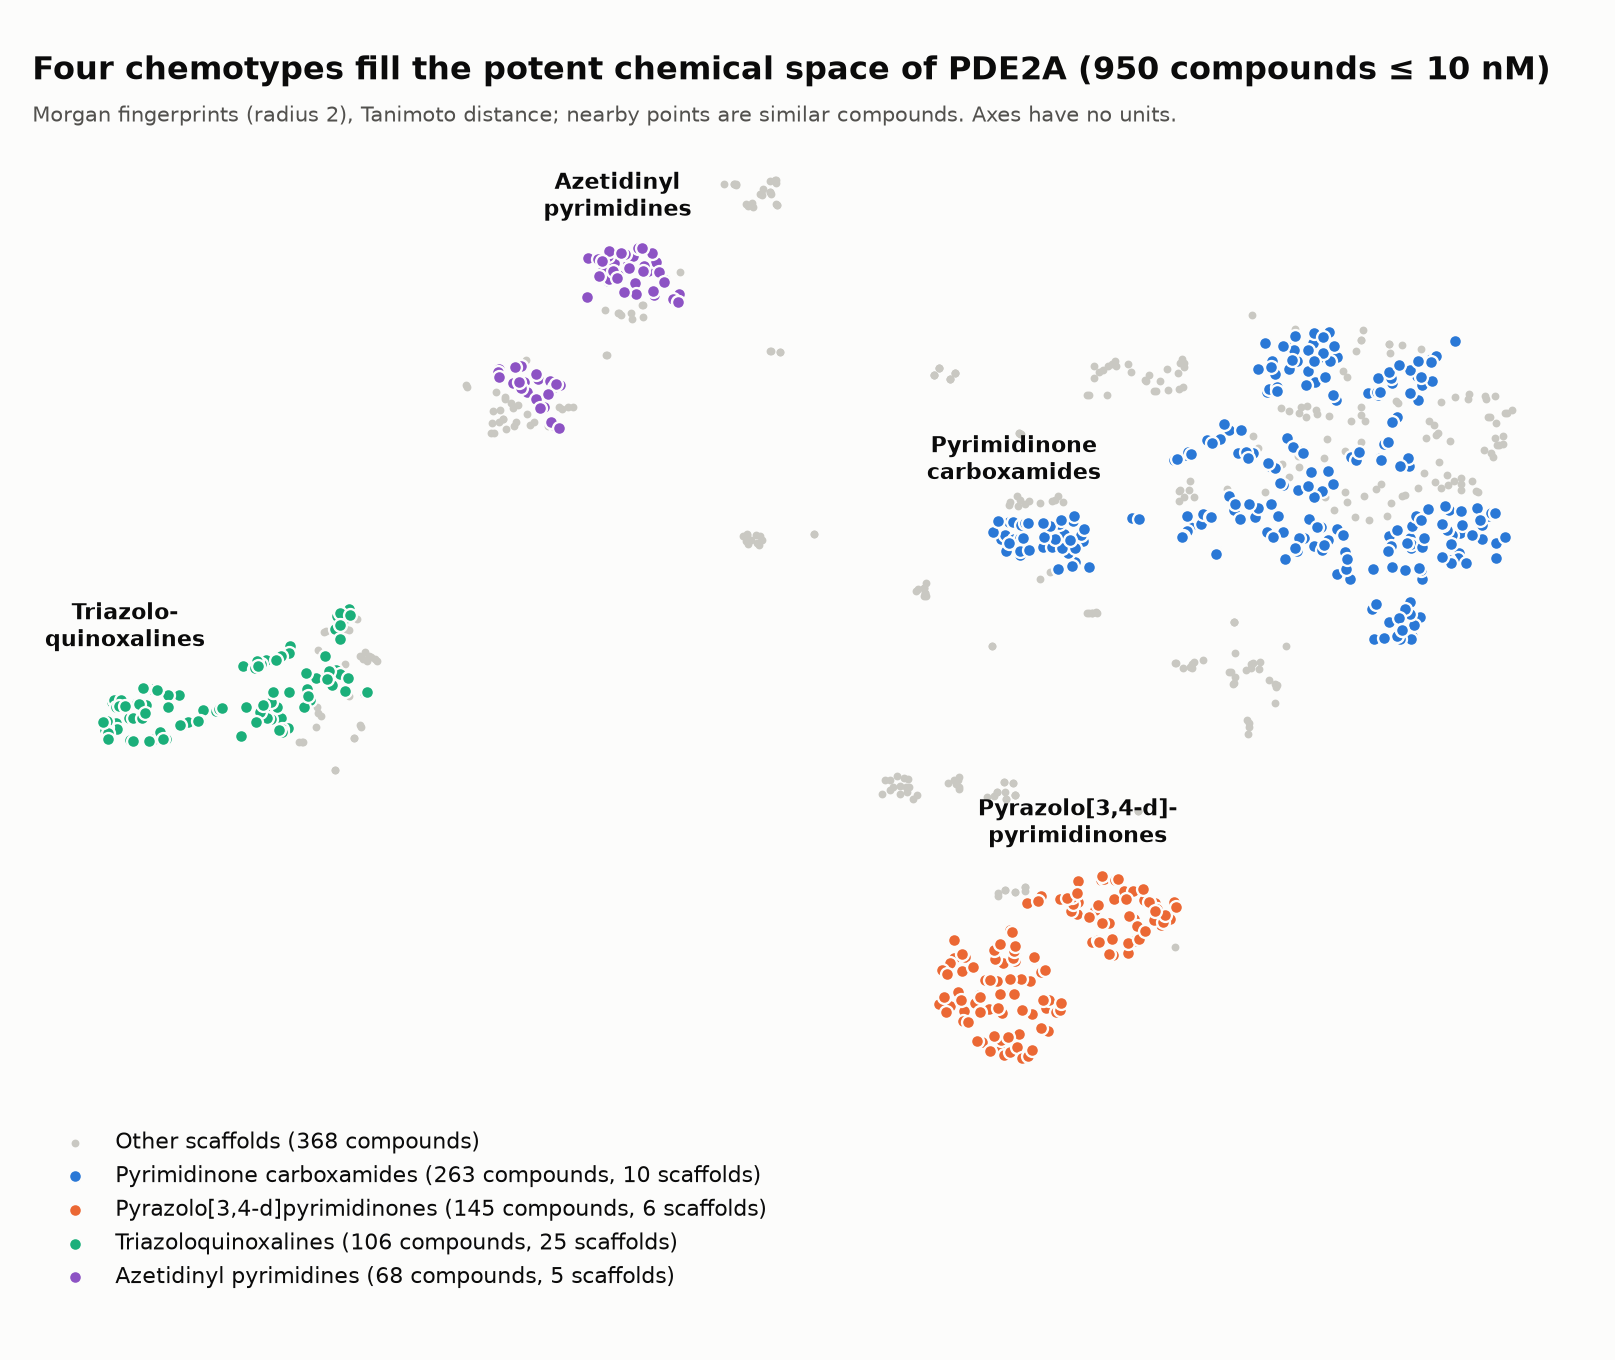

In [ ]:
# Code 1: t-SNE map of the potent PDE2A ligands, coloured by chemotype family
# The code is in plot_pde2a_tsne.py, next to this notebook (98 lines).
from plot_pde2a_tsne import *

plot_tsne(replay.result(7))

**🧠 Assistant**

950 compounds bind human PDE2A (target 788) at 10 nM or better, and they are unusually concentrated: 80% of them sit in scaffolds shared by five or more compounds, and just four chemotype families account for 582 of the 950. Figure 1 maps them: the four families take up their own regions of the map, though the largest is spread over several islands rather than one.

**The largest scaffold series**

| Scaffold | Compounds | Best pAffinity | Median pAffinity | Earliest source |
|---|---|---|---|---|
| O=c1[nH]cnc2c1cnn2Cc1ccccc1 | 115 | 10.80 | 9.38 | US10174037 (2019) |
| O=C(NCc1ccccc1)c1cc(=O)[nH]cn1 | 111 | 10.14 | 8.66 | US9815796 (2017) |
| O=C(NCc1ccccc1)c1cc(=O)[nH]c(-c2ccccc2)n1 | 41 | 9.30 | 8.54 | US9815796 (2017) |
| O=C(NCc1ccccc1)c1cc(=O)[nH]c(Cc2ccccc2)n1 | 39 | 9.31 | 8.82 | US9815796 (2017) |
| c1ccc(-c2nnc3cnc4ccccc4n23)cc1 | 37 | 9.55 | 8.30 | PMID 23260348 (2013) |
| c1ccc(-c2[nH]ncc2-c2ncn3ncnc(N4CCC4)c23)cc1 | 32 | 9.52 | 8.90 | US8598155 (2013) |
| O=C(NCc1ccccc1)c1cc(=O)[nH]c(-c2ncccn2)n1 | 26 | 8.89 | 8.30 | US9815796 (2017) |
| O=C(N\[C@@H](c1ccccc1)C1CC1)c1cc(=O)[nH]cn1 | 25 | 9.51 | 8.72 | US9815796 (2017) |

Reading down the first column, five of these eight are the same chemistry: a pyrimidin-6(1H)-one-4-carboxamide, differing only in what sits at position 2 (nothing, a phenyl, a benzyl, a pyrimidinyl) and in one case in the amide substituent. That is the first lesson below.

**Four families (Figure 1)**

Collapsing the scaffolds that share a core gives four families:

| Family | Compounds | Murcko scaffolds | Where it comes from |
|---|---|---|---|
| Pyrimidinone carboxamides | 263 | 10 | Patents US9815796 and US10285989 (2017–2019) |
| Pyrazolo[3,4-d]pyrimidinones | 145 | 6 | US10174037 (2019) |
| Triazoloquinoxalines | 106 | 25 | Papers from 2013 onwards (PMID 23260348, 25815146) |
| Azetidinyl pyrimidines | 68 | 5 | US8598155, US8829010 (2013–2014) |
| Everything else | 368 | 124 | - |

The t-SNE places the pyrazolopyrimidinones, triazoloquinoxalines and azetidinyl pyrimidines in clearly separate territories; the carboxamides, the biggest family, form several dense islands on one side of the map, with some of the grey remainder mixed in among them. Even the grey compounds break into small clusters rather than scattering. The reason is worth knowing before you generalise from it. PDE2A is a young CNS target whose chemistry comes almost entirely from patent series: a single patent contributes 50–100 close analogues at once, each a small variation on one core. A target with a long literature history looks nothing like this. The same query on four other targets:

| Target | Compounds ≤ 10 nM | Scaffolds | Scaffolds with one compound | In series of 5+ |
|---|---|---|---|---|
| PDE2A (788) | 950 | 170 | 94 | 80% |
| BTK (1846) | 6,326 | 2,478 | 1,629 | 50% |
| EGFR (520) | 3,151 | 1,262 | 809 | 47% |
| PDE5 (5066) | 770 | 352 | 255 | 46% |
| Dopamine D2 (5866) | 1,433 | 811 | 609 | 31% |

D2, with seventy years of medicinal chemistry behind it, is the opposite case: 609 of its 811 scaffolds hold a single compound, so a t-SNE of D2 is a dust cloud with a few islands in it. Decades of diverse published work scatter; a decade of patent series clusters.

**A lesson about Murcko scaffolds and ring substituents.** The carboxamide family is one chemical series by any chemist's reading, but group_by_scaffold returns it as 10 separate scaffolds. The cause is a rule, not a bug: a Bemis-Murcko scaffold keeps every ring system, so a phenyl or pyrimidinyl at position 2 becomes part of the scaffold, while a methyl or a dimethylamino at the same position disappears. Whether two analogues land in the same group depends on whether the group you varied happens to be a ring. Grouping by generic_scaffold (107 groups instead of 170) merges the 2-phenyl and 2-pyrimidinyl variants, since both reduce to the same carbon skeleton, but still separates the 2-benzyl one, which has an extra atom in the linker. For a question like "how large is this series", read the scaffold groups together with the map, or match the core with substructure_search.

**A lesson about target names in the PDE family.** BindingDB calls PDE2A "cGMP-dependent 3',5'-cyclic phosphodiesterase" and PDE5A "cGMP-specific 3',5'-cyclic phosphodiesterase": one word apart, and neither contains "PDE2" or "PDE5". search_targets resolves the gene name, but it is worth confirming the UniProt accession (O00408 for PDE2A, O76074 for PDE5A) before running an analysis. The isoform and construct entries (PDE2A2, the [574-941] catalytic domain) and the macaque, rat and bovine entries are separate targets with far fewer compounds each.

**How this was answered**

- search_targets for "PDE2A" gave target 788 (O00408, 3,883 measurements).
- find_ligands_for_target with max_value_nm: 10 and group_by_scaffold: true grouped the potent ligands by the scaffold column of compound_property, which holds RDKit's Bemis-Murcko scaffold of each parent structure; the same call with generic_scaffold: true gave the carbon-skeleton grouping.
- run_sql queries gave each large scaffold's earliest source, and listed every scaffold in the carboxamide family with its generic scaffold, to see which variants merge.
- A further query compared the concentration of potent chemistry across five targets.
- The compounds and their scaffolds were exported with run_sql, fingerprinted with RDKit, laid out with scikit-learn's t-SNE on Jaccard distances (plot_pde2a_tsne.py, pde2a_potent_ligands.csv), and added as Figure 1 with add_figure.

**Try next**

- "Show me one compound from each family" (the follow-up below)
- "Are the carboxamides selective over PDE10A?" (find_targets_for_compound on the best of each family)
- Example 2.5 maps a single scaffold across targets, the reverse of this question.

## Exchange 2

**👤 User**

Show me one compound from each family with its potency.

In [ ]:
# Call 8 · search_compounds · ran 2026-11-24 04:56:15 UTC
await replay.call(8, 'search_compounds', {'query': 'BAY 60-7550', 'limit': 5},
                  sha256='ea5a93bfea44e809434319cadcb0e0e08b6d81ceccb228d717c127c0d305cba7')

**Call 8** · `search_compounds` · recorded result · sha256 `ea5a93bfea44…`

_1 row_

| monomerid | bdbm_id | name | inchi_key | smiles | mol_weight | n_activities | n_targets | matched_name |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 50166893 | BDBM50166893 | BAY-60-7550 | MYTWFJKBZGMYCS-NQIIRXRSSA-N | Cc1c2n(c(n1)\[C@@H\](CCCc3ccccc3)\[C@@H\](C)O)N=C(NC2=O)Cc4ccc(c(c4)OC)OC | 476.24 | 17 | 2 | US11419874, BAY 60-7550 |


In [ ]:
# Call 9 · run_sql · ran 2026-11-24 04:56:15 UTC
sql = """
    WITH reps(label, monomerid) AS (VALUES ('Pyrimidinone carboxamide',384991),('Pyrazolo[3,4-d]pyrimidinone',320811),('Triazoloquinoxaline',50425140),('Azetidinyl pyrimidine',107776),('BAY 60-7550',50166893))
    SELECT r.label, r.monomerid, c.smiles, cp.heavy_atoms, cp.clogp, a.affinity_type, median(a.value) AS median_nm, count(*) AS n, min(a.year) AS first_year, string_agg(DISTINCT a.source_id, ', ') AS sources
    FROM reps r JOIN compound c USING (monomerid) JOIN compound_property cp USING (monomerid)
    JOIN activity a ON a.monomerid = r.monomerid AND a.polymerid = 788 AND a.relation = '=' AND a.unit = 'nM' AND a.affinity_type IN ('Ki','Kd','IC50','EC50')
    GROUP BY r.label, r.monomerid, c.smiles, cp.heavy_atoms, cp.clogp, a.affinity_type ORDER BY r.monomerid
    
"""
await replay.call(9, 'run_sql', {'sql': sql, 'limit': 50},
                  sha256='2e8d40d0a49b9c66144609c3aa80b931826aa79f8639960dca37eac100f91a62')

**Call 9** · `run_sql` · recorded result · sha256 `2e8d40d0a49b…`

_5 rows_

| label | monomerid | smiles | heavy_atoms | clogp | affinity_type | median_nm | n | first_year | sources |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Azetidinyl pyrimidine | 107776 | Cc1nc(-c2cnn(C)c2-c2ccc(cc2)C(F)(F)F)c2c(ncnn12)N1CCC1 | 30 | 3.73 | IC50 | 0.3015 | 2 | 2013 | 29293004, US8598155-B2 |
| Pyrazolo\[3,4-d\]pyrimidinone | 320811 | CCC(c1ccc(C(C)(F)F)c(F)c1)n1nc(CF)c2c(=O)\[nH\]c(N(C)C)nc21 | 29 | 3.91 | Ki | 0.558 | 2 | 2019 | US10174037-B2 |
| Pyrimidinone carboxamide | 384991 | CN(C)c1nc(C(=O)N\[C@@H\](c2ccc(S(F)(F)(F)(F)F)cc2)C(C)(C)O)cc(=O)\[nH\]1 | 30 | 3.74 | Ki | 0.073 | 1 | 2019 | US10285989-B2 |
| BAY 60-7550 | 50166893 | Cc1c2n(c(n1)\[C@@H\](CCCc3ccccc3)\[C@@H\](C)O)N=C(NC2=O)Cc4ccc(c(c4)OC)OC | 35 | 3.82 | IC50 | 4.7 | 16 | 2005 | 28796496, US11419874-B2, US10543194-B2, US10105349-B2, 15887951, 28574706, 26908025, 40015121, 29601185, 28759228, 30554955, 38614063, 28165743 |
| Triazoloquinoxaline | 50425140 | CCNC(=O)c1ccc2nc(C)c3nnc(-c4c(Cl)cccc4Cl)n3c2c1 | 27 | 4.31 | IC50 | 0.28 | 1 | 2013 | 23260348 |


**Figure 2: One compound from each of the four families, and BAY 60-7550.** _(as recorded)_

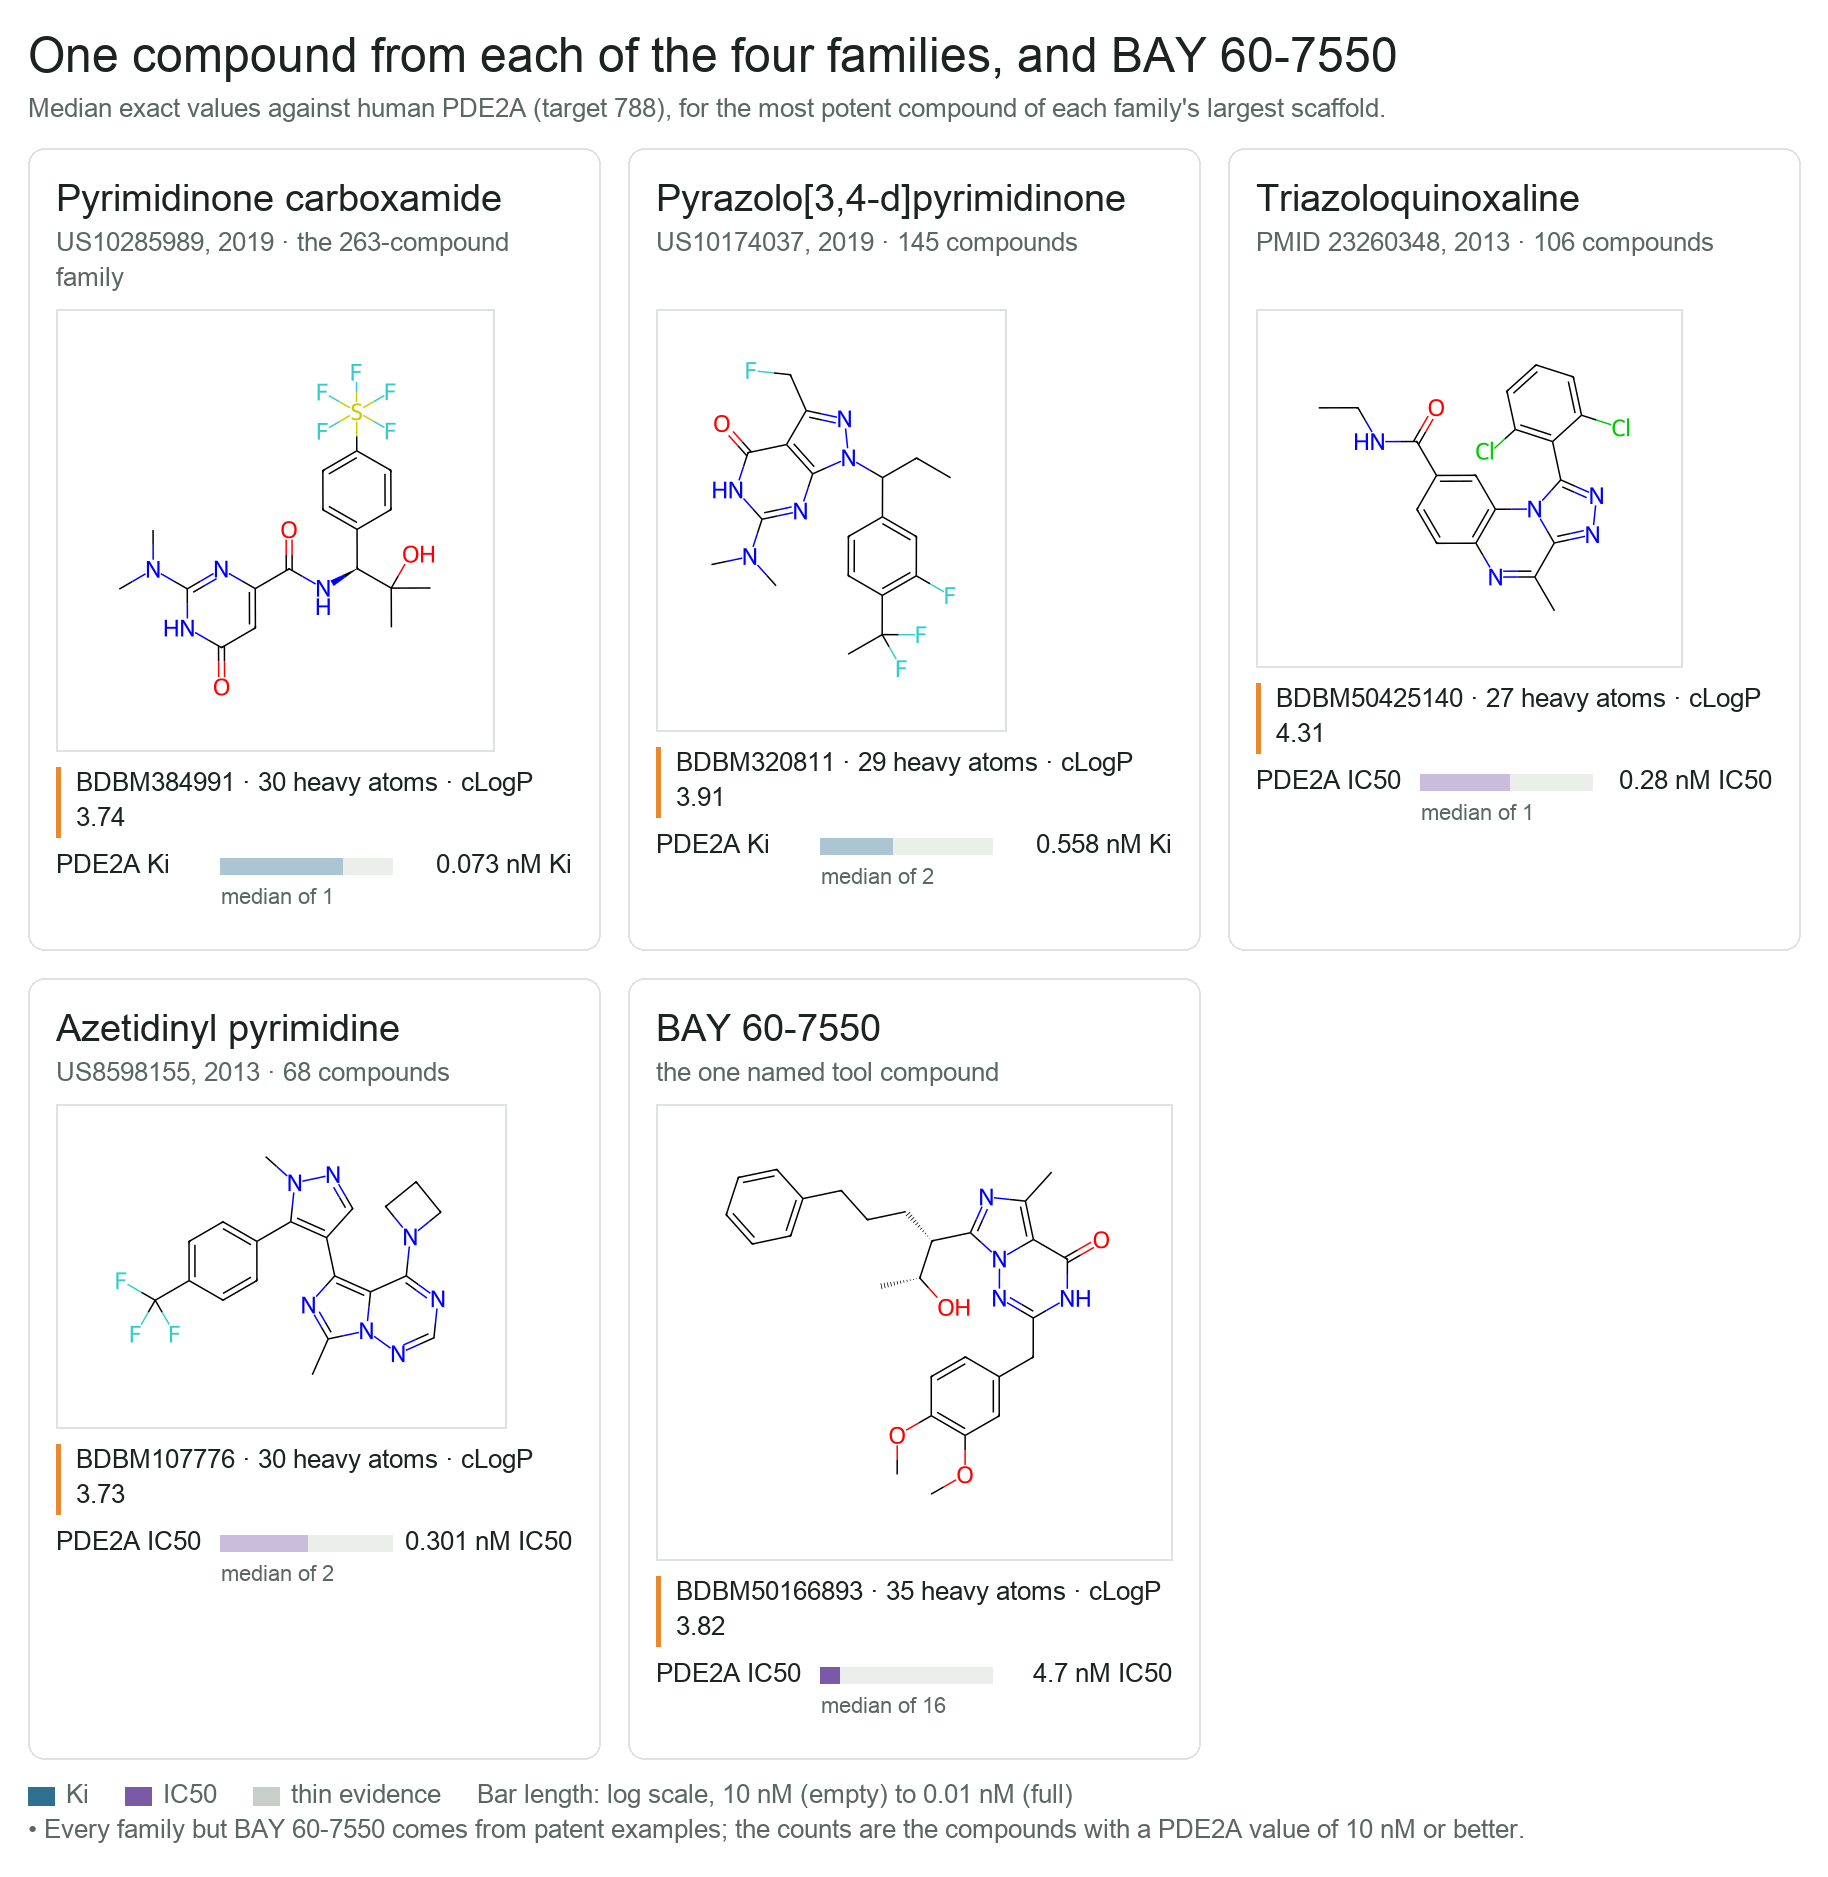

In [ ]:
# Figure 2 · draw_structure_grid draws it again
arguments = {
    'title': 'One compound from each of the four families, and BAY 60-7550',
    'compounds': [
        {
            'smiles': 'CN(C)c1nc(C(=O)N[C@@H](c2ccc(S(F)(F)(F)(F)F)cc2)C(C)(C)O)cc(=O)[nH]1',
            'title': 'Pyrimidinone carboxamide',
            'subtitle': 'US10285989, 2019 · the 263-compound family',
            'caption': 'BDBM384991 · 30 heavy atoms · cLogP 3.74',
            'bars': [
                {
                    'label': 'PDE2A Ki',
                    'value_nm': 0.073,
                    'type': 'Ki',
                    'note': 'median of 1',
                    'faint': True,
                },
            ],
        },
        {
            'smiles': 'CCC(c1ccc(C(C)(F)F)c(F)c1)n1nc(CF)c2c(=O)[nH]c(N(C)C)nc21',
            'title': 'Pyrazolo[3,4-d]pyrimidinone',
            'subtitle': 'US10174037, 2019 · 145 compounds',
            'caption': 'BDBM320811 · 29 heavy atoms · cLogP 3.91',
            'bars': [
                {
                    'label': 'PDE2A Ki',
                    'value_nm': 0.558,
                    'type': 'Ki',
                    'note': 'median of 2',
                    'faint': True,
                },
            ],
        },
        {
            'smiles': 'CCNC(=O)c1ccc2nc(C)c3nnc(-c4c(Cl)cccc4Cl)n3c2c1',
            'title': 'Triazoloquinoxaline',
            'subtitle': 'PMID 23260348, 2013 · 106 compounds',
            'caption': 'BDBM50425140 · 27 heavy atoms · cLogP 4.31',
            'bars': [
                {
                    'label': 'PDE2A IC50',
                    'value_nm': 0.28,
                    'type': 'IC50',
                    'note': 'median of 1',
                    'faint': True,
                },
            ],
        },
        {
            'smiles': 'Cc1nc(-c2cnn(C)c2-c2ccc(cc2)C(F)(F)F)c2c(ncnn12)N1CCC1',
            'title': 'Azetidinyl pyrimidine',
            'subtitle': 'US8598155, 2013 · 68 compounds',
            'caption': 'BDBM107776 · 30 heavy atoms · cLogP 3.73',
            'bars': [
                {
                    'label': 'PDE2A IC50',
                    'value_nm': 0.3015,
                    'type': 'IC50',
                    'note': 'median of 2',
                    'faint': True,
                },
            ],
        },
        {
            'smiles': 'Cc1c2n(c(n1)[C@@H](CCCc3ccccc3)[C@@H](C)O)N=C(NC2=O)Cc4ccc(c(c4)OC)OC',
            'title': 'BAY 60-7550',
            'subtitle': 'the one named tool compound',
            'caption': 'BDBM50166893 · 35 heavy atoms · cLogP 3.82',
            'bars': [{'label': 'PDE2A IC50', 'value_nm': 4.7, 'type': 'IC50', 'note': 'median of 16'}],
        },
    ],
    'columns': 3,
    'description': "Median exact values against human PDE2A (target 788), for the most potent compound of each family's largest scaffold.",
    'notes': [
        'Every family but BAY 60-7550 comes from patent examples; the counts are the compounds with a PDE2A value of 10 nM or better.',
    ],
    'min_core_atoms': 8,
    'min_core_share': 0.8,
}
await replay.figure(2, 'draw_structure_grid', arguments)

**🧠 Assistant**

Figure 2 shows one compound from each family, with BAY 60-7550 for reference. They share no common core: the largest substructure the five have in common is 7 atoms, below the 8-atom minimum for a shared core, so the grid draws each structure on its own, unaligned, with nothing highlighted. That matches the separate territories in Figure 1.

**What the four families have in common is not a scaffold.** Each carries a flat, electron-poor heterocycle with a lactam or amide carbonyl, the part that hydrogen-bonds to the invariant glutamine of the PDE active site, and hangs a lipophilic, usually fluorinated aryl group off it (the triazoloquinoxaline has a dichlorophenyl instead). The pharmacophore is conserved; the ring system carrying it is not. That is the pattern a scaffold grouping cannot see and a fingerprint map can: separate islands, one recurring binding motif.

**Potency and evidence.** The four patent and paper families reach sub-nanomolar potency (best pAffinity 9.3 to 10.8 in the scaffold table above), and the representatives in Figure 2 are all at or below 0.6 nM. Each rests on one or two exact measurements, from the patent or paper that reported it, so the bars are thin evidence by construction (the faint bars). BAY 60-7550 is the exception in every way: it is the only compound in the entire potent set with a name rather than a patent label or a ChEMBL id, it has 16 exact PDE2A IC50 values from 13 sources with a median of 4.7 nM, and it is the weakest of the five.

**A lesson about what BindingDB holds for a young target.** 582 of PDE2A's 950 potent compounds come from four families of patents and papers filed between 2013 and 2019. That is where this target's chemistry lives, and BindingDB curates it, which is why the landscape looks the way it does. Two consequences for analysing any target like this:

- **Compound names are not names.** "US10285989, Example 14" tells you the patent, not what anyone calls the molecule, and a search by drug name finds nothing at all.
- **Measurement counts are not evidence weight in the usual sense.** One hundred compounds measured once each, in one assay, in one laboratory, is not the same body of evidence as twenty compounds measured in twenty laboratories. Both are rows in activity.

**How this was answered**

- A run_sql query took the SMILES, heavy-atom count, cLogP and median exact PDE2A value of one representative per family (the most potent compound of each family's largest scaffold, as find_ligands_for_target listed them), plus BAY 60-7550, found with search_compounds.
- draw_structure_grid drew them without align_to. With no core to pass, it looks for the largest common substructure, which for these five is 7 atoms, too small to count, so the figure is unaligned.

**Try next**

- "Which of these also inhibit PDE10A or PDE3A?" (find_targets_for_compound on each)
- "How selective is the carboxamide family across the PDE family?" (substructure_search for the core with summarize_by_target: true)
- Example 7.5 narrows a similarity search with property filters, starting from a marketed drug instead of a patent example.

## Verification

How each rerun call compared with its recorded result.

In [ ]:
replay.summary()

_Recorded: 9 tool calls, 1 figure to redraw. Run all cells to compare._

## How to cite

Cite this notebook (for example deposited with a DOI) together with the data and software it ran on:

- Data: BindingDB release 202611, https://www.bindingdb.org/rwd/bind/BDB-mySQL_All_202611_dmp.zip (SHA-256 daea9260d404919a183ce02d91bf4b9c49b410bea7eaaeba105c8e0280510381)
- Software: mcp-bindingdb v0.1.17, commit 79dae5d22c0f15b8ded9b49adc8b105f0463703a, https://github.com/sbl-sdsc/mcp-bindingdb
- Analysis: Example 7.3 — Scaffold landscape and chemical space: PDE2A inhibitors, 2026-11-23, with claude-sonnet-5-5
- BindingDB: Liu T, Hwang L, Burley SK, Nitsche CI, Southan C, Walters WP, Gilson MK. BindingDB in 2024: a FAIR knowledgebase of protein-small molecule binding data. Nucleic Acids Research 53(D1):D1633-D1644, 2025. https://doi.org/10.1093/nar/gkae1075

As BibTeX, for this server, BindingDB and RDKit (used for structure search, properties and drawings):

```bibtex
@software{rose2026mcp-bindingdb,
  title={MCP BindingDB Server},
  author={Rose, P.W.},
  year={2026},
  url={https://github.com/sbl-sdsc/mcp-bindingdb}
}

@article{liu2025bindingdb,
  title={BindingDB in 2024: a FAIR knowledgebase of protein-small molecule binding data},
  author={Liu, T. and Hwang, L. and Burley, S.K. and Nitsche, C.I. and Southan, C. and Walters, W.P. and Gilson, M.K.},
  journal={Nucleic Acids Research},
  volume={53},
  number={D1},
  pages={D1633--D1644},
  year={2025},
  doi={10.1093/nar/gkae1075}
}

@software{rdkit,
  title={RDKit: Open-source cheminformatics},
  author={Landrum, G. and others},
  version={2026.03.6},
  url={https://www.rdkit.org},
  doi={10.5281/zenodo.591637}
}
```